# GNSS signal processing: from the antenna to a position

**A lecture on the GPS L1 C/A signal, with one simulated recording that goes through the whole receiver.**

A GNSS receiver finds its position by measuring how long radio signals took to arrive from several satellites. Each satellite carries an atomic clock and broadcasts, in effect, "this is the time on my clock, and this is where I am". Light travels 300 m in one microsecond, so a position good to a few metres needs travel times good to about 10 nanoseconds.

Three things make this a signal-processing problem:

1. **The signal is weaker than the noise.** At the antenna, a GPS signal is about 15 dB *below* the thermal noise in its own band. Nothing is visible in the raw samples.
2. **All satellites transmit on the same frequency at the same time.** The receiver has to pull them apart.
3. **The timing must be far finer than the data.** The message arrives at 50 bit/s, but the travel time must be known to a few nanoseconds.

One idea solves all three: each satellite multiplies its message by a fast, known, noise-like sequence called a **spreading code**. This lecture follows that idea from the transmitter to the position.

## How the lecture is organised

The receiver is a chain. Each stage takes what the previous one produced and extracts the next piece of information:

| | Stage | Receives | Does | Hands on |
|---|---|---|---|---|
| 1 | Satellite | its clock, its orbit | builds code × data × carrier | a radio wave at 1575.42 MHz |
| 2 | Front end | the radio wave plus noise | shifts it to 0 Hz, samples it | 4 million complex samples per second |
| 3 | Acquisition | the samples | tries every code, delay and frequency | which satellites are there, roughly aligned |
| 4 | Tracking | the samples and that rough alignment | keeps a copy of the signal aligned, 1000 times per second | one complex number per millisecond, and the code timing |
| 5 | Bit and frame synchronisation | those numbers | finds where bits and subframes start | bits (50 per second), grouped in words |
| 6 | Message decoding | the words | checks them, unpacks the fields | the satellite's clock correction and orbit |
| 7 | Pseudoranges | the code timing and the message | reads each satellite's clock at one instant | one travel time per satellite |
| 8 | Position | travel times and orbits | solves four equations | position and time |

Before the chain, **part 0** introduces the form in which a receiver handles a radio signal: pairs of numbers called I and Q. Parts 1 and 2 build the signal and a **simulated recording**: 20 seconds of samples as a real front end would deliver them, with five satellites, noise, and a receiver whose position we know. Parts 3 to 5 are the receiver. It gets only the samples. At the end we compare the position it computes with the true one.

Every stage is written out in a few lines of `numpy`, so nothing is hidden in a library. The same map comes back at the start of each part, with the current stage highlighted.

**Running it.** `numpy`, `matplotlib` and `ipywidgets` are enough. Running everything takes one to two minutes (generating and tracking 80 million samples) and about 300 MB of memory. The figures are stored in the file, so it can also be read without running. Cells headed **Explore** are there to play with: sliders, step buttons, and films started with a **▶ play** button. They are stored without output and only work once the notebook has been run.

**Conventions**
- A logic bit $b \in \{0, 1\}$ is sent as the level $1 - 2b \in \{+1, -1\}$. With levels, the XOR of two bits becomes a multiplication.
- "GPS" here means the legacy civil signal, **L1 C/A**. The other GNSS signals (Galileo E1, GPS L5 and so on) use longer codes and other modulations, but the same chain.
- Field layouts, constants and algorithms follow the GPS interface specification **IS-GPS-200**.

## How to run this notebook

The notebook is self-contained: it needs no HackRF, no recording and nothing else from this repository. It builds its own signal.

1. **Install Python 3.10 or later**, then the three packages the notebook uses:

   ```
   pip install numpy matplotlib ipywidgets
   ```

2. **Open the file in a notebook editor.** Either of these works:
   - **VS Code** with the *Python* and *Jupyter* extensions: open the file, click **Select Kernel** (top right) and pick the Python where you installed the packages. VS Code offers to install `ipykernel` the first time: accept.
   - **JupyterLab**: `pip install jupyterlab`, run `jupyter lab` in this folder, and open the file from the browser page that appears.

3. **Run every cell, in order, from the top** (*Run All*). Each part uses what the parts before it computed, so a cell run on its own fails with a `NameError`. A full run takes one to two minutes and about 300 MB of memory.

4. **Play with the cells headed "Explore"**: sliders, step buttons and films with a play button. They only respond once the notebook has been run.

To read it without running anything, just scroll: the figures are stored in the file.

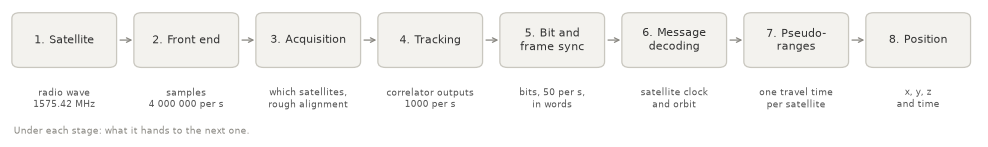

In [1]:
import time
from math import erfc

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, FancyBboxPatch, Rectangle
from IPython.display import Markdown, display
import ipywidgets as W

# One colour per role, the same in every figure
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948')
GREY, LIGHT, INK = '#898781', '#e4e2dc', '#333333'
plt.rcParams.update({
    'figure.dpi': 90, 'font.size': 9, 'axes.titlesize': 10, 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GREY,
    'axes.labelcolor': INK, 'xtick.color': GREY, 'ytick.color': GREY, 'xtick.labelcolor': INK,
    'ytick.labelcolor': INK, 'legend.frameon': False})

# The numbers that define GPS L1 C/A
C_LIGHT = 299_792_458.0     # m/s
F_L1 = 1575.42e6            # Hz, carrier frequency = 154 x 10.23 MHz
CHIP_RATE = 1.023e6         # chips per second = 10.23 MHz / 10
N = 1023                    # chips in one code period
T_CODE = N / CHIP_RATE      # s, one code period = 1 ms
T_BIT = 20 * T_CODE         # s, one data bit = 20 code periods

STAGES = [('Satellite', 'radio wave\n1575.42 MHz'), ('Front end', 'samples\n4 000 000 per s'),
          ('Acquisition', 'which satellites,\nrough alignment'),
          ('Tracking', 'correlator outputs\n1000 per s'), ('Bit and\nframe sync', 'bits, 50 per s,\nin words'),
          ('Message\ndecoding', 'satellite clock\nand orbit'), ('Pseudo-\nranges', 'one travel time\nper satellite'),
          ('Position', 'x, y, z\nand time')]

def pipeline_map(*current):
    """The chain of the lecture, with the stages of the current part highlighted."""
    fig = plt.figure(figsize=(11, 1.5))
    ax = fig.add_axes([0.01, 0.02, 0.98, 0.96])
    ax.set_xlim(-0.05, 10.05); ax.set_ylim(-0.8, 1.0); ax.axis('off')
    for i, (name, hands_on) in enumerate(STAGES):
        on, x = (i + 1) in current, i * 1.27
        ax.add_patch(FancyBboxPatch((x, 0.2), 1.05, 0.72, boxstyle='round,pad=0.02,rounding_size=0.08',
                                    fc=BLUE if on else '#f3f2ee', ec=BLUE if on else '#c9c7bf', lw=1))
        ax.text(x + 0.525, 0.56, f'{i + 1}. {name}', ha='center', va='center', fontsize=8.5,
                color='white' if on else INK, weight='bold' if on else 'normal')
        ax.text(x + 0.525, -0.25, hands_on, ha='center', va='center', fontsize=7.5, color='#555555')
        if i < len(STAGES) - 1:
            ax.annotate('', xy=(x + 1.26, 0.56), xytext=(x + 1.08, 0.56),
                        arrowprops=dict(arrowstyle='->', color=GREY, lw=1))
    ax.text(0, -0.74, 'Under each stage: what it hands to the next one.', fontsize=7.5, color=GREY)
    plt.show()

pipeline_map()

In [2]:
# Tools for the cells headed "Explore". They are not part of the lecture: skip them on a first reading.
#
# A figure that is erased and drawn again flickers, and the page jumps while it is missing. So each
# Explore cell owns one picture, and only the contents of that picture are replaced:
#   explore(draw, ...)    shows controls and, under them, the figure of draw(values), kept up to date
#   Quick(fig, moving)    a figure in which only a few artists move: a new picture in about 15 ms
#   play_button(slider)   a button that moves a slider by itself, to play a figure like a film
import asyncio
import io

from matplotlib.backends.backend_agg import FigureCanvasAgg

FULL_LABEL = {'description_width': 'initial'}      # show the whole label of a control, whatever its length

def slider(label, value, low, high, step=1, width='340px'):
    whole = all(isinstance(v, int) for v in (value, low, high, step))
    return (W.IntSlider if whole else W.FloatSlider)(
        value=value, min=low, max=high, step=step, description=label, style=FULL_LABEL,
        layout=W.Layout(width=width))

def choice(label, options, value):
    return W.Dropdown(options=options, value=value, description=label, style=FULL_LABEL,
                      layout=W.Layout(width='auto'))

def figure_png(fig):
    """A figure as a PNG image, always of the same size (so that one picture can replace another)."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', pil_kwargs=dict(compress_level=1))      # lightly compressed: quicker to make
    return buf.getvalue()

class Quick:
    """A figure in which only the artists listed in `moving` change from one picture to the next.
    Everything else is drawn once and kept as a background."""

    def __init__(self, fig, moving):
        plt.close(fig)                                   # never shown by itself: only through png()
        FigureCanvasAgg(fig)
        for artist in moving:
            artist.set_animated(True)                    # left out of the background
        fig.canvas.draw()
        self.fig, self.moving = fig, moving
        self.background = fig.canvas.copy_from_bbox(fig.bbox)

    def png(self):
        self.fig.canvas.restore_region(self.background)
        for artist in self.moving:
            self.fig.draw_artist(artist)
        buf = io.BytesIO()
        plt.imsave(buf, np.asarray(self.fig.canvas.buffer_rgba()), format='png', pil_kwargs=dict(compress_level=3))
        return buf.getvalue()

PLANNED = []        # the redraws that are planned and not yet done

def explore(draw, *more, **controls):
    """Show the controls and, under them, the figure that draw(**values of the controls) makes.
    The figure is drawn again whenever a control changes. draw can show a figure with plt.show()
    (like the figures of the lecture) or return PNG bytes (see Quick). `more` are other widgets
    to show after the controls, such as buttons."""
    picture = W.Image(format='png', layout=W.Layout(max_width='100%'))
    waiting, cost = [], [0.0]                            # a redraw that is planned; how long the last one took (s)

    def redraw():
        for plan in waiting:
            PLANNED.remove(plan)
        waiting.clear()
        began = time.time()
        show, plt.show = plt.show, lambda *args, **kwargs: None     # the figure goes into `picture`, not under the cell
        try:
            made = draw(**{name: control.value for name, control in controls.items()})
            if not isinstance(made, bytes):
                fig = plt.gcf()
                made = figure_png(fig)
                plt.close(fig)
        finally:
            plt.show = show
        picture.value = made
        cost[0] = time.time() - began

    def changed(_):
        # Several changes can arrive while one picture is being drawn (a slider dragged quickly). Wait a
        # moment before drawing, longer for a figure that is slow to draw, and then use the latest values
        if not waiting:
            try:
                waiting.append(asyncio.get_running_loop().call_later(min(max(0.01, 0.4 * cost[0]), 0.1), redraw))
                PLANNED.append(waiting[0])
            except RuntimeError:                         # no event loop: draw at once
                redraw()

    for control in controls.values():
        control.observe(changed, 'value')
    redraw()
    display(W.VBox([W.HBox([*controls.values(), *more], layout=W.Layout(flex_flow='row wrap', align_items='center')),
                    picture]))

PLAYING = []        # the button that is playing now: one film at a time

def play_button(slider, per_second=25, label='▶ play'):
    """A button that advances `slider` by one step, per_second times per second, up to its end.
    per_second is a number, or a control whose value is read at every step."""
    button = W.ToggleButton(description=label, layout=W.Layout(width='110px'))
    tasks = []

    async def advance():
        if slider.value >= slider.max:
            slider.value = slider.min                    # at the end: start again
        while button.value and slider.value < slider.max:
            slider.value = min(slider.value + slider.step, slider.max)
            await asyncio.sleep(1 / getattr(per_second, 'value', per_second))
            while PLANNED:                               # never run ahead of the pictures
                await asyncio.sleep(0.005)
        button.value = False

    def pressed(change):
        button.description = '⏸ pause' if change['new'] else label
        if change['new']:
            for other in PLAYING:
                if other is not button:
                    other.value = False
            PLAYING[:] = [button]
            if not tasks or tasks[-1].done():
                tasks[:] = [asyncio.ensure_future(advance())]

    button.observe(pressed, 'value')
    return button

# Part 0. Before the chain: what I and Q are

The table above says that the front end hands on *complex* samples, and most figures of parts 3 and 4 are drawn with two quantities called **I** and **Q**. This part explains what they are before the lecture starts using them. It needs nothing about GPS: only a sine wave.

## 0.1 One number per instant is not enough

A radio signal near a frequency $f_c$ is a sine wave whose **amplitude** $a$ and **phase** $\varphi$ change slowly:

$$s(t) = a(t)\,\cos\big(2\pi f_c\,t + \varphi(t)\big)$$

The frequency $f_c$ is known in advance and carries no information. Everything the transmitter has to say is in the two slow quantities $a(t)$ and $\varphi(t)$. For GPS it is all in the phase: part 1 will show a carrier whose phase jumps by 180°.

Now measure $s$ at one instant. That gives one number, and one number cannot give back two. Take the instant $t = 0$, a crest of the reference wave $\cos(2\pi f_c t)$. A reading of 0.5 there can come from a wave of amplitude 1 that passed its crest 60° ago, from a wave of amplitude 1 that will reach its crest in 60°, or from a wave of amplitude 0.5 exactly at its crest. The left panel below shows the three. To describe a wave at an instant we need **two numbers**.

## 0.2 The two numbers

Expand the cosine of a sum, $\cos(\alpha + \varphi) = \cos\alpha\,\cos\varphi - \sin\alpha\,\sin\varphi$, with $\alpha = 2\pi f_c t$:

$$s(t) = \underbrace{a\cos\varphi}_{I}\;\cos(2\pi f_c t)\;-\;\underbrace{a\sin\varphi}_{Q}\;\sin(2\pi f_c t)$$

So any wave at $f_c$, whatever its amplitude and phase, is a mixture of two fixed reference waves, a cosine and a sine. The two weights say everything about it:

- $I = a\cos\varphi$ is the **in-phase** component: how much of the wave is in step with the reference cosine.
- $Q = a\sin\varphi$ is the **quadrature** component: how much of it is a quarter of a cycle (90°) away from the reference.

Draw $(I, Q)$ as a point in a plane (right panel). Its distance from the centre is the amplitude and its angle is the phase:

$$a = \sqrt{I^2 + Q^2} \qquad\qquad \varphi = \operatorname{atan2}(Q,\, I)$$

A point of a plane given by a distance and an angle is a complex number, so the pair is written as one:

$$x = I + jQ = a\,e^{j\varphi} \qquad\text{and}\qquad s(t) = \mathrm{Re}\!\left[\,x(t)\;e^{\,j 2\pi f_c t}\right]$$

(the second form is the first equation again, by Euler's formula $e^{j\theta} = \cos\theta + j\sin\theta$). $x(t)$ is the signal with the carrier taken out. It moves slowly, and it is the only thing a receiver needs to keep.

The three waves that all read 0.5 are three different points of the plane. They share the same $I$, which is what the single reading measured, and differ by $Q$.

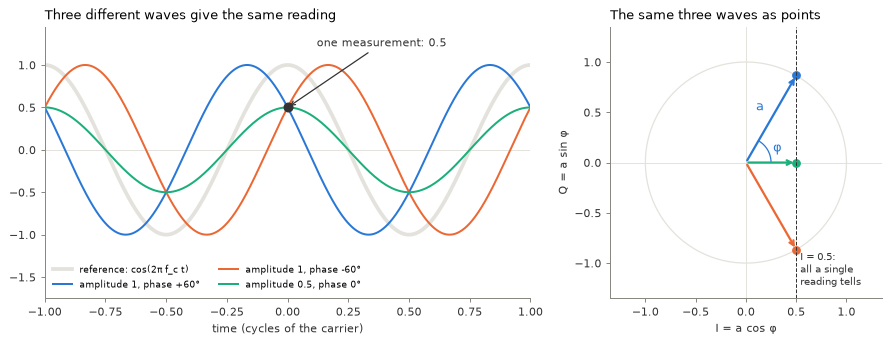

In [3]:
def fig_two_numbers():
    cases = [(1.0, 60, BLUE), (1.0, -60, ORANGE), (0.5, 0, AQUA)]        # amplitude, phase (degrees), colour
    fig, (ax, az) = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw=dict(width_ratios=[1.75, 1]))
    cycles = np.linspace(-1, 1, 801)                                     # time, in cycles of the carrier
    ax.plot(cycles, np.cos(2 * np.pi * cycles), color=LIGHT, lw=3, label='reference: cos(2π f_c t)')
    circle = np.exp(2j * np.pi * np.linspace(0, 1, 200))
    az.plot(circle.real, circle.imag, color=LIGHT, lw=1)
    for a, degrees, colour in cases:
        phase = np.radians(degrees)
        ax.plot(cycles, a * np.cos(2 * np.pi * cycles + phase), color=colour, lw=1.6,
                label=f'amplitude {a:g}, phase {degrees:+d}°'.replace('+0', '0'))
        I, Q = a * np.cos(phase), a * np.sin(phase)
        az.annotate('', xy=(I, Q), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=colour, lw=1.8))
        az.plot(I, Q, 'o', color=colour, ms=6)
    ax.plot(0, 0.5, 'o', color=INK, ms=7, zorder=5)
    ax.annotate('one measurement: 0.5', (0, 0.5), xytext=(0.12, 1.22), fontsize=8.5, color=INK,
                arrowprops=dict(arrowstyle='->', color=INK))
    ax.axhline(0, color=LIGHT, lw=0.8, zorder=0)
    ax.set_xlim(-1, 1); ax.set_ylim(-1.75, 1.45); ax.set_xlabel('time (cycles of the carrier)')
    ax.set_title('Three different waves give the same reading'); ax.legend(loc='lower left', fontsize=7.5, ncol=2)
    az.axhline(0, color=LIGHT, lw=0.8, zorder=0); az.axvline(0, color=LIGHT, lw=0.8, zorder=0)
    az.axvline(0.5, color=INK, ls='--', lw=0.8)
    az.text(0.54, -1.25, 'I = 0.5:\nall a single\nreading tells', fontsize=8, color=INK, va='bottom')
    az.add_patch(Arc((0, 0), 0.5, 0.5, theta1=0, theta2=60, color=BLUE, lw=1))
    az.text(0.27, 0.11, 'φ', fontsize=10, color=BLUE)
    az.text(0.1, 0.52, 'a', fontsize=10, color=BLUE)
    az.set_xlim(-1.35, 1.35); az.set_ylim(-1.35, 1.35); az.set_aspect('equal')
    az.set_xlabel('I = a cos φ'); az.set_ylabel('Q = a sin φ')
    az.set_title('The same three waves as points')
    fig.tight_layout(); plt.show()

fig_two_numbers()

## 0.3 How a receiver measures I and Q

The receiver knows neither $a$ nor $\varphi$. It gets $I$ and $Q$ out of $s(t)$ by multiplying it by its own two reference waves, made by a **local oscillator** at $f_c$. With $\alpha = 2\pi f_c t$ and the identities $2\cos^2\alpha = 1 + \cos 2\alpha$, $\;2\sin^2\alpha = 1 - \cos 2\alpha\;$ and $\;2\sin\alpha\cos\alpha = \sin 2\alpha$:

$$s(t)\cdot 2\cos\alpha \;=\; 2I\cos^2\alpha - 2Q\sin\alpha\cos\alpha \;=\; I \;+\; \big[\,I\cos 2\alpha - Q\sin 2\alpha\,\big]$$

$$s(t)\cdot(-2\sin\alpha) \;=\; -2I\sin\alpha\cos\alpha + 2Q\sin^2\alpha \;=\; Q \;-\; \big[\,Q\cos 2\alpha + I\sin 2\alpha\,\big]$$

Each product is the component we want, plus terms that oscillate at twice the carrier frequency. Averaging over a few carrier cycles (a **low-pass filter**) removes those terms and leaves $I$ and $Q$, provided they change slowly compared with the carrier. This is called **mixing down**, and it is the heart of every radio front end, the HackRF One included.

The cell below checks it with numbers. It builds a wave from an amplitude and a phase that we choose, mixes it down, and compares what comes out with $a\cos\varphi$ and $a\sin\varphi$.

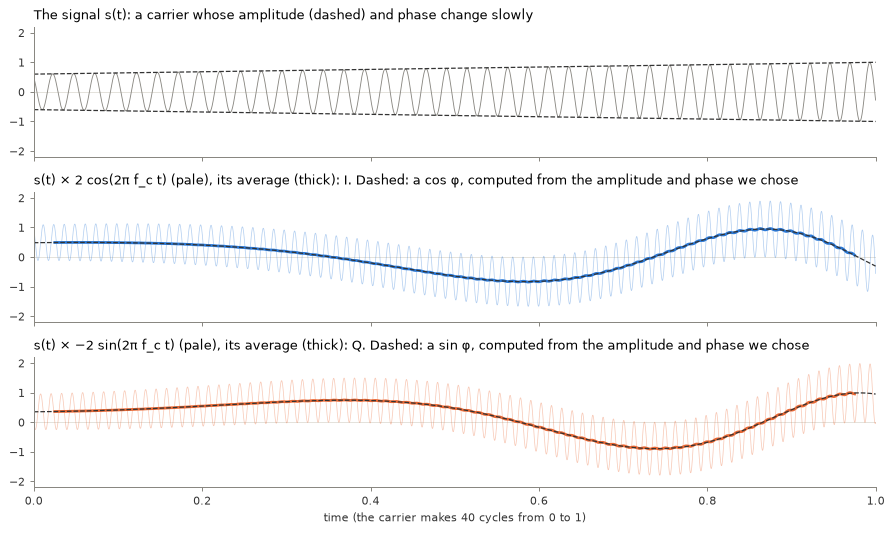

Largest difference between the measured I, Q and a cos φ, a sin φ: 0.033 (the amplitude is about 1).


In [4]:
def mix_down(s, t, f_c):
    """I and Q of the real signal s(t): multiply by the two reference waves, average over one carrier cycle."""
    n = int(round(1 / f_c / (t[1] - t[0])))                 # samples in one cycle of the carrier
    average = lambda y: np.convolve(y, np.ones(n) / n, mode='same')
    by_cos = s * 2 * np.cos(2 * np.pi * f_c * t)
    by_sin = s * -2 * np.sin(2 * np.pi * f_c * t)
    return average(by_cos), average(by_sin), by_cos, by_sin

def fig_mix_down(f_c=40.0):
    t = np.arange(8000) / 8000                              # one unit of time; the carrier makes 40 cycles in it
    a = 0.6 + 0.4 * t                                       # an amplitude that grows slowly
    phase = 2 * np.pi * (0.1 + 1.2 * t ** 2)                # a phase that turns, faster and faster
    s = a * np.cos(2 * np.pi * f_c * t + phase)             # the radio signal: all the receiver gets
    I, Q, by_cos, by_sin = mix_down(s, t, f_c)
    inside = slice(200, -200)                               # the average is incomplete at the two ends
    worst = max(np.abs(I - a * np.cos(phase))[inside].max(), np.abs(Q - a * np.sin(phase))[inside].max())
    fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    axs[0].plot(t, s, color=GREY, lw=0.7)
    axs[0].plot(t, a, color=INK, lw=1, ls='--'); axs[0].plot(t, -a, color=INK, lw=1, ls='--')
    axs[0].set_title('The signal s(t): a carrier whose amplitude (dashed) and phase change slowly')
    for ax, product, found, true, colour, name, wave in [
            (axs[1], by_cos, I, a * np.cos(phase), BLUE, 'I', '2 cos(2π f_c t)'),
            (axs[2], by_sin, Q, a * np.sin(phase), ORANGE, 'Q', '−2 sin(2π f_c t)')]:
        ax.plot(t, product, color=colour, lw=0.6, alpha=0.35)
        ax.plot(t[inside], found[inside], color=colour, lw=2.2)
        ax.plot(t, true, color=INK, lw=1, ls='--')
        ax.set_title(f's(t) × {wave} (pale), its average (thick): {name}. Dashed: a {"cos" if name == "I" else "sin"} φ, '
                     'computed from the amplitude and phase we chose')
    for ax in axs:
        ax.set_ylim(-2.2, 2.2); ax.axhline(0, color=LIGHT, lw=0.8, zorder=0)
    axs[2].set_xlim(0, 1); axs[2].set_xlabel('time (the carrier makes 40 cycles from 0 to 1)')
    fig.tight_layout(); plt.show()
    print(f'Largest difference between the measured I, Q and a cos φ, a sin φ: {worst:.3f} (the amplitude is about 1).')

fig_mix_down()

The thick curves follow the dashed ones: multiplying and averaging did recover $a\cos\varphi$ and $a\sin\varphi$ from the signal alone. The small difference left is the price of averaging a quantity that moves a little during one carrier cycle. At GPS frequencies there are more than a thousand carrier cycles in the fastest change of the signal, and the difference is negligible.

## 0.4 A frequency offset is a rotation, and Q gives its direction

Suppose the wave is not exactly at $f_c$ but a little beside it, at $f_c + \Delta f$:

$$s(t) = a\cos\big(2\pi (f_c + \Delta f)\,t\big) = a\cos\big(2\pi f_c t + \underbrace{2\pi\,\Delta f\, t}_{\varphi(t)}\big) \qquad\Longrightarrow\qquad x(t) = a\,e^{\,j 2\pi \Delta f\, t}$$

The phase grows steadily, so the point $(I, Q)$ goes round a circle, $\Delta f$ turns per second. It turns **anticlockwise if the wave is above the reference** ($\Delta f > 0$) and **clockwise if it is below**.

This is the reason for having two components. $I = a\cos(2\pi\Delta f\,t)$ is exactly the same for $+\Delta f$ and $-\Delta f$, because a cosine does not change when its angle changes sign. Only $Q = a\sin(2\pi\Delta f\,t)$ tells them apart: it is a quarter of a cycle behind $I$ in one case and ahead of it in the other. For GPS, this is the difference between a satellite that approaches (its signal arrives a few kHz too high) and one that moves away.

The same fact, seen as a spectrum: $I$ alone has two lines, at $+\Delta f$ and at $-\Delta f$. The complex signal $I + jQ$ has one line, on the correct side. This is also why $f_s$ complex samples per second can describe a band $f_s$ wide, from $-f_s/2$ to $+f_s/2$ around $f_c$.

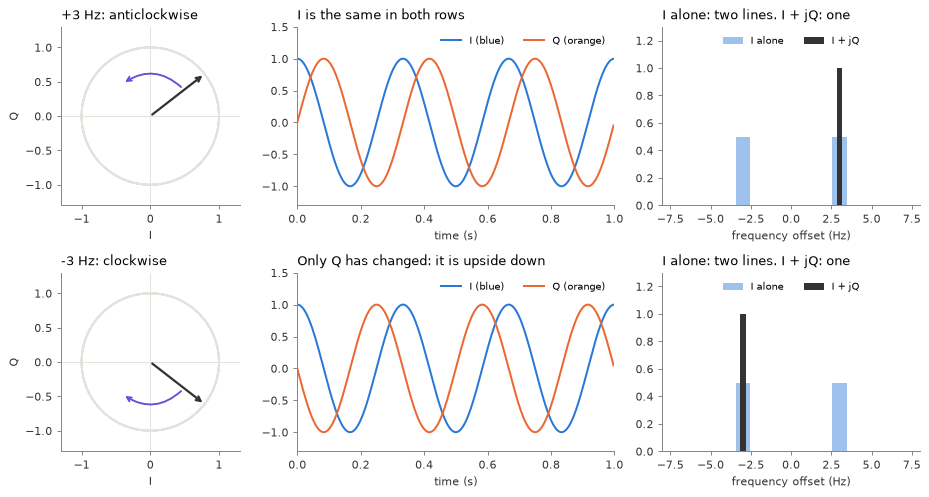

In [5]:
def fig_frequency_sign(offset=3):
    t = np.arange(400) / 400                                 # one second, 400 samples
    f = np.fft.fftshift(np.fft.fftfreq(len(t), t[1]))
    lines = lambda y: np.abs(np.fft.fftshift(np.fft.fft(y))) / len(t)
    fig, axs = plt.subplots(2, 3, figsize=(10.5, 5.6), gridspec_kw=dict(width_ratios=[1, 1.6, 1.3]))
    for (plane, waves, spectrum), df in zip(axs, (offset, -offset)):
        x = np.exp(2j * np.pi * df * t)                      # the point (I, Q) of a wave df Hz from the reference
        sense = np.sign(df)
        plane.plot(x.real, x.imag, color=LIGHT, lw=1.5)
        plane.annotate('', xy=(x.real[14], x.imag[14]), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=INK, lw=1.8))
        turn = np.radians(np.array([40, 130])) * sense       # an arrow along the circle, in the sense of rotation
        plane.annotate('', xy=(0.62 * np.cos(turn[1]), 0.62 * np.sin(turn[1])),
                       xytext=(0.62 * np.cos(turn[0]), 0.62 * np.sin(turn[0])),
                       arrowprops=dict(arrowstyle='->', color=VIOLET, lw=1.5, connectionstyle=f'arc3,rad={0.4 * sense}'))
        plane.axhline(0, color=LIGHT, lw=0.8, zorder=0); plane.axvline(0, color=LIGHT, lw=0.8, zorder=0)
        plane.set_xlim(-1.3, 1.3); plane.set_ylim(-1.3, 1.3); plane.set_aspect('equal')
        plane.set_xlabel('I'); plane.set_ylabel('Q')
        plane.set_title(f'{df:+d} Hz: {"anticlockwise" if df > 0 else "clockwise"}')
        waves.plot(t, x.real, color=BLUE, lw=1.6); waves.plot(t, x.imag, color=ORANGE, lw=1.6)
        waves.set_xlim(0, 1); waves.set_ylim(-1.3, 1.5); waves.set_xlabel('time (s)')
        waves.legend(['I (blue)', 'Q (orange)'], loc='upper right', ncol=2, fontsize=8)
        waves.set_title('I is the same in both rows' if df > 0 else 'Only Q has changed: it is upside down')
        spectrum.bar(f, lines(x.real), width=0.9, color=BLUE, alpha=0.45, label='I alone')
        spectrum.bar(f, lines(x), width=0.35, color=INK, label='I + jQ')
        spectrum.set_xlim(-8, 8); spectrum.set_ylim(0, 1.3); spectrum.set_xlabel('frequency offset (Hz)')
        spectrum.legend(loc='upper center', ncol=2, fontsize=8)
        spectrum.set_title('I alone: two lines. I + jQ: one')
    fig.tight_layout(); plt.show()

fig_frequency_sign()

**Explore.** The point $(I, Q)$ in motion. Press **▶ play**, or drag the time slider. $I$ is the shadow of the point on the horizontal axis and $Q$ its shadow on the vertical axis: the two curves on the right are those shadows, drawn against time. Things to try:

- Change the sign of the frequency offset: the point turns the other way, the $I$ curve stays the same and the $Q$ curve turns upside down.
- Set the offset to 0: the point stands still. A constant phase is a point that does not move.
- Tick the box: multiplying the wave by −1 sends the point to the opposite side of the centre, a jump of 180°. This is how GPS carries its code and its data (part 1).

In [6]:
def phasor_film(seconds=2.0, rate=100):
    t = np.arange(int(seconds * rate) + 1) / rate
    fig = plt.figure(figsize=(10, 4.2))
    grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.7])
    plane, top, bottom = fig.add_subplot(grid[:, 0]), fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[1, 1])
    circle = np.exp(2j * np.pi * np.linspace(0, 1, 200))
    plane.plot(circle.real, circle.imag, color=LIGHT, lw=1)
    plane.axhline(0, color=LIGHT, lw=0.8); plane.axvline(0, color=LIGHT, lw=0.8)
    plane.set_xlim(-1.35, 1.35); plane.set_ylim(-1.35, 1.35); plane.set_aspect('equal')
    plane.set_xlabel('I'); plane.set_ylabel('Q'); plane.set_title('The point (I, Q)')
    for ax, name in ((top, 'I: the shadow on the horizontal axis'), (bottom, 'Q: the shadow on the vertical axis')):
        ax.axhline(0, color=LIGHT, lw=0.8); ax.set_xlim(0, seconds); ax.set_ylim(-1.35, 1.35); ax.set_title(name)
    top.set_xticklabels([]); bottom.set_xlabel('time (s)')
    fig.tight_layout()
    part = dict(to_i=plane.plot([], [], color=BLUE, lw=1, ls=':')[0], to_q=plane.plot([], [], color=ORANGE, lw=1, ls=':')[0],
                shadow_i=plane.plot([], [], color=BLUE, lw=5, solid_capstyle='butt')[0],
                shadow_q=plane.plot([], [], color=ORANGE, lw=5, solid_capstyle='butt')[0],
                arrow=plane.plot([], [], color=INK, lw=2)[0], tip=plane.plot([], [], 'o', color=INK, ms=8)[0],
                curve_i=top.plot([], [], color=BLUE, lw=1.8)[0], dot_i=top.plot([], [], 'o', color=BLUE, ms=7)[0],
                curve_q=bottom.plot([], [], color=ORANGE, lw=1.8)[0], dot_q=bottom.plot([], [], 'o', color=ORANGE, ms=7)[0])
    quick = Quick(fig, list(part.values()))

    def draw(offset, flips, now):
        sign = np.where((t // 0.5) % 2 == 1, -1, 1) if flips else 1
        x = sign * np.exp(2j * np.pi * offset * t)           # the point at every instant
        k = int(round(now * rate))
        I, Q = x.real[k], x.imag[k]
        part['arrow'].set_data([0, I], [0, Q]); part['tip'].set_data([I], [Q])
        part['shadow_i'].set_data([0, I], [0, 0]); part['shadow_q'].set_data([0, 0], [0, Q])
        part['to_i'].set_data([I, I], [Q, 0]); part['to_q'].set_data([I, 0], [Q, Q])
        part['curve_i'].set_data(t[:k + 1], x.real[:k + 1]); part['dot_i'].set_data([t[k]], [I])
        part['curve_q'].set_data(t[:k + 1], x.imag[:k + 1]); part['dot_q'].set_data([t[k]], [Q])
        return quick.png()
    return draw

now = slider('time (s)', 0.0, 0.0, 2.0, 0.01, width='420px')
explore(phasor_film(), play_button(now),
        offset=slider('frequency offset (Hz)', 1.0, -3.0, 3.0, 0.5),
        flips=W.Checkbox(description='multiply by −1 every half second', indent=False, layout=W.Layout(width='auto')),
        now=now)

## 0.5 Reading the plane: four pictures to remember

Real samples carry noise, so in practice the plane shows clouds of points, one point per sample. Four pictures come back all through the lecture:

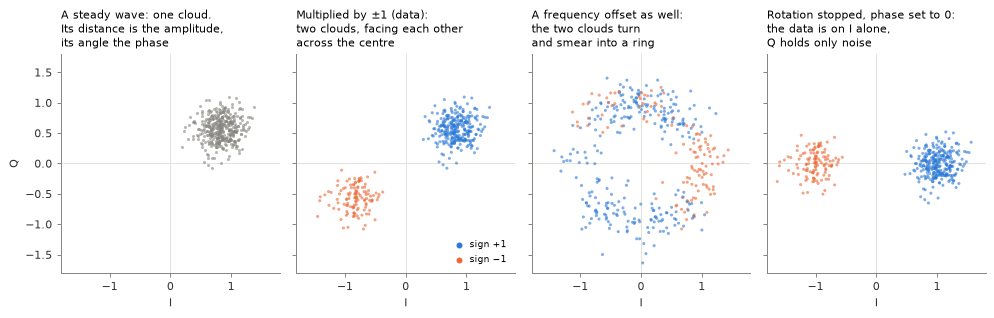

In [7]:
def fig_iq_gallery(n=400, noise=0.2, phase_deg=35, turns=0.8, seed=4):
    rng = np.random.default_rng(seed)
    data = rng.choice([-1, 1], n // 20).repeat(20)           # a sign that changes now and then
    phase = np.radians(phase_deg)
    drift = 2 * np.pi * turns * np.arange(n) / n             # a small frequency offset: 0.8 turn over the n points
    w = noise * (rng.standard_normal(n) + 1j * rng.standard_normal(n))
    cases = [('A steady wave: one cloud.\nIts distance is the amplitude,\nits angle the phase', np.exp(1j * phase) * np.ones(n), None),
             ('Multiplied by ±1 (data):\ntwo clouds, facing each other\nacross the centre', data * np.exp(1j * phase), data),
             ('A frequency offset as well:\nthe two clouds turn\nand smear into a ring', data * np.exp(1j * (phase + drift)), data),
             ('Rotation stopped, phase set to 0:\nthe data is on I alone,\nQ holds only noise', data.astype(complex), data)]
    fig, axs = plt.subplots(1, 4, figsize=(11, 3.5), sharey=True)
    for ax, (title, x, sign) in zip(axs, cases):
        x = x + w
        ax.scatter(x.real, x.imag, s=6, lw=0, alpha=0.6, c=GREY if sign is None else np.where(sign > 0, BLUE, ORANGE))
        ax.axhline(0, color=LIGHT, lw=0.8, zorder=0); ax.axvline(0, color=LIGHT, lw=0.8, zorder=0)
        ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8); ax.set_aspect('equal'); ax.set_xlabel('I'); ax.set_title(title, fontsize=9)
    axs[0].set_ylabel('Q')
    axs[1].scatter([], [], s=14, c=BLUE, label='sign +1'); axs[1].scatter([], [], s=14, c=ORANGE, label='sign −1')
    axs[1].legend(loc='lower right', fontsize=7.5, handletextpad=0.1)
    fig.tight_layout(); plt.show()

fig_iq_gallery()

The last picture is the goal of a GPS receiver, and part 3 is the story of how it gets from the third to the fourth: it measures the rotation, stops it, and turns the two clouds onto the $I$ axis. The sign of $I$ is then the data.

## 0.6 I and Q in a file

A recording made with a software radio is nothing more than the successive values of $I$ and $Q$. A HackRF One writes them as pairs of signed 8-bit integers, one after the other: $I_0, Q_0, I_1, Q_1, \dots$ Reading such a file takes two lines:

```python
raw = np.fromfile('capture.bin', dtype=np.int8)
x = raw[0::2] + 1j * raw[1::2]          # x[n] = I[n] + j Q[n]
```

The recording simulated in part 2 has the same layout.

**Where we are.**

- A radio signal near $f_c$ is described, at each instant, by two slow numbers. $I$ and $Q$ are those two numbers, and $x = I + jQ = a\,e^{j\varphi}$ is the signal with its carrier taken out.
- A receiver measures them by multiplying the signal by a cosine and by a sine at $f_c$, and averaging.
- In the plane, the **distance** from the centre is the amplitude, the **angle** is the phase, a **rotation** is a frequency offset (its direction gives the sign), and a multiplication by −1 is a **jump to the opposite point**.

From here on, "the signal" will most often mean $x(t)$. The carrier at 1575.42 MHz is written once more in part 1, then it disappears into the front end (section 2.3).

# Part 1. What a satellite transmits

The transmitted signal is a product of three things:

$$s(t) = \sqrt{2C}\;\, d(t)\;\, c(t)\;\, \cos(2\pi f_{L1}\, t)$$

- The **carrier** $\cos(2\pi f_{L1} t)$ is a pure sine wave at $f_{L1} = 1575.42$ MHz. Its only job is to get the signal through the air. Its wavelength is 19 cm.
- The **code** $c(t)$ is a fixed sequence of 1023 values, each +1 or −1, repeated without a pause. One value is called a **chip**. A chip looks like a bit, but it carries no information, because the receiver knows the whole sequence in advance. The code is what the receiver measures time with.
- The **data** $d(t)$ is the navigation message, also +1 or −1, at only 50 bits per second. It says where the satellite is and what time it is.
- $C$ is the signal power.

Multiplying a carrier by ±1 flips its phase by 180°. This is **BPSK** (binary phase-shift keying): every sign change of $d(t)\,c(t)$ is a phase jump of the carrier.

| | rate | duration | length at the speed of light |
|---|---|---|---|
| carrier cycle | 1575.42 MHz | 0.63 ns | 19 cm |
| chip | 1.023 million per second | 977.5 ns | 293 m |
| code period (1023 chips) | 1000 per second | 1 ms | 300 km |
| data bit (20 code periods) | 50 per second | 20 ms | 6000 km |

All four rates are derived from one atomic clock at 10.23 MHz on board: the chip rate is 10.23 MHz / 10 and the carrier is 10.23 MHz × 154. So there are exactly 1540 carrier cycles in a chip, a code period starts exactly every millisecond of satellite time, and a bit starts exactly every 20 ms. **The signal is the face of a clock.** Reading that clock is the whole purpose of the receiver.

The figure below shows the three layers. To keep the structure visible it uses toy numbers: a 6-chip code, 2 code periods per bit and 2 carrier cycles per chip (the real numbers are 1023, 20 and 1540).

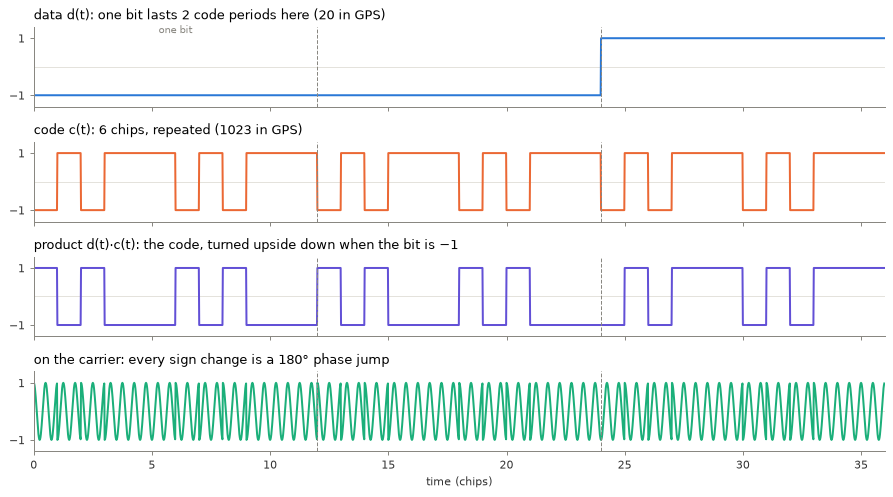

In [8]:
TOY_CODE = np.array([-1, 1, -1, 1, 1, 1])
TOY_CHIPS_PER_BIT = 12
TOY_BITS = np.random.default_rng(11).choice([-1, 1], 64)

def toy_layers(x):
    """Data, code, their product and the modulated carrier at times x (in chips)."""
    chip = np.floor(x).astype(int)
    d = TOY_BITS[(chip // TOY_CHIPS_PER_BIT) % 64]
    c = TOY_CODE[chip % 6]
    return [d, c, d * c, d * c * np.cos(2 * np.pi * 2 * x)]

LAYER_LABELS = ['data d(t): one bit lasts 2 code periods here (20 in GPS)',
                'code c(t): 6 chips, repeated (1023 in GPS)',
                'product d(t)·c(t): the code, turned upside down when the bit is −1',
                'on the carrier: every sign change is a 180° phase jump']
LAYER_COLOURS = [BLUE, ORANGE, VIOLET, AQUA]

def layer_axes(span, dpi=90):
    xs = np.linspace(0, span, span * 60, endpoint=False)
    fig, axs = plt.subplots(4, 1, figsize=(10, 5.6), sharex=True, dpi=dpi)
    lines = []
    for ax, label, colour, y in zip(axs, LAYER_LABELS, LAYER_COLOURS, toy_layers(xs)):
        ax.axhline(0, color=LIGHT, lw=0.8)
        lines.append(ax.plot(xs, y, color=colour, lw=1.6)[0])
        ax.set_ylim(-1.4, 1.4); ax.set_yticks([-1, 1]); ax.set_title(label)
    axs[-1].set_xlim(0, span); axs[-1].set_xlabel('time (chips)')
    fig.tight_layout()
    return fig, axs, xs, lines

def fig_signal_layers(span=36):
    fig, axs, xs, lines = layer_axes(span)
    for ax in axs:
        for edge in range(0, span + 1, TOY_CHIPS_PER_BIT):
            ax.axvline(edge, color=GREY, ls='--', lw=0.8)
    axs[0].text(TOY_CHIPS_PER_BIT / 2, 1.18, 'one bit', ha='center', fontsize=8, color=GREY)
    plt.show()

fig_signal_layers()

**Explore.** The same figure as a film: press **▶ play** to let time run, or drag the slider. Watch the third row: it is the code, and it turns upside down each time the data changes sign.

In [9]:
def signal_layers_film(span=36):
    """The figure above as a film: the same four layers, seen through a window that moves in time."""
    fig, axs, xs, lines = layer_axes(span)
    axs[-1].set_xticks([]); axs[-1].set_xlabel(f'time →   (the window is {span} chips wide; dashed: where a bit starts)')
    edges = [[ax.axvline(-1, color=GREY, ls='--', lw=0.8) for _ in range(4)] for ax in axs]
    quick = Quick(fig, lines + [edge for group in edges for edge in group])

    def draw(start):
        for line, y in zip(lines, toy_layers(start + xs)):
            line.set_ydata(y)
        first = np.ceil(start / TOY_CHIPS_PER_BIT) * TOY_CHIPS_PER_BIT
        for group in edges:
            for j, edge in enumerate(group):
                edge.set_xdata([first + j * TOY_CHIPS_PER_BIT - start] * 2)
        return quick.png()
    return draw

start = slider('start of the window (chips)', 0.0, 0.0, 120.0, 0.1, width='460px')
explore(signal_layers_film(), play_button(start), start=start)

## 1.1 The code: a simple machine that makes a noise-like sequence

Each satellite has its own code, identified by a number called its **PRN** (for "pseudo-random noise"), from 1 to 32. The code looks random but is made by a very simple machine.

**G1** and **G2** are two *shift registers*: rows of 10 boxes, called stages, each holding a 0 or a 1. Both start full of ones. The symbol **⊕** is **XOR**: the result is 1 if its two inputs differ and 0 if they are equal (with more inputs: 1 if an odd number of them are 1). At every tick of the chip clock, two things happen:

1. **A chip comes out:** stage 10 of G1 ⊕ two stages of G2. Which two stages is the only difference between satellites (PRN 1 uses stages 2 and 6).
2. **Both registers shift:** every bit moves one stage to the right, and stage 1 receives the ⊕ of a fixed set of stages (stages 3 and 10 for G1; stages 2, 3, 6, 8, 9 and 10 for G2).

**Why 1023 chips?** A register of 10 stages can hold $2^{10} = 1024$ patterns. The feedback stages are chosen so that the register goes through all of them except "all zeros" before it returns to its start: $2^{10} - 1 = 1023$ steps. Then the code repeats.

**Why two registers?** G1 alone would give every satellite the same code. The XOR of two stages of G2 is the same sequence as G2's output, only delayed, and each pair of stages gives a different delay. So every satellite sends G1 combined with a differently delayed G2. Codes built this way are called **Gold codes**.

The cell below is the generator. It checks itself against the specification, which lists the first 10 chips of every code.

In [10]:
# Which two stages of G2 each satellite uses (IS-GPS-200, table 3-Ia)
G2_TAPS = {1: (2, 6), 2: (3, 7), 3: (4, 8), 4: (5, 9), 5: (1, 9), 6: (2, 10), 7: (1, 8), 8: (2, 9),
           9: (3, 10), 10: (2, 3), 11: (3, 4), 12: (5, 6), 13: (6, 7), 14: (7, 8), 15: (8, 9),
           16: (9, 10), 17: (1, 4), 18: (2, 5), 19: (3, 6), 20: (4, 7), 21: (5, 8), 22: (6, 9),
           23: (1, 3), 24: (4, 6), 25: (5, 7), 26: (6, 8), 27: (7, 9), 28: (8, 10), 29: (1, 6),
           30: (2, 7), 31: (3, 8), 32: (4, 9)}
# The first 10 chips of each code, in octal, from the same table: used as a check
FIRST_10_CHIPS = {1: '1440', 2: '1620', 3: '1710', 4: '1744', 5: '1133', 6: '1455', 7: '1131',
                  8: '1454', 9: '1626', 10: '1504', 11: '1642', 12: '1750', 13: '1764', 14: '1772',
                  15: '1775', 16: '1776', 17: '1156', 18: '1467', 19: '1633', 20: '1715', 21: '1746',
                  22: '1763', 23: '1063', 24: '1706', 25: '1743', 26: '1761', 27: '1770', 28: '1774',
                  29: '1127', 30: '1453', 31: '1625', 32: '1712'}

def register_step(g1, g2, prn):
    """One tick of the chip clock: the chip that comes out, and the two registers after the shift."""
    a, b = G2_TAPS[prn]
    chip = g1[9] ^ g2[a - 1] ^ g2[b - 1]
    into_g1 = g1[2] ^ g1[9]                                      # stages 3 and 10
    into_g2 = g2[1] ^ g2[2] ^ g2[5] ^ g2[7] ^ g2[8] ^ g2[9]      # stages 2, 3, 6, 8, 9 and 10
    return chip, [into_g1] + g1[:9], [into_g2] + g2[:9]

def run_registers(prn, n=N):
    """The registers after n ticks, and the n chips (0 or 1) they produced."""
    g1, g2, chips = [1] * 10, [1] * 10, []
    for _ in range(n):
        chip, g1, g2 = register_step(g1, g2, prn)
        chips.append(chip)
    return g1, g2, chips

def ca_code(prn):
    """The code of one satellite as 1023 levels: chip 0 -> +1, chip 1 -> -1."""
    return 1 - 2 * np.array(run_registers(prn)[2])

CODES = {prn: ca_code(prn) for prn in range(1, 33)}

for prn in range(1, 33):
    first = ''.join(map(str, run_registers(prn, 10)[2]))
    assert oct(int(first, 2))[2:] == FIRST_10_CHIPS[prn]
g1, g2, chips = run_registers(1)
print('All 32 codes start as the specification says.')
print(f'After 1023 ticks both registers are back to all ones: {all(g1) and all(g2)}.')
print(f'PRN 1 has {sum(chips)} ones and {N - sum(chips)} zeros: almost balanced, like a coin tossed 1023 times.')

All 32 codes start as the specification says.
After 1023 ticks both registers are back to all ones: True.
PRN 1 has 512 ones and 511 zeros: almost balanced, like a coin tossed 1023 times.


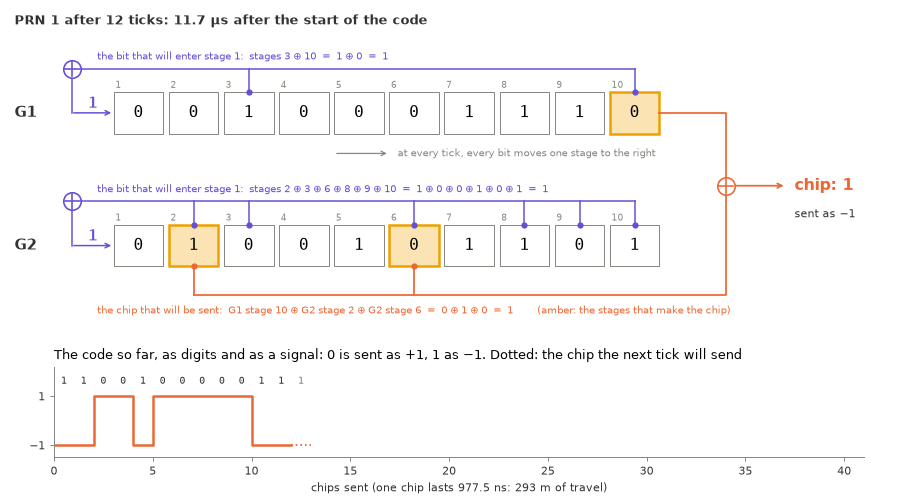

In [11]:
def fig_code_generator(prn=1, n=12):
    """The generator after n ticks: the two registers and their wiring, what the next tick will do
    (the bit that enters each register, the chip that is sent), and the chips sent so far."""
    g1, g2, chips = run_registers(prn, n)
    a, b = G2_TAPS[prn]
    enters = {'G1': g1[2] ^ g1[9], 'G2': g2[1] ^ g2[2] ^ g2[5] ^ g2[7] ^ g2[8] ^ g2[9]}
    nxt = g1[9] ^ g2[a - 1] ^ g2[b - 1]                   # the chip that the next tick will send
    fig = plt.figure(figsize=(10, 5.6))
    ax = fig.add_axes([0.01, 0.36, 0.98, 0.63]); ax.set_xlim(0, 16); ax.set_ylim(0.6, 6.7); ax.axis('off')
    middle = lambda stage: 1.35 + stage                   # x of the middle of a stage

    def xor(x, y, colour):
        ax.plot(x, y, 'o', ms=14, mfc='white', mec=colour, mew=1.3, zorder=3)
        ax.plot([x - 0.13, x + 0.13], [y, y], color=colour, lw=1.3, zorder=4)
        ax.plot([x, x], [y - 0.15, y + 0.15], color=colour, lw=1.3, zorder=4)

    state = ('both registers start full of ones' if n == 0 else
             'both registers are back to all ones: the code starts again' if n == N else
             f'{n * 0.9775:.1f} µs after the start of the code')
    ax.text(0.1, 6.4, f'PRN {prn} after {n} tick{"" if n == 1 else "s"}: {state}', fontsize=10, weight='bold', color=INK)
    for name, reg, feedback, y in [('G1', g1, (3, 10), 4.3), ('G2', g2, (2, 3, 6, 8, 9, 10), 1.75)]:
        ax.text(0.1, y + 0.4, name, fontsize=12, weight='bold', color=INK, va='center')
        for stage in range(1, 11):
            used = (name == 'G1' and stage == 10) or (name == 'G2' and stage in (a, b))
            ax.add_patch(Rectangle((middle(stage) - 0.45, y), 0.9, 0.8, fc='#fbe3b3' if used else 'white',
                                   ec=YELLOW if used else GREY, lw=2 if used else 0.8))
            ax.text(middle(stage), y + 0.4, str(reg[stage - 1]), ha='center', va='center', family='monospace', fontsize=13)
            ax.text(middle(stage) - 0.42, y + 0.84, str(stage), fontsize=7, color=GREY, va='bottom')
        # Feedback (violet): the tapped stages meet in a ⊕, and the result waits at the door of stage 1
        bus = y + 1.25
        for stage in feedback:
            ax.plot([middle(stage)] * 2, [y + 0.8, bus], color=VIOLET, lw=1.2)
            ax.plot(middle(stage), y + 0.8, 'o', color=VIOLET, ms=4)
        ax.plot([middle(feedback[-1]), 1.15, 1.15], [bus, bus, y + 0.4], color=VIOLET, lw=1.2)
        ax.annotate('', xy=(1.9, y + 0.4), xytext=(1.13, y + 0.4), arrowprops=dict(arrowstyle='->', color=VIOLET, lw=1.2))
        xor(1.15, bus, VIOLET)
        ax.text(1.52, y + 0.5, str(enters[name]), ha='center', color=VIOLET, weight='bold', family='monospace', fontsize=12)
        ax.text(1.6, bus + 0.13, f'the bit that will enter stage 1:  stages {" ⊕ ".join(map(str, feedback))}  =  '
                                 f'{" ⊕ ".join(str(reg[s - 1]) for s in feedback)}  =  {enters[name]}',
                fontsize=8, color=VIOLET, va='bottom')
    ax.annotate('', xy=(6.9, 3.92), xytext=(5.9, 3.92), arrowprops=dict(arrowstyle='->', color=GREY, lw=1))
    ax.text(7.05, 3.92, 'at every tick, every bit moves one stage to the right', fontsize=8, color=GREY, va='center')
    # Output (orange): stage 10 of G1 and the two amber stages of G2 meet in a ⊕: that is the chip
    out_x, out_y, low = 13.0, 3.3, 1.2
    ax.plot([middle(10) + 0.45, out_x, out_x], [4.7, 4.7, out_y], color=ORANGE, lw=1.4)
    for stage in (a, b):
        ax.plot([middle(stage)] * 2, [1.75, low], color=ORANGE, lw=1.4)
        ax.plot(middle(stage), 1.75, 'o', color=ORANGE, ms=4)
    ax.plot([middle(min(a, b)), out_x, out_x], [low, low, out_y], color=ORANGE, lw=1.4)
    ax.annotate('', xy=(14.1, out_y), xytext=(out_x, out_y), arrowprops=dict(arrowstyle='->', color=ORANGE, lw=1.4))
    xor(out_x, out_y, ORANGE)
    ax.text(14.25, out_y, f'chip: {nxt}', fontsize=13, weight='bold', color=ORANGE, va='center')
    ax.text(14.25, out_y - 0.55, f'sent as {"−1" if nxt else "+1"}', fontsize=9, color=INK, va='center')
    ax.text(1.6, low - 0.2, f'the chip that will be sent:  G1 stage 10 ⊕ G2 stage {a} ⊕ G2 stage {b}  =  '
                            f'{g1[9]} ⊕ {g2[a - 1]} ⊕ {g2[b - 1]}  =  {nxt}        (amber: the stages that make the chip)',
            fontsize=8, color=ORANGE, va='top')
    # The chips sent so far, and (dotted) the one the next tick will send
    axw = fig.add_axes([0.06, 0.10, 0.90, 0.18])
    first = max(0, n - 40)                                # the strip holds 41 chips
    level, coming = 1 - 2 * np.array(chips[first:], dtype=int), 1 - 2 * nxt
    if n:
        axw.step(np.arange(first, n + 1), np.r_[level, level[-1]], where='post', color=ORANGE, lw=2)
    axw.plot([n, n, n + 1], [level[-1] if n else coming, coming, coming], color=ORANGE, lw=1.4, ls=':')
    for k in range(first, n + 1):
        axw.text(k + 0.5, 1.5, str(chips[k] if k < n else nxt), ha='center', family='monospace', fontsize=8,
                 color=INK if k < n else GREY)
    axw.set_xlim(first, first + 41); axw.set_ylim(-1.5, 2.2); axw.set_yticks([-1, 1])
    axw.set_xticks(np.arange(first, first + 42, 5))
    axw.set_xlabel('chips sent (one chip lasts 977.5 ns: 293 m of travel)')
    axw.set_title('The code so far, as digits and as a signal: 0 is sent as +1, 1 as −1. Dotted: the chip the next tick will send')
    plt.show()

fig_code_generator(prn=1, n=12)

**Explore.** Work the generator yourself, for any satellite.

- **one tick ▶** sends one chip and shifts both registers. Before pressing, read the figure: the violet digit at the left of each register is the bit about to enter stage 1, and the orange digit on the right is the chip about to be sent. After pressing, the violet digit is in stage 1, every other bit has moved one stage to the right, and the chip has joined the code at the bottom.
- **◀ one tick back** undoes a tick, and **⏮ start again** returns to the start (both registers full of ones).
- **▶ run** keeps ticking at the chosen speed, and the slider jumps to any tick. At 1023 both registers are full of ones again: the code repeats.
- Change the satellite: the registers and their feedback stay the same. Only the two amber stages of G2 move, and with them the whole code.

In [12]:
ticks = slider('ticks done', 0, 0, N, width='460px')
back, forward, again = W.Button(description='◀ one tick back'), W.Button(description='one tick ▶', button_style='info'), W.Button(description='⏮ start again')
back.on_click(lambda _: setattr(ticks, 'value', max(ticks.value - 1, 0)))
forward.on_click(lambda _: setattr(ticks, 'value', min(ticks.value + 1, N)))
again.on_click(lambda _: setattr(ticks, 'value', 0))
speed = choice('speed', {'slow: 1 tick per second': 1, 'fast: as many as can be drawn': 50}, 50)
explore(fig_code_generator, again, back, forward, play_button(ticks, speed, label='▶ run'), speed,
        prn=choice('satellite (PRN)', range(1, 33), 1), n=ticks)

## 1.2 Why these codes: each one matches only itself

The receiver will look for a satellite by comparing the incoming signal with its own copy of that satellite's code. The comparison is a **correlation**: slide one code past the other, and at each shift $k$ multiply the chips that face each other and add up the 1023 products:

$$R_{ab}[k] = \sum_{i=0}^{1022} c_a[i]\; c_b[(i + k) \bmod 1023]$$

Where two chips agree, the product is +1; where they differ, −1. So $R$ counts agreements minus disagreements.

- A code against **itself, aligned** ($a = b$, $k = 0$): all 1023 products are +1. $R = 1023$.
- A code against **itself, shifted** by one chip or more: about half the chips agree. $R$ is small.
- A code against **another satellite's code**, at any shift: also small.

For the GPS codes, "small" is exact: every value other than the peak is −65, −1 or +63. The worst case, 65/1023, is 24 dB below the peak.

These two properties are the answer to two of the three problems of the introduction:

- **Sharing one frequency.** A receiver that correlates with the code of PRN 1 gets a large number only from the signal of PRN 1. The other satellites contribute almost nothing. This is **CDMA** (code-division multiple access).
- **Measuring time.** The peak is only one chip wide. Finding *where* the peak is tells the receiver when the code started, to within a fraction of a microsecond.

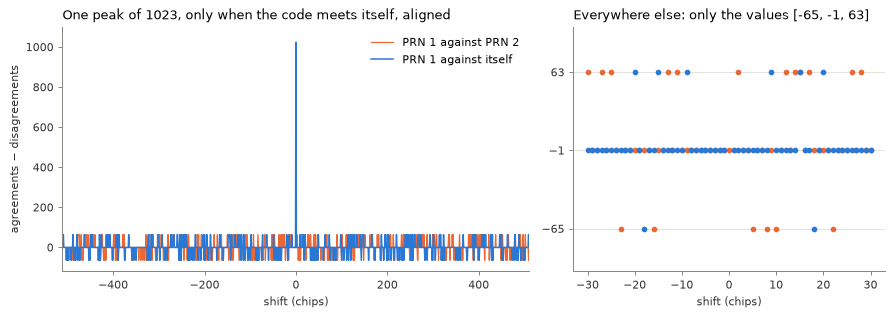

In [13]:
def correlation(a, b):
    """Circular correlation of two codes at every shift, by the FFT shortcut."""
    return np.rint(np.real(np.fft.ifft(np.conj(np.fft.fft(a)) * np.fft.fft(b)))).astype(int)

def fig_code_correlation(prn_a=1, prn_b=2):
    shifts = np.arange(-511, 512)
    auto = correlation(CODES[prn_a], CODES[prn_a])[shifts % N]
    cross = correlation(CODES[prn_a], CODES[prn_b])[shifts % N]
    fig, (ax, az) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.5, 1]))
    ax.plot(shifts, cross, color=ORANGE, lw=1, label=f'PRN {prn_a} against PRN {prn_b}')
    ax.plot(shifts, auto, color=BLUE, lw=1.2, label=f'PRN {prn_a} against itself')
    ax.set_xlim(-511, 511); ax.set_ylim(-120, 1100)
    ax.set_xlabel('shift (chips)'); ax.set_ylabel('agreements − disagreements')
    ax.set_title(f'One peak of {auto.max()}, only when the code meets itself, aligned')
    ax.legend(loc='upper right')
    near = np.abs(shifts) <= 30
    az.plot(shifts[near], cross[near], 'o', color=ORANGE, ms=3.5)
    az.plot(shifts[near], auto[near], 'o', color=BLUE, ms=3.5)
    for v in (-65, -1, 63):
        az.axhline(v, color=LIGHT, lw=0.8, zorder=0)
    az.set_ylim(-100, 100); az.set_yticks([-65, -1, 63]); az.set_xlabel('shift (chips)')
    others = sorted({int(v) for v in auto[shifts != 0]} | {int(v) for v in cross})
    az.set_title(f'Everywhere else: only the values {others}')
    fig.tight_layout(); plt.show()

fig_code_correlation(1, 2)

**Explore.** Any pair of satellites.

In [14]:
explore(fig_code_correlation, prn_a=choice('code of PRN', range(1, 33), 1),
        prn_b=choice('compared with the code of PRN', range(1, 33), 2))

## 1.3 What the code does to the spectrum

The data alone changes sign at most 50 times per second, so its power sits within about ±50 Hz of the carrier. Multiplying by the code makes the signal change sign up to 1.023 million times per second, and that spreads the same power over about ±1 MHz. This is why $c(t)$ is called a *spreading* code, and the technique *spread spectrum*.

For a random ±1 sequence with symbols of duration $T$, the power spectral density (power per hertz) at an offset $f$ from the carrier is

$$S(f) = C\, T\, \mathrm{sinc}^2(f\,T), \qquad \mathrm{sinc}(x) = \frac{\sin \pi x}{\pi x}$$

- Data only, $T = T_b = 20$ ms: a peak $C\,T_b$, with the first zeros at ±50 Hz.
- Data × code, $T = T_c = 977.5$ ns: a peak $C\,T_c$, **20 460 times lower (43 dB)**, with the first zeros at ±1.023 MHz.

The total power $C$ is the same in both cases. It is only spread thinner. Part 2 shows that, spread this thin, the signal lies below the receiver's noise. Part 3 shows how the receiver undoes the spreading.

**A detail: the spectrum is made of lines.** The code is not random: it repeats every millisecond. A signal that repeats every 1 ms can only contain frequencies that are multiples of 1 kHz. So the spectrum of the code is a comb of lines 1 kHz apart, under the sinc² envelope, and the lines are not all equal: some are several dB above the average. The data then smears each line over about 100 Hz. A receiver rarely needs to care, but it explains why a narrow interfering tone can do more harm when it falls on a strong line.

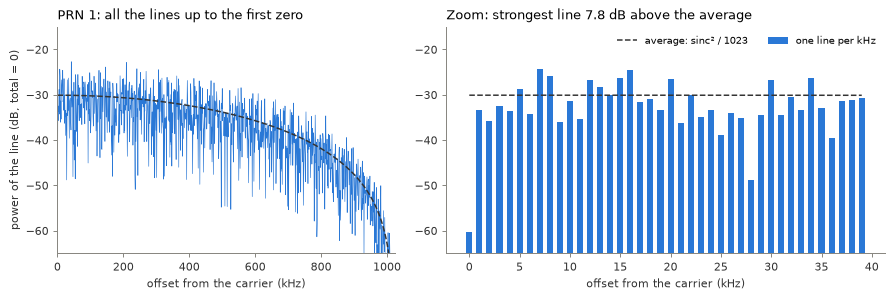

In [15]:
def code_line_spectrum(prn):
    """Power of each spectral line of a code (one line per kHz), and the average envelope, in dB."""
    m = np.arange(N)
    power = np.abs(np.fft.fft(CODES[prn])) ** 2 / N ** 2 * np.sinc(m / N) ** 2
    envelope = np.sinc(m / N) ** 2 / N
    return 10 * np.log10(np.maximum(power, 1e-12)), 10 * np.log10(envelope)

def fig_line_spectrum(prn=1, start=0):
    power, envelope = code_line_spectrum(prn)
    fig, (ax, az) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw=dict(width_ratios=[1, 1.3]))
    m = np.arange(N)
    ax.plot(m, power, color=BLUE, lw=0.5)
    ax.plot(m, envelope, color=INK, lw=1.2, ls='--')
    ax.set_xlim(0, N); ax.set_ylim(-65, -15)
    ax.set_xlabel('offset from the carrier (kHz)'); ax.set_ylabel('power of the line (dB, total = 0)')
    ax.set_title(f'PRN {prn}: all the lines up to the first zero')
    w = np.arange(start, min(N, start + 40))
    az.bar(w, power[w] + 65, bottom=-65, width=0.6, color=BLUE, label='one line per kHz')
    az.plot(w, envelope[w], color=INK, lw=1.2, ls='--', label='average: sinc² / 1023')
    az.set_ylim(-65, -15); az.set_xlabel('offset from the carrier (kHz)')
    az.set_title(f'Zoom: strongest line {(power[1:] - envelope[1:]).max():.1f} dB above the average')
    az.legend(loc='upper right', ncol=2, fontsize=8)
    fig.tight_layout(); plt.show()

fig_line_spectrum(1)

**Explore.** Other satellites, other parts of the spectrum.

In [16]:
explore(fig_line_spectrum, prn=choice('satellite (PRN)', range(1, 33), 1),
        start=slider('the zoom starts at (kHz)', 0, 0, 980, 5, width='460px'))

## 1.4 The data: the navigation message

The message $d(t)$ is what turns a ranging signal into a navigation signal. It is slow, 50 bits per second, and strictly organised:

| unit | made of | lasts |
|---|---|---|
| bit | 20 code periods | 20 ms |
| word | 30 bits: 24 of data, then 6 of parity | 0.6 s |
| subframe | 10 words (300 bits) | 6 s |
| frame | 5 subframes (1500 bits) | 30 s |

**Every subframe starts the same way**, and this is what lets a receiver find its place in the bit stream:

- Word 1 begins with the **preamble**, the fixed pattern `10001011`.
- Word 2 carries the **time of week**: the satellite time at which the *next* subframe will start, counted in units of 6 s since the start of the week (midnight between Saturday and Sunday). It also carries the **subframe number**, 1 to 5.

**What the subframes contain:**

- **Subframe 1:** the week number and the **clock correction** of the satellite (how far its clock is from GPS time: an offset $a_{f0}$, a drift $a_{f1}$ and a drift rate $a_{f2}$).
- **Subframes 2 and 3:** the **ephemeris**, 16 numbers that describe the satellite's orbit precisely for the next few hours (part 2 explains them).
- **Subframes 4 and 5:** slower information that takes 25 frames (12.5 minutes) to send in full: the rough orbits of all satellites (the almanac), an ionosphere model, the offset to UTC. A position needs none of it.

So a receiver needs subframes 1, 2 and 3 complete, from every satellite it uses: at least 18 s of signal, and up to 36 s if it starts listening at a bad moment.

**Numbers are sent as integers.** Each field is an integer of a fixed number of bits, and the specification gives the value of one unit. For example the eccentricity of the orbit is sent as a 32-bit integer in units of $2^{-33}$. Negative values use two's complement. Some fields are split over two words.

**Parity.** The last 6 bits of every word let the receiver detect errors. Each parity bit is the XOR of a fixed selection of the word's 24 data bits and of one of the last two bits of the *previous* word. The satellite also does one more thing: if the last bit of the previous word was 1, it inverts the 24 data bits before sending them. Part 4 shows what this is for (it is a neat trick).

The cell below defines the layout of subframes 1 to 3 once, as a table. The transmitter (here) and the receiver (part 4) both use it.

In [17]:
PI_GPS = 3.1415926535898     # the value of pi fixed by the specification
PREAMBLE = [1, 0, 0, 0, 1, 0, 1, 1]

# name, subframe, [(first bit, number of bits), ...], signed, value of one unit, unit, meaning.
# Bits are numbered 1 to 300 in the subframe. Angles are sent in half-turns: one unit below is
# already converted to radians.
FIELDS = [
    ('week',      1, [(61, 10)],            False, 1,                   'weeks', 'week number, modulo 1024'),
    ('t_gd',      1, [(197, 8)],            True,  2**-31,              's',     'delay of L1 inside the satellite'),
    ('iodc',      1, [(83, 2), (211, 8)],   False, 1,                   '',      'issue number of the clock data'),
    ('t_oc',      1, [(219, 16)],           False, 2**4,                's',     'reference time of the clock correction'),
    ('a_f2',      1, [(241, 8)],            True,  2**-55,              's/s²',  'clock drift rate'),
    ('a_f1',      1, [(249, 16)],           True,  2**-43,              's/s',   'clock drift'),
    ('a_f0',      1, [(271, 22)],           True,  2**-31,              's',     'clock offset'),
    ('iode',      2, [(61, 8)],             False, 1,                   '',      'issue number of the ephemeris'),
    ('c_rs',      2, [(69, 16)],            True,  2**-5,               'm',     'radius correction (sine)'),
    ('delta_n',   2, [(91, 16)],            True,  2**-43 * PI_GPS,     'rad/s', 'correction to the mean motion'),
    ('m_0',       2, [(107, 8), (121, 24)], True,  2**-31 * PI_GPS,     'rad',   'mean anomaly at the reference time'),
    ('c_uc',      2, [(151, 16)],           True,  2**-29,              'rad',   'along-track correction (cosine)'),
    ('e',         2, [(167, 8), (181, 24)], False, 2**-33,              '',      'eccentricity'),
    ('c_us',      2, [(211, 16)],           True,  2**-29,              'rad',   'along-track correction (sine)'),
    ('sqrt_a',    2, [(227, 8), (241, 24)], False, 2**-19,              '√m',    'square root of the semi-major axis'),
    ('t_oe',      2, [(271, 16)],           False, 2**4,                's',     'reference time of the ephemeris'),
    ('c_ic',      3, [(61, 16)],            True,  2**-29,              'rad',   'inclination correction (cosine)'),
    ('omega_0',   3, [(77, 8), (91, 24)],   True,  2**-31 * PI_GPS,     'rad',   'longitude of the ascending node'),
    ('c_is',      3, [(121, 16)],           True,  2**-29,              'rad',   'inclination correction (sine)'),
    ('i_0',       3, [(137, 8), (151, 24)], True,  2**-31 * PI_GPS,     'rad',   'inclination'),
    ('c_rc',      3, [(181, 16)],           True,  2**-5,               'm',     'radius correction (cosine)'),
    ('omega',     3, [(197, 8), (211, 24)], True,  2**-31 * PI_GPS,     'rad',   'argument of perigee'),
    ('omega_dot', 3, [(241, 24)],           True,  2**-43 * PI_GPS,     'rad/s', 'rate of the node longitude'),
    ('iode_3',    3, [(271, 8)],            False, 1,                   '',      'issue number again (must match)'),
    ('i_dot',     3, [(279, 14)],           True,  2**-43 * PI_GPS,     'rad/s', 'rate of the inclination'),
]

# Which data bits (1 to 24) enter each of the six parity bits, and which of the previous word's
# last two bits (29 or 30) is added to it (IS-GPS-200, table 20-XIV).
PARITY_RULES = [(29, [1, 2, 3, 5, 6, 10, 11, 12, 13, 14, 17, 18, 20, 23]),
                (30, [2, 3, 4, 6, 7, 11, 12, 13, 14, 15, 18, 19, 21, 24]),
                (29, [1, 3, 4, 5, 7, 8, 12, 13, 14, 15, 16, 19, 20, 22]),
                (30, [2, 4, 5, 6, 8, 9, 13, 14, 15, 16, 17, 20, 21, 23]),
                (30, [1, 3, 5, 6, 7, 9, 10, 14, 15, 16, 17, 18, 21, 22, 24]),
                (29, [3, 5, 6, 8, 9, 10, 11, 13, 15, 19, 22, 23, 24])]

def parity_bits(data, prev29, prev30):
    """The six parity bits of a word, from its 24 data bits and the last two bits of the previous word."""
    prev = {29: prev29, 30: prev30}
    return [prev[which] ^ (sum(data[i - 1] for i in bits) % 2) for which, bits in PARITY_RULES]

def to_bits(value, n):
    """An integer as n bits, most significant first (two's complement if negative)."""
    return [(value >> (n - 1 - i)) & 1 for i in range(n)]

def from_bits(bits, signed=False):
    value = int(''.join(map(str, bits)), 2)
    return value - (1 << len(bits)) if signed and bits[0] else value

def subframe_data(number, tow_next, eph):
    """The 300 bits of a subframe before parity (the parity positions are left at 0)."""
    d = [0] * 300
    d[0:8] = PREAMBLE
    d[30:47] = to_bits(int(tow_next) // 6, 17)        # time of week of the next subframe, in units of 6 s
    d[49:52] = to_bits(number, 3)
    for name, subframe, parts, signed, unit, *_ in FIELDS:
        if subframe == number:
            bits = to_bits(int(round(eph[name] / unit)), sum(n for _, n in parts))
            for first, n in parts:
                d[first - 1:first - 1 + n], bits = bits[:n], bits[n:]
    if number > 3:                                    # subframes 4 and 5: filler, as in unused fields
        for word in range(2, 10):
            d[30 * word:30 * word + 24] = [1, 0] * 12
    return d

def add_parity(d, prev29=0, prev30=0):
    """What the satellite sends for a subframe: data bits (inverted if the previous bit was 1) and parity."""
    sent = []
    for word in range(10):
        data = d[30 * word:30 * word + 24]
        if word in (1, 9):       # words 2 and 10: their last two data bits are chosen so that the word ends in 00
            for trial in range(4):
                data[22:24] = [trial >> 1, trial & 1]
                if parity_bits(data, prev29, prev30)[4:] == [0, 0]:
                    break
        parity = parity_bits(data, prev29, prev30)
        sent += [bit ^ prev30 for bit in data] + parity
        prev29, prev30 = parity[4], parity[5]
    return sent

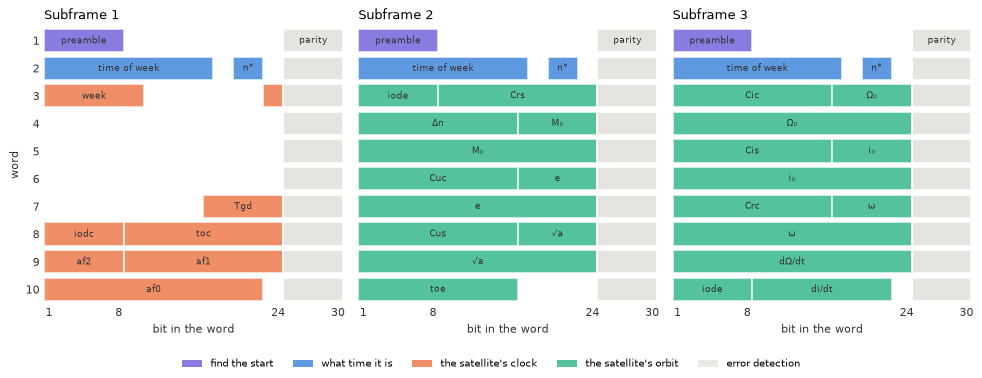

In [18]:
def fig_subframe_layout():
    """Where each field sits in subframes 1 to 3: one row per word, one column per bit."""
    kind_colour = {'sync': VIOLET, 'time': BLUE, 'clock': ORANGE, 'orbit': AQUA, 'parity': LIGHT}
    clock = {'week', 't_gd', 'iodc', 't_oc', 'a_f2', 'a_f1', 'a_f0'}
    pretty = {'sqrt_a': '√a', 'omega_0': 'Ω₀', 'omega': 'ω', 'omega_dot': 'dΩ/dt', 'i_dot': 'di/dt',
              'delta_n': 'Δn', 'm_0': 'M₀', 'i_0': 'i₀', 'iode_3': 'iode', 'a_f0': 'af0', 'a_f1': 'af1',
              'a_f2': 'af2', 't_oc': 'toc', 't_oe': 'toe', 't_gd': 'Tgd', 'c_rs': 'Crs', 'c_rc': 'Crc',
              'c_uc': 'Cuc', 'c_us': 'Cus', 'c_ic': 'Cic', 'c_is': 'Cis'}
    fig, axs = plt.subplots(1, 3, figsize=(11, 4.2), sharey=True)
    for number, ax in zip((1, 2, 3), axs):
        spans = [('preamble', 'sync', 1, 8), ('time of week', 'time', 31, 17), ('n°', 'time', 50, 3)]
        spans += [(pretty.get(name, name), 'clock' if name in clock else 'orbit', first, n)
                  for name, subframe, parts, *_ in FIELDS if subframe == number for first, n in parts]
        spans += [('parity' if word == 0 else '', 'parity', 30 * word + 25, 6) for word in range(10)]
        for label, kind, first, n in spans:
            word, col = (first - 1) // 30, (first - 1) % 30
            ax.add_patch(Rectangle((col, word + 0.08), n, 0.84, fc=kind_colour[kind], ec='white', lw=1.5,
                                   alpha=0.9 if kind == 'parity' else 0.75))
            ax.text(col + n / 2, word + 0.5, label if n >= 3 else '', ha='center', va='center', fontsize=7.5, color=INK)
        ax.set_xlim(0, 30); ax.set_ylim(10, 0)
        ax.set_xticks([0.5, 7.5, 23.5, 29.5], ['1', '8', '24', '30']); ax.set_yticks(np.arange(10) + 0.5, range(1, 11))
        ax.tick_params(length=0); ax.set_xlabel('bit in the word')
        ax.set_title(f'Subframe {number}')
        for s in ('left', 'bottom'):
            ax.spines[s].set_visible(False)
    axs[0].set_ylabel('word')
    handles = [Rectangle((0, 0), 1, 1, fc=c, alpha=0.75) for c in kind_colour.values()]
    fig.legend(handles, ['find the start', 'what time it is', "the satellite's clock", "the satellite's orbit",
                         'error detection'], loc='lower center', ncol=5, fontsize=8)
    fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

fig_subframe_layout()

White areas are bits a position does not need (reserved bits, health flags and so on). Words 1 and 2 are the same in every subframe: this regularity is what part 4 will search for.

**Where we are.** We can now build everything a satellite sends: a code, a message, and their product on a carrier. Next: what happens between the satellite and the receiver's memory.

# Part 2. From the satellite to the samples

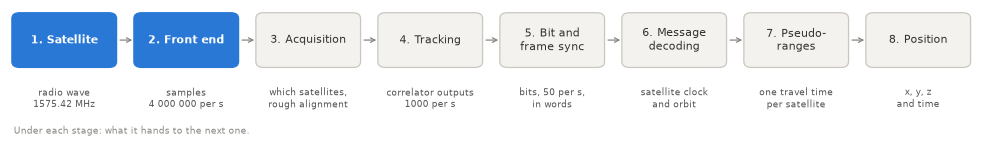

In [19]:
pipeline_map(1, 2)

## 2.1 The sky of the simulation

We need satellites in the sky and a receiver on the ground. The receiver is placed at the Royal Observatory in Greenwich. The five satellites are given orbits of the real GPS kind: almost circular, 20 200 km above the ground, inclined at 55° to the equator, one revolution in 11 h 58 min.

An orbit is described the way the navigation message describes it, by the **ephemeris**:

- six numbers that define an ellipse and where the satellite is on it: the size $\sqrt{a}$, the eccentricity $e$, the inclination $i_0$, the longitude of the ascending node $\Omega_0$ (where the orbit crosses the equator going north), the argument of perigee $\omega$ (where the lowest point of the ellipse is) and the mean anomaly $M_0$ (where the satellite is at the reference time $t_{oe}$);
- nine small corrections, because the Earth is not a perfect sphere and the Moon and Sun pull too: three rates ($\Delta n$, $\dot\Omega$, $\dot i$) and six amplitudes of a twice-per-orbit wobble ($C_{uc}, C_{us}, C_{rc}, C_{rs}, C_{ic}, C_{is}$).

`sat_position` below turns an ephemeris and a time into a position, following the recipe of the specification. The position is given in the **ECEF** frame (Earth-centred, Earth-fixed): the origin is the centre of the Earth, and the axes turn with the Earth, so a point on the ground has constant coordinates.

The receiver in part 5 will call the very same function, with the ephemeris it has decoded from the signal.

In [20]:
MU = 3.986005e14              # m^3/s^2, gravitational constant of the Earth (value fixed by the specification)
OMEGA_E = 7.2921151467e-5     # rad/s, rotation rate of the Earth
F_REL = -4.442807633e-10      # s/sqrt(m), constant of the relativistic clock correction
EARTH_A, EARTH_E2 = 6378137.0, 6.69437999014e-3    # WGS 84 ellipsoid: equatorial radius, eccentricity squared

def sat_position(eph, t):
    """Position of a satellite (ECEF, metres) at GPS time t (seconds of the week), from its ephemeris.
    Also returns the eccentric anomaly, which the clock correction needs."""
    a = eph['sqrt_a'] ** 2
    tk = t - eph['t_oe']                                         # time since the reference time
    M = eph['m_0'] + (np.sqrt(MU / a ** 3) + eph['delta_n']) * tk    # mean anomaly: grows at a constant rate
    E = M
    for _ in range(10):                                          # Kepler's equation  M = E - e sin E
        E = M + eph['e'] * np.sin(E)
    nu = np.arctan2(np.sqrt(1 - eph['e'] ** 2) * np.sin(E), np.cos(E) - eph['e'])   # true anomaly
    phi = nu + eph['omega']                                      # angle from the ascending node
    s2, c2 = np.sin(2 * phi), np.cos(2 * phi)
    u = phi + eph['c_us'] * s2 + eph['c_uc'] * c2                # corrected angle,
    r = a * (1 - eph['e'] * np.cos(E)) + eph['c_rs'] * s2 + eph['c_rc'] * c2    # radius
    i = eph['i_0'] + eph['i_dot'] * tk + eph['c_is'] * s2 + eph['c_ic'] * c2    # and inclination
    node = eph['omega_0'] + (eph['omega_dot'] - OMEGA_E) * tk - OMEGA_E * eph['t_oe']   # node, in the turning frame
    x, y = r * np.cos(u), r * np.sin(u)                          # position in the plane of the orbit
    return np.array([x * np.cos(node) - y * np.cos(i) * np.sin(node),
                     x * np.sin(node) + y * np.cos(i) * np.cos(node),
                     y * np.sin(i)]), E

def sat_clock_error(eph, t, E):
    """How far the satellite's clock is ahead of GPS time (s): polynomial, relativity, internal delay."""
    dt = t - eph['t_oc']
    return (eph['a_f0'] + eph['a_f1'] * dt + eph['a_f2'] * dt ** 2
            + F_REL * eph['e'] * eph['sqrt_a'] * np.sin(E) - eph['t_gd'])

def turn_with_earth(pos, angle):
    """Coordinates of a fixed point of space after the Earth-fixed axes have turned by `angle`."""
    return np.array([pos[0] * np.cos(angle) + pos[1] * np.sin(angle),
                     -pos[0] * np.sin(angle) + pos[1] * np.cos(angle), pos[2]])

def lla_to_ecef(lat, lon, h):
    lat, lon = np.radians(lat), np.radians(lon)
    n = EARTH_A / np.sqrt(1 - EARTH_E2 * np.sin(lat) ** 2)
    return np.array([(n + h) * np.cos(lat) * np.cos(lon), (n + h) * np.cos(lat) * np.sin(lon),
                     (n * (1 - EARTH_E2) + h) * np.sin(lat)])

def ecef_to_lla(p):
    lon, pr = np.arctan2(p[1], p[0]), np.hypot(p[0], p[1])
    lat = np.arctan2(p[2], pr * (1 - EARTH_E2))
    for _ in range(6):
        n = EARTH_A / np.sqrt(1 - EARTH_E2 * np.sin(lat) ** 2)
        h = pr / np.cos(lat) - n
        lat = np.arctan2(p[2], pr * (1 - EARTH_E2 * n / (n + h)))
    return np.degrees(lat), np.degrees(lon), h

def east_north_up(lat, lon):
    """Matrix that turns an ECEF vector into (east, north, up) at a place."""
    lat, lon = np.radians(lat), np.radians(lon)
    return np.array([[-np.sin(lon), np.cos(lon), 0],
                     [-np.sin(lat) * np.cos(lon), -np.sin(lat) * np.sin(lon), np.cos(lat)],
                     [np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]])

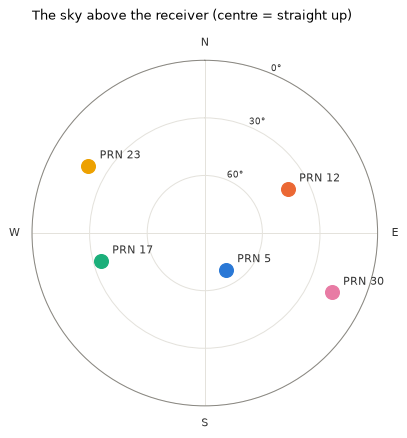

| satellite | azimuth | elevation | distance | travel time | Doppler shift | strength |
|---|---|---|---|---|---|---|
| 5 | 150° | 68° | 20,384 km | 68.0 ms | +958 Hz | 49 dB-Hz |
| 12 | 62° | 41° | 22,152 km | 73.9 ms | -2,491 Hz | 46 dB-Hz |
| 17 | 255° | 34° | 22,202 km | 74.1 ms | +3,070 Hz | 44 dB-Hz |
| 23 | 300° | 20° | 23,658 km | 78.9 ms | -373 Hz | 41 dB-Hz |
| 30 | 115° | 17° | 23,787 km | 79.3 ms | +2,767 Hz | 39 dB-Hz |

In [21]:
TRUE_LLA = (51.4779, -0.0015, 46.0)        # latitude (deg), longitude (deg), height (m): Greenwich
TRUE_POS = lla_to_ecef(*TRUE_LLA)

TOW_START = 221_400                        # s of the week: a subframe 1 starts here (Tuesday, 13:30:00)
T_OE = 223_200                             # reference time of the ephemerides (14:00:00)

# prn: sqrt(a) (sqrt m), eccentricity, inclination, node longitude, argument of perigee, mean anomaly (degrees)
ORBITS = {5:  (5153.65, 0.0061, 55.2, -175.3148,   40.0,   21.0419),
          12: (5153.65, 0.0089, 54.6,  157.8488, -110.0, -131.1827),
          17: (5153.65, 0.0132, 55.9,  136.3576,   75.0,  -26.4903),
          23: (5153.65, 0.0024, 54.9,  -22.2861,  160.0,  -22.0243),
          30: (5153.65, 0.0105, 55.4, -109.1957,  -35.0,   60.8389)}
CN0_DBHZ = {5: 49, 12: 46, 17: 44, 23: 41, 30: 39}     # signal strength of each satellite (explained in 2.2)
SAT_COLOUR = dict(zip(ORBITS, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
PRNS = list(ORBITS)

def make_ephemeris(prn, rng):
    """A complete ephemeris: the ellipse above, plus corrections and clock terms of realistic size."""
    sqrt_a, e, i_0, omega_0, omega, m_0 = ORBITS[prn]
    eph = dict(sqrt_a=sqrt_a, e=e, i_0=np.radians(i_0), omega_0=np.radians(omega_0),
               omega=np.radians(omega), m_0=np.radians(m_0), t_oe=T_OE, t_oc=T_OE,
               delta_n=rng.normal(4.5e-9, 4e-10), omega_dot=rng.normal(-8.0e-9, 4e-10), i_dot=rng.normal(0, 3e-10),
               c_uc=rng.normal(0, 4e-6), c_us=rng.normal(0, 4e-6), c_rc=rng.normal(250, 60), c_rs=rng.normal(0, 60),
               c_ic=rng.normal(0, 1e-7), c_is=rng.normal(0, 1e-7),
               a_f0=rng.normal(0, 2e-4), a_f1=rng.normal(0, 4e-12), a_f2=0.0, t_gd=rng.normal(0, 8e-9),
               week=2444 % 1024, iodc=prn + 40, iode=prn + 40, iode_3=prn + 40)
    # Keep only what the message can carry: round every field to a whole number of its units
    for name, _, _, _, unit, *_ in FIELDS:
        eph[name] = round(eph[name] / unit) * unit
    return eph

_rng = np.random.default_rng(2024)
TRUE_EPH = {prn: make_ephemeris(prn, _rng) for prn in PRNS}

def signal_arriving(eph, t, rx_pos):
    """The signal of one satellite that arrives at the receiver at GPS time t (scalar or array).
    Returns its lag: how far behind t the satellite's clock was when that signal left (travel time,
    minus the error of the satellite's clock). Also returns where the satellite was then, in the
    Earth-fixed frame of the arrival time."""
    travel = 0.075
    for _ in range(5):                                  # the travel time depends on itself: iterate
        pos, E = sat_position(eph, t - travel)
        pos = turn_with_earth(pos, OMEGA_E * travel)    # the Earth turns while the signal flies
        travel = np.linalg.norm(pos.T - rx_pos, axis=-1) / C_LIGHT
    return travel - sat_clock_error(eph, t - travel, E), pos

def fig_sky():
    t = TOW_START + 10.0
    to_enu = east_north_up(*TRUE_LLA[:2])
    fig = plt.figure(figsize=(4.8, 5))
    ax = fig.add_axes([0.1, 0.06, 0.8, 0.8], projection='polar')
    ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
    rows = []
    for prn in PRNS:
        lag, pos = signal_arriving(TRUE_EPH[prn], t, TRUE_POS)
        lag_later, _ = signal_arriving(TRUE_EPH[prn], t + 1, TRUE_POS)
        e, n, u = to_enu @ (pos - TRUE_POS)
        az, el = np.degrees(np.arctan2(e, n)) % 360, np.degrees(np.arcsin(u / np.linalg.norm([e, n, u])))
        doppler = -F_L1 * (lag_later - lag)             # the lag shrinks: the signal is seen in fast motion
        dist = np.linalg.norm(pos - TRUE_POS)
        ax.plot(np.radians(az), 90 - el, 'o', color=SAT_COLOUR[prn], ms=11)
        ax.annotate(f'PRN {prn}', (np.radians(az), 90 - el), textcoords='offset points', xytext=(9, 6),
                    fontsize=9, color=INK)
        rows.append(f'| {prn} | {az:.0f}° | {el:.0f}° | {dist / 1e3:,.0f} km | {dist / C_LIGHT * 1e3:.1f} ms | '
                    f'{doppler:+,.0f} Hz | {CN0_DBHZ[prn]} dB-Hz |')
    ax.set_rlim(0, 90); ax.set_rticks([0, 30, 60, 90], ['90°', '60°', '30°', '0°'], fontsize=7.5)
    ax.set_thetagrids([0, 90, 180, 270], ['N', 'E', 'S', 'W'])
    ax.set_title('The sky above the receiver (centre = straight up)', pad=14)
    ax.grid(color=LIGHT)
    plt.show()
    display(Markdown('| satellite | azimuth | elevation | distance | travel time | Doppler shift | strength |\n'
                     '|---|---|---|---|---|---|---|\n' + '\n'.join(rows)))

fig_sky()

## 2.2 What the journey does to the signal

Three things happen between the satellite and the antenna.

**1. Delay.** The signal arrives 67 to 86 ms after it left, depending on the distance (see the table). What arrives at time $t$ is what the satellite sent at $t - \tau$. This delay is what we are after: it *is* the distance.

**2. Doppler shift.** The satellites move at 3.9 km/s, so the distance changes by up to ±900 m every second for a receiver on the ground. A satellite that approaches is seen "in fast motion": its whole signal is compressed in time. The carrier arrives up to 5 kHz higher, and the code runs faster in the same proportion, by up to 3 chips per second. A receding satellite is seen in slow motion. The table gives the shift for each satellite.

**3. Weakening, and noise.** A GPS satellite transmits a few tens of watts. After 20 000 km, an antenna on the ground collects about $C = 10^{-16}$ W (−160 dBW). The receiver's own electronics add thermal noise, spread evenly over all frequencies with a density $N_0 = kT \approx -204$ dBW per hertz at room temperature.

The ratio of the two is the standard measure of signal strength in GNSS, the **carrier-to-noise-density ratio** $C/N_0$. Its unit is the dB-Hz. It can be read as "the signal-to-noise ratio you would have in a 1 Hz band". Outdoors it is typically 35 to 50 dB-Hz, and we gave our five satellites values in that range, stronger for the higher ones.

Now compare the signal with the noise, per hertz. Section 1.3 gave the peak density of the spread signal as $C\,T_c$:

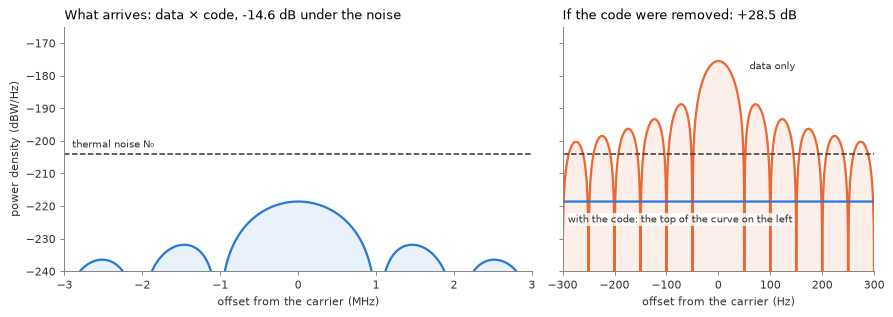

In [22]:
C_DBW, N0_DBW_HZ = -158.5, -204.0          # minimum received power guaranteed by the specification; kT at 290 K

def density_db(f_hz, symbol_time):
    """Power density (dBW/Hz) of a random +/-1 signal of power C with symbols of the given duration."""
    return C_DBW + 10 * np.log10(symbol_time) + 10 * np.log10(np.maximum(np.sinc(f_hz * symbol_time) ** 2, 1e-30))

def fig_density():
    t_chip = 1 / CHIP_RATE
    fig, (ax, az) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, gridspec_kw=dict(width_ratios=[1.5, 1]))
    f = np.linspace(-3e6, 3e6, 3001)
    ax.plot(f / 1e6, density_db(f, t_chip), color=BLUE, lw=1.8)
    ax.fill_between(f / 1e6, density_db(f, t_chip), -260, color=BLUE, alpha=0.1)
    ax.set_xlim(-3, 3); ax.set_xlabel('offset from the carrier (MHz)'); ax.set_ylabel('power density (dBW/Hz)')
    ax.set_title(f'What arrives: data × code, {density_db(0, t_chip) - N0_DBW_HZ:.1f} dB under the noise')
    fz = np.linspace(-300, 300, 1201)
    az.plot(fz, density_db(fz, T_BIT), color=ORANGE, lw=1.8)
    az.fill_between(fz, density_db(fz, T_BIT), -260, color=ORANGE, alpha=0.1)
    az.plot(fz, density_db(fz, t_chip), color=BLUE, lw=1.8)
    az.set_xlim(-300, 300); az.set_xlabel('offset from the carrier (Hz)')
    az.set_title(f'If the code were removed: {density_db(0, T_BIT) - N0_DBW_HZ:+.1f} dB')
    for a in (ax, az):
        a.axhline(N0_DBW_HZ, color=INK, ls='--', lw=1.2)
        a.set_ylim(-240, -165)
    ax.text(-2.9, N0_DBW_HZ + 2, 'thermal noise N₀', fontsize=8, color=INK)
    az.text(-290, -225, 'with the code: the top of the curve on the left', fontsize=8, color=INK,
            bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
    az.text(60, -178, 'data only', fontsize=8, color=INK)
    fig.tight_layout(); plt.show()

fig_density()

**Left:** the signal as it arrives. Its strongest point is 15 dB (30 times) under the noise floor. No filter can help, because noise and signal occupy the same band. **Right:** the same power, if it were *not* spread, would stand 28 dB above the noise in a band of 100 Hz (note the horizontal axis: hertz, not megahertz).

So the plan of the receiver is clear: remove the code, and the signal comes back out of the noise. Removing the code is easy, since $c(t)^2 = 1$: multiply by the same code again. The hard part is that the copy must be *aligned* with the incoming code, and we do not know the delay. That is part 3.

## 2.3 The front end: from a radio wave to numbers

The antenna delivers a voltage at 1575.42 MHz. The **front end** turns it into samples in three steps:

1. **Amplify and filter** around 1575.42 MHz.
2. **Mix down to 0 Hz.** The signal is multiplied by two local sine waves at $f_{L1}$, 90° apart, and low-pass filtered: the mixing of section 0.3. It gives the two signals $I$ and $Q$, treated as one complex signal $x = I + jQ$. The carrier is gone. What remains of it is a slow rotation of $x$ in the complex plane, at the Doppler frequency. The complex form is what lets the receiver tell a positive Doppler from a negative one (section 0.4).
3. **Sample and quantise.** Here: 4 million samples per second (enough for the ±1 MHz main lobe), 8 bits each for $I$ and $Q$, like a HackRF One.

After the front end, the signal of satellite $i$ is

$$x_i(t) = A_i \;\, d_i\big(t_i^{sv}(t)\big)\;\, c_i\big(t_i^{sv}(t)\big)\;\, e^{\,j\,2\pi f_{L1}\,\left(t_i^{sv}(t) - t\right)}$$

and the samples are the sum of the five $x_i$ plus noise. The key quantity is $t_i^{sv}(t)$: **the time that satellite $i$'s clock showed when the signal now arriving left it.** It is the arrival time minus the travel time (plus the small error of the satellite's clock):

$$t_i^{sv}(t) = t - \tau_i(t) + \Delta t_i^{sv}$$

Everything the journey does is inside this one function. The delay is $\tau_i$. The Doppler shift is its rate of change: when $\tau_i$ shrinks, $t_i^{sv}$ advances faster than $t$, so the code, the data and the carrier phase all run fast together.

This also tells us what the receiver must do. **If it can read $t_i^{sv}$ from the signal, at one instant, for four satellites, it has four travel times.** Parts 3 to 5 do exactly that, in finer and finer steps: first to within a millisecond (which code period?), then a microsecond (which chip?), then a few nanoseconds (which fraction of a chip?), and the message supplies the hours, minutes and seconds.

The amplitude $A_i$ follows from the strength: with noise of variance 1 on each of $I$ and $Q$, $A_i = \sqrt{2\,(C/N_0)_i / f_s}$. For 45 dB-Hz at 4 MHz this is 0.13: each sample is almost pure noise.

The cell below generates the recording. For each block of samples it evaluates $t^{sv}$ for each satellite, looks up the chip and the data bit that the satellite was sending at that time, and rotates the phase.

In [23]:
FS = 4e6                                   # samples per second
SECONDS = 20
T_START = TOW_START - 0.64                 # true GPS time of the first sample (the receiver does not know it)
T_MESSAGE = TOW_START - 6                  # satellite time at which our stretch of message starts
ADC_GAIN = 20                              # noise of 20 units per component, on a scale of -127 to 127

def nav_message(eph):
    """Five subframes as 1500 levels (+1/-1): the end of one frame (subframe 5), then subframes 1 to 4."""
    bits, prev29, prev30 = [], 0, 0
    for j, number in enumerate([5, 1, 2, 3, 4]):
        sent = add_parity(subframe_data(number, T_MESSAGE + 6 * (j + 1), eph), prev29, prev30)
        bits += sent
        prev29, prev30 = sent[-2:]
    return 1 - 2 * np.array(bits, dtype=np.float32)

def make_recording(seed=1):
    """20 s of samples, as the front end would deliver them: int8, columns I and Q."""
    rng = np.random.default_rng(seed)
    block = 80_000                                         # 20 ms
    n_blocks = int(SECONDS * FS) // block
    raw = np.empty((n_blocks * block, 2), np.int8)
    inside = np.arange(block) / block                      # position inside the block, 0 to 1
    edges = np.arange(n_blocks + 1) * block / FS           # time of the block boundaries, since the first sample
    sats = []
    for prn in PRNS:
        lag, _ = signal_arriving(TRUE_EPH[prn], T_START + edges, TRUE_POS)
        sats.append(dict(code=CODES[prn].astype(np.float32), message=nav_message(TRUE_EPH[prn]),
                         amplitude=float(np.sqrt(2 * 10 ** (CN0_DBHZ[prn] / 10) / FS)),
                         lag=lag))                         # arrival time minus satellite time, at the boundaries
    for b in range(n_blocks):
        x = rng.standard_normal((block, 2), dtype=np.float32).view(np.complex64).ravel()    # noise
        for s in sats:
            lag = s['lag'][b] + (s['lag'][b + 1] - s['lag'][b]) * inside       # varies smoothly: interpolate
            t_sv = (T_START - T_MESSAGE) + edges[b] + inside * (block / FS) - lag   # satellite time, since the message start
            chip = (t_sv * CHIP_RATE).astype(np.int64) % N                     # which chip was being sent
            bit = (t_sv / T_BIT).astype(np.int64)                              # which data bit
            turns = -F_L1 * lag                                                # carrier phase, in turns
            turns -= np.floor(turns)
            x += s['amplitude'] * s['code'][chip] * s['message'][bit] * np.exp(2j * np.pi * turns.astype(np.float32))
        raw[b * block:(b + 1) * block] = np.clip(np.rint(ADC_GAIN * x.view(np.float32).reshape(-1, 2)), -127, 127)
    truth = {prn: dict(lag=s['lag'], message=s['message']) for prn, s in zip(PRNS, sats)}   # kept only to check results
    return raw, truth

_t = time.time()
RAW, TRUTH = make_recording()
print(f'{len(RAW):,} samples generated in {time.time() - _t:.0f} s ({RAW.nbytes / 1e6:.0f} MB)')

def samples(start, n):
    """n complex samples of the recording, from sample number `start`."""
    return RAW[start:start + n].astype(np.float32).view(np.complex64).ravel()

80,000,000 samples generated in 15 s (160 MB)


## 2.4 Looking at the recording

This is all the receiver gets: 80 million pairs of small integers. Five satellites are in there.

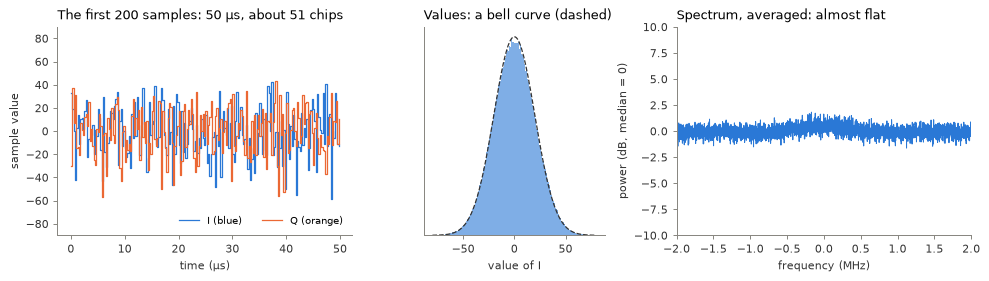

All five signals together carry 4.1 % of the power of the noise.


In [24]:
def spectrum_db(x, n_fft=4096):
    """Average power spectrum of x (dB), by averaging the spectra of successive pieces."""
    pieces = x[:len(x) // n_fft * n_fft].reshape(-1, n_fft) * np.hanning(n_fft)
    power = (np.abs(np.fft.fftshift(np.fft.fft(pieces, axis=1), axes=1)) ** 2).mean(0)
    return np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / FS)), 10 * np.log10(power)

def fig_recording():
    x = samples(0, 400_000)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[1.3, 0.8, 1.3]))
    t_us = np.arange(200) / FS * 1e6
    a1.step(t_us, x.real[:200], where='post', color=BLUE, lw=1, label='I')
    a1.step(t_us, x.imag[:200], where='post', color=ORANGE, lw=1, label='Q')
    a1.set_xlabel('time (µs)'); a1.set_ylabel('sample value'); a1.set_ylim(-90, 90)
    a1.legend(['I (blue)', 'Q (orange)'], loc='lower right', ncol=2, fontsize=8)
    a1.set_title('The first 200 samples: 50 µs, about 51 chips')
    values = np.arange(-80, 81)
    a2.hist(x.real, bins=np.arange(-80.5, 81), color=BLUE, alpha=0.6)
    a2.plot(values, len(x) * np.exp(-values ** 2 / (2 * ADC_GAIN ** 2)) / np.sqrt(2 * np.pi * ADC_GAIN ** 2),
            color=INK, lw=1, ls='--')
    a2.set_xlabel('value of I'); a2.set_yticks([]); a2.set_title('Values: a bell curve (dashed)')
    f, p = spectrum_db(x)
    a3.plot(f / 1e6, p - np.median(p), color=BLUE, lw=0.8)
    a3.set_ylim(-10, 10); a3.set_xlim(-2, 2); a3.set_xlabel('frequency (MHz)'); a3.set_ylabel('power (dB, median = 0)')
    a3.set_title('Spectrum, averaged: almost flat')
    fig.tight_layout(); plt.show()

fig_recording()
power_ratio = sum(2 * 10 ** (CN0_DBHZ[p] / 10) / FS for p in PRNS) / 2
print(f'All five signals together carry {100 * power_ratio:.1f} % of the power of the noise.')

The samples look like noise, and their values follow the bell curve of noise. The spectrum, averaged over a tenth of a second, is flat except for a swelling of less than 1 dB in the middle: that is the five signals together, a few percent of the noise power, spread over 2 MHz. Nothing in it tells one satellite from another, or says how many there are.

**Where we are.** We have a recording, and we know what is hidden in it: for each satellite, a code and a message, delayed and Doppler-shifted. The receiver knows the 32 possible codes, and nothing else.

# Part 3. Finding and following the satellites

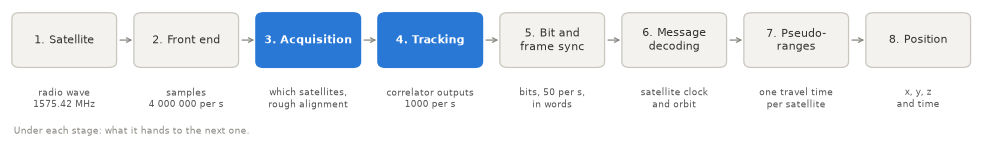

In [25]:
pipeline_map(3, 4)

## 3.1 The one operation of a GNSS receiver: correlation

Almost everything a receiver does to the samples is one operation, repeated. Take one millisecond of samples (one code period, 4000 samples), multiply them by a **replica** of what we expect, and add up:

$$P = \sum_{n=0}^{3999} x[n]\;\cdot\; \underbrace{c_i\!\left(\tfrac{n}{f_s} - \hat\tau\right)}_{\text{code replica}} \;\cdot\; \underbrace{e^{-j 2\pi \hat f\, n / f_s}}_{\text{carrier replica}}$$

The replica has two parts and two settings. The code replica is the code of satellite $i$, delayed by our guess $\hat\tau$. The carrier replica rotates backwards at our guess $\hat f$ of the Doppler frequency, to stop the rotation of the incoming signal. The result $P$ is one complex number, called a **correlator output**.

**If both guesses are right**, the code replica cancels the code ($c^2 = 1$) and the carrier replica stops the rotation. Every one of the 4000 products is then the same constant, $A\,d$, plus noise. Adding them:

- the signal part adds up in step: 4000 times larger;
- the noise part adds up at random: only $\sqrt{4000}$ times larger.

So the signal-to-noise ratio in power improves by a factor 4000 (36 dB). This is the **processing gain**, and it is the right-hand panel of the figure in 2.2 put to work: after the sum, the signal stands at $2\,(C/N_0)\,T$ above the noise, about 18 dB for 45 dB-Hz and $T = 1$ ms. The signals of the other satellites are multiplied by a code that is not theirs and stay spread: they add up like noise.

**If the code delay is wrong** by more than one chip, the products are +1 and −1 in equal numbers and the sum is close to zero. That is the correlation property of section 1.2. Within one chip, the sum falls off linearly: $R(\Delta\tau) = 1 - |\Delta\tau|$, a triangle.

**If the frequency is wrong** by $\Delta f$, the products keep rotating during the sum and partly cancel. The loss is $|\mathrm{sinc}(\Delta f\, T)|$: nothing is left when the error is $1/T = 1$ kHz, one full turn during the sum.

Together: $|P| \approx 4000\, A\; R(\Delta\tau)\; |\mathrm{sinc}(\Delta f\, T)|$. The signal appears only when the replica matches in **both** delay and frequency.

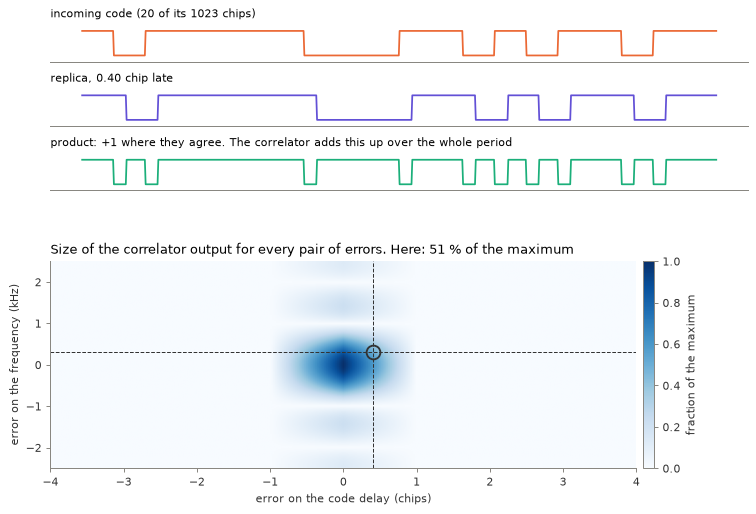

In [26]:
def triangle(code_err):
    """Correlation of a code with a copy shifted by a fraction of a chip (linear between whole shifts)."""
    whole = correlation(CODES[1], CODES[1]) / N
    tau = np.asarray(code_err, float)
    n = np.floor(tau).astype(int)
    return (1 - (tau - n)) * whole[n % N] + (tau - n) * whole[(n + 1) % N]

def fig_correlator(code_err=0.4, doppler_err=300):
    value = float(abs(triangle(code_err)) * abs(np.sinc(doppler_err * T_CODE)))
    fig = plt.figure(figsize=(10, 6.4))
    outer = fig.add_gridspec(2, 1, height_ratios=[1, 1.25], hspace=0.38)
    top = outer[0].subgridspec(3, 1, hspace=0.75)
    x = np.linspace(3, 23, 20 * 40, endpoint=False)
    incoming = CODES[1][np.floor(x).astype(int) % N]
    replica = CODES[1][np.floor(x - code_err).astype(int) % N]
    for k, (y, colour, label) in enumerate([
            (incoming, ORANGE, 'incoming code (20 of its 1023 chips)'),
            (replica, VIOLET, f'replica, {abs(code_err):.2f} chip {"late" if code_err >= 0 else "early"}'),
            (incoming * replica, AQUA, 'product: +1 where they agree. The correlator adds this up over the whole period')]):
        ax = fig.add_subplot(top[k])
        ax.plot(x, y, color=colour, lw=1.4)
        ax.set_ylim(-1.5, 1.5); ax.set_yticks([]); ax.set_xticks([]); ax.set_title(label, fontsize=9)
        ax.spines['left'].set_visible(False)
    ax = fig.add_subplot(outer[1])
    tau = np.linspace(-4, 4, 321); df = np.linspace(-2500, 2500, 201)
    surface = np.abs(triangle(tau))[None, :] * np.abs(np.sinc(df * T_CODE))[:, None]
    im = ax.imshow(surface, extent=[-4, 4, -2.5, 2.5], origin='lower', aspect='auto', cmap='Blues', vmin=0, vmax=1)
    ax.axvline(code_err, color=INK, ls='--', lw=0.8); ax.axhline(doppler_err / 1e3, color=INK, ls='--', lw=0.8)
    ax.plot(code_err, doppler_err / 1e3, 'o', mfc='none', mec=INK, ms=11, mew=1.5)
    ax.set_xlabel('error on the code delay (chips)'); ax.set_ylabel('error on the frequency (kHz)')
    ax.set_title(f'Size of the correlator output for every pair of errors. Here: {100 * value:.0f} % of the maximum')
    fig.colorbar(im, ax=ax, pad=0.01, label='fraction of the maximum')
    plt.show()

fig_correlator()

**Explore.** Move the replica in delay and in frequency.

In [27]:
explore(fig_correlator, code_err=slider('error on the code delay (chips)', 0.4, -3.0, 3.0, 0.05, width='420px'),
        doppler_err=slider('error on the frequency (Hz)', 300, -2500, 2500, 50, width='420px'))

## 3.2 Acquisition: search everything once

At the start the receiver knows nothing: not which satellites are in view, not their delays, not their Doppler shifts. **Acquisition** is a brute-force search for the bright spot of the figure above, for each of the 32 codes:

- **Delay:** the code repeats every millisecond, so the start of a code period is somewhere among 4000 samples.
- **Frequency:** between −5 and +5 kHz. One millisecond of summing tolerates an error of a few hundred hertz (the sinc), so steps of 500 Hz are enough: 21 values.

That is 32 × 21 × 4000 correlations of 4000 samples each. Two tricks make it fast and reliable:

1. **All delays at once with the FFT.** Correlating with a code at every shift is the same computation as in section 1.2, and the same shortcut applies: $\mathrm{IFFT}\big(\mathrm{FFT}(x)\cdot\overline{\mathrm{FFT}(c)}\big)$ gives the 4000 delays in one go.
2. **Add up several milliseconds, without the sign.** We compute $|P|^2$ for 10 successive milliseconds and add them. Taking $|\cdot|^2$ first removes the unknown phase and the unknown data bit, which could otherwise make successive milliseconds cancel. The noise averages out and the peak stands clear.

The result for one satellite is a grid of 21 × 4000 numbers. If the satellite is there, one cell is much larger than the rest. We compare the largest cell with the average cell.

32 satellites searched in 0.9 s. Found: PRN [5, 12, 17, 23, 30]
Largest ratio among the 27 others: 3.7


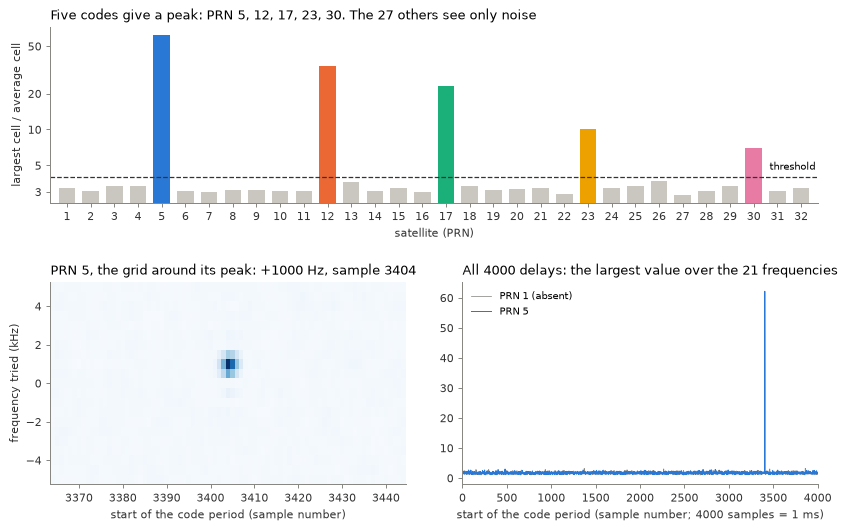

In [28]:
SPMS = int(FS * T_CODE)                    # samples per millisecond: 4000
DOPPLERS = np.arange(-5000, 5001, 500)     # Hz, the frequencies tried
# One period of each code, sampled at our rate
CODE_MS = {prn: CODES[prn][(np.arange(SPMS) * CHIP_RATE / FS).astype(int)].astype(np.float32)
           for prn in range(1, 33)}

def acquire(prn, n_ms=10):
    """Search grid for one satellite: energy of the correlator output for every frequency (rows)
    and every delay (columns), added over n_ms milliseconds."""
    x = samples(0, n_ms * SPMS).reshape(n_ms, SPMS)
    t = np.arange(SPMS) / FS
    code_f = np.conj(np.fft.fft(CODE_MS[prn]))
    grid = np.empty((len(DOPPLERS), SPMS))
    for row, f in enumerate(DOPPLERS):
        stopped = x * np.exp(-2j * np.pi * f * t)                          # carrier replica
        p = np.fft.ifft(np.fft.fft(stopped, axis=1) * code_f, axis=1)      # code replica at all delays
        grid[row] = (np.abs(p) ** 2).sum(0)
    return grid

_t = time.time()
GRIDS = {prn: acquire(prn) for prn in range(1, 33)}
PEAK_RATIO = {prn: g.max() / g.mean() for prn, g in GRIDS.items()}
THRESHOLD = 4.0
FOUND = [prn for prn in GRIDS if PEAK_RATIO[prn] > THRESHOLD]
print(f'32 satellites searched in {time.time() - _t:.1f} s. Found: PRN {FOUND}')
print(f'Largest ratio among the 27 others: {max(r for p, r in PEAK_RATIO.items() if p not in FOUND):.1f}')

def fig_acquisition():
    fig = plt.figure(figsize=(11, 6.6))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.42, wspace=0.16)
    ax = fig.add_subplot(gs[0, :])
    prns = np.arange(1, 33)
    ax.bar(prns, [PEAK_RATIO[p] for p in prns], width=0.7,
           color=[SAT_COLOUR.get(p, GREY) if p in FOUND else '#c9c7bf' for p in prns])
    ax.axhline(THRESHOLD, color=INK, ls='--', lw=1); ax.text(32.6, THRESHOLD + 0.6, 'threshold', ha='right', fontsize=8)
    ax.set_yscale('log'); ax.set_xticks(prns); ax.set_xlim(0.3, 32.7)
    ax.set_yticks([3, 5, 10, 20, 50], ['3', '5', '10', '20', '50']); ax.minorticks_off()
    ax.set_xlabel('satellite (PRN)'); ax.set_ylabel('largest cell / average cell')
    ax.set_title(f'Five codes give a peak: PRN {", ".join(map(str, FOUND))}. The 27 others see only noise')
    prn, absent = FOUND[0], next(p for p in prns if p not in FOUND)
    grid = GRIDS[prn] / GRIDS[prn].mean()
    row, col = np.unravel_index(grid.argmax(), grid.shape)
    lo = int(np.clip(col - 40, 0, SPMS - 81))
    a = fig.add_subplot(gs[1, 0])
    a.imshow(grid[:, lo:lo + 81], extent=[lo - 0.5, lo + 80.5, -5.25, 5.25], origin='lower', aspect='auto',
             cmap='Blues', vmin=0)
    a.set_xlabel('start of the code period (sample number)'); a.set_ylabel('frequency tried (kHz)')
    a.set_title(f'PRN {prn}, the grid around its peak: {DOPPLERS[row]:+d} Hz, sample {col}')
    b = fig.add_subplot(gs[1, 1])
    b.plot((GRIDS[absent] / GRIDS[absent].mean()).max(0), color=GREY, lw=0.6, label=f'PRN {absent} (absent)')
    b.plot(grid.max(0), color=SAT_COLOUR[prn], lw=0.8, label=f'PRN {prn}')
    b.set_xlim(0, SPMS); b.set_xlabel('start of the code period (sample number; 4000 samples = 1 ms)')
    b.set_title('All 4000 delays: the largest value over the 21 frequencies')
    b.legend(loc='upper left', fontsize=8)
    plt.show()

fig_acquisition()

The search found five satellites and, for each, a cell of the grid: a Doppler frequency to within ±250 Hz and the start of the code period to within one sample (a quarter of a chip). The threshold of 4 is set from the 27 absent satellites: for each of them the largest cell is the largest of 84 000 noise values, and it stays between 3 and 4 times the average.

**The delay we just measured is the first rough reading of the satellite clock.** A code period starts at every whole millisecond of satellite time, so we now know *when* each satellite's millisecond ticks arrive, to within 250 ns. What we do not know yet is *which* millisecond each tick is. The message will tell (part 4).

## 3.3 Seeing a signal come out of the noise

Before going on, let us check the central claim of the lecture directly on the samples. Take 10 ms of the recording, multiply it by the code of PRN 5, aligned at the delay just found, and look at the spectrum. No summing this time: just the multiplication by the code.

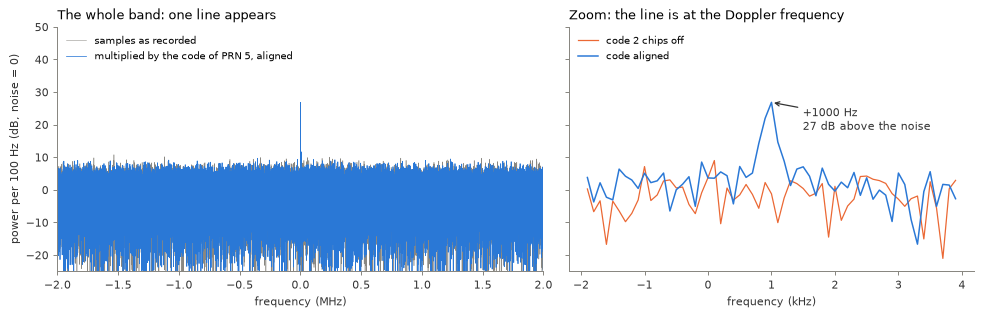

In [29]:
def wipe_code(prn, start, n_ms, shift=0):
    """n_ms milliseconds of samples from `start`, multiplied by the code of prn (optionally misaligned)."""
    return samples(start + shift, n_ms * SPMS) * np.tile(CODE_MS[prn], n_ms)

def acquired_cell(prn):
    row, col = np.unravel_index(GRIDS[prn].argmax(), GRIDS[prn].shape)
    return int(col), float(DOPPLERS[row])              # start of a code period (sample), Doppler (Hz)

def fig_despreading(prn=5):
    start, coarse = acquired_cell(prn)
    n = 10 * SPMS
    f = np.fft.fftshift(np.fft.fftfreq(n, 1 / FS))
    db = lambda x: 10 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(x))) ** 2 / n / (2 * ADC_GAIN ** 2))
    # two successive windows of 10 ms: a data bit can flip in one of them, not in both
    windows = [wipe_code(prn, start + w * n, 10) for w in (0, 1)]
    aligned = max((db(w) for w in windows), key=np.max)
    raw = db(samples(start, n))
    wrong = db(wipe_code(prn, start, 10, shift=8))      # replica 2 chips late
    fig, (ax, az) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, gridspec_kw=dict(width_ratios=[1.2, 1]))
    ax.plot(f / 1e6, raw, color=GREY, lw=0.4, label='samples as recorded')
    ax.plot(f / 1e6, aligned, color=BLUE, lw=0.6, label=f'multiplied by the code of PRN {prn}, aligned')
    ax.set_xlim(-2, 2); ax.set_xlabel('frequency (MHz)'); ax.set_ylabel('power per 100 Hz (dB, noise = 0)')
    ax.set_title('The whole band: one line appears'); ax.legend(loc='upper left', fontsize=8)
    near = np.abs(f - coarse) < 3000
    az.plot(f[near] / 1e3, wrong[near], color=ORANGE, lw=1, label='code 2 chips off')
    az.plot(f[near] / 1e3, aligned[near], color=BLUE, lw=1.2, label='code aligned')
    peak = f[np.argmax(aligned)]
    az.annotate(f'{peak:+.0f} Hz\n{aligned.max():.0f} dB above the noise', (peak / 1e3, aligned.max()),
                xytext=(25, -22), textcoords='offset points', fontsize=8.5, color=INK,
                arrowprops=dict(arrowstyle='->', color=INK))
    az.set_xlabel('frequency (kHz)'); az.set_title('Zoom: the line is at the Doppler frequency')
    az.legend(loc='upper left', fontsize=8)
    ax.set_ylim(-25, 50)
    fig.tight_layout(); plt.show()

fig_despreading()

With the aligned code removed, the 2 MHz of spread power collapses into a single line about 100 Hz wide, far above the noise, at the Doppler frequency of that satellite. Two chips of misalignment, and there is nothing again. The other four satellites are still in these samples, still spread, still invisible.

What is left after removing the code is $A\,d(t)\,e^{j\theta(t)}$: a slowly rotating phasor, flipped by the data. Its rotation rate is the Doppler frequency. Acquisition gave it to ±250 Hz. We can now read it more finely: correlate 20 successive milliseconds at the coarse frequency and delay, and look for the leftover rotation from one millisecond to the next.

In [30]:
def refine_doppler(prn, start, coarse):
    """A finer Doppler: the rotation that remains between 20 successive 1 ms correlator outputs."""
    t = (np.arange(20 * SPMS) / FS).astype(np.float32)
    p = (wipe_code(prn, start, 20) * np.exp(-2j * np.pi * coarse * t)).reshape(20, SPMS).sum(1)
    trial = np.arange(-300.0, 301.0, 2.0)
    stop = np.exp(-2j * np.pi * trial[:, None] * np.arange(10) * T_CODE)
    # two halves of 10 ms, energies added: a data bit flip can spoil one half, not both
    energy = np.abs(stop @ p[:10]) ** 2 + np.abs(stop @ p[10:]) ** 2
    return coarse + trial[energy.argmax()]

def true_values(prn, sample):
    """For checking only: the true satellite time (s since the message start) and Doppler (Hz) at a sample."""
    edges = np.arange(len(TRUTH[prn]['lag'])) * 0.02
    lag = np.interp(sample / FS, edges, TRUTH[prn]['lag'])
    doppler = np.interp(sample / FS, edges[:-1] + 0.01, -F_L1 * np.diff(TRUTH[prn]['lag']) / 0.02)
    return T_START - T_MESSAGE + sample / FS - lag, doppler

SEED = {}
rows = []
for prn in FOUND:
    start, coarse = acquired_cell(prn)
    SEED[prn] = (start, refine_doppler(prn, start, coarse))
    t_sat, doppler = true_values(prn, start)
    chip = (t_sat * CHIP_RATE) % N                      # true code phase at the sample found: should be near 0
    off = min(chip, N - chip) * (1 if chip < N / 2 else -1)
    rows.append(f'| {prn} | {start} | {off:+.2f} chip | {coarse:+.0f} Hz | {SEED[prn][1]:+.0f} Hz | {doppler:+.1f} Hz |')
display(Markdown('| satellite | code period starts at sample | true code position there | Doppler, search | Doppler, refined | true Doppler |\n'
                 '|---|---|---|---|---|---|\n' + '\n'.join(rows)))

| satellite | code period starts at sample | true code position there | Doppler, search | Doppler, refined | true Doppler |
|---|---|---|---|---|---|
| 5 | 3404 | -0.08 chip | +1000 Hz | +966 Hz | +965.2 Hz |
| 12 | 687 | -0.03 chip | -2500 Hz | -2486 Hz | -2487.4 Hz |
| 17 | 2982 | -0.04 chip | +3000 Hz | +3072 Hz | +3073.7 Hz |
| 23 | 3021 | -0.04 chip | -500 Hz | -368 Hz | -365.9 Hz |
| 30 | 1496 | +0.03 chip | +3000 Hz | +2772 Hz | +2770.8 Hz |

The table compares what the receiver found with the truth of the simulation (the receiver itself never sees the last column, nor the third). The delay is right to a fraction of a chip and the refined Doppler to a few hertz.

## 3.4 Tracking: keeping the replica aligned

Acquisition gives a snapshot, and it goes stale quickly. The satellites move: the Doppler frequency drifts by up to 1 Hz every second, and the code slides by up to 3 chips per second. We also need much more precision than a quarter of a chip (75 m), and we need the carrier *phase*, not only its frequency, to read the data.

**Tracking** does this. For every code period, one after the other:

1. **Correlate** the period with the replica at the current settings (delay, frequency, phase).
2. **Measure** how far off the replica was, from the correlator outputs themselves.
3. **Correct** the settings a little, for the next period.

It is the same correlation as before, but only at one point of the grid instead of 84 000, and with a feedback that keeps that point on the peak. There are two feedback loops, one for the carrier and one for the code. The diagram shows both; the next two sections explain the two measurements.

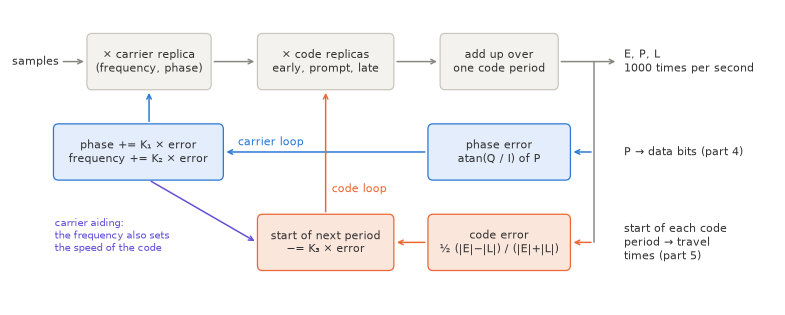

In [31]:
def fig_tracking_loop():
    """Block diagram of the tracking of one satellite."""
    fig, ax = plt.subplots(figsize=(11, 4.3))
    ax.set_xlim(0, 12.6); ax.set_ylim(-0.35, 4.1); ax.axis('off')

    def box(x, y, w, h, text, colour='#f3f2ee', edge='#c9c7bf'):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08', fc=colour, ec=edge, lw=1))
        ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=8.5, color=INK)

    def arrow(start, end, colour=GREY):
        ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color=colour, lw=1.2))

    # forward path
    ax.text(0.05, 3.3, 'samples', fontsize=9, va='center', color=INK)
    box(1.3, 2.9, 2.0, 0.8, '× carrier replica\n(frequency, phase)')
    box(4.1, 2.9, 2.2, 0.8, '× code replicas\nearly, prompt, late')
    box(7.1, 2.9, 1.9, 0.8, 'add up over\none code period')
    arrow((0.85, 3.3), (1.27, 3.3)); arrow((3.33, 3.3), (4.07, 3.3)); arrow((6.33, 3.3), (7.07, 3.3))
    arrow((9.03, 3.3), (10.0, 3.3))
    ax.text(10.1, 3.3, 'E, P, L\n1000 times per second', fontsize=9, va='center', color=INK)
    # carrier loop
    box(6.9, 1.55, 2.3, 0.8, 'phase error\natan(Q / I) of P', '#e3edfb', BLUE)
    box(0.75, 1.55, 2.75, 0.8, 'phase += K₁ × error\nfrequency += K₂ × error', '#e3edfb', BLUE)
    ax.plot([9.6, 9.6], [3.3, 0.6], color=GREY, lw=1.2)
    arrow((9.6, 1.95), (9.23, 1.95), BLUE); arrow((6.87, 1.95), (3.53, 1.95), BLUE); arrow((2.3, 2.37), (2.3, 2.87), BLUE)
    ax.text(4.3, 2.05, 'carrier loop', fontsize=8.5, color=BLUE, ha='center')
    # code loop
    box(6.9, 0.2, 2.3, 0.8, 'code error\n½ (|E|−|L|) / (|E|+|L|)', '#fbe6dc', ORANGE)
    box(4.1, 0.2, 2.2, 0.8, 'start of next period\n−= K₃ × error', '#fbe6dc', ORANGE)
    arrow((9.6, 0.6), (9.23, 0.6), ORANGE); arrow((6.87, 0.6), (6.33, 0.6), ORANGE); arrow((5.2, 1.02), (5.2, 2.87), ORANGE)
    ax.text(5.3, 1.35, 'code loop', fontsize=8.5, color=ORANGE, ha='left')
    # carrier aiding
    arrow((2.3, 1.53), (4.07, 0.6), VIOLET)
    ax.text(0.75, 0.7, 'carrier aiding:\nthe frequency also sets\nthe speed of the code', fontsize=8, color=VIOLET, va='center')
    # what goes on
    ax.text(10.1, 1.95, 'P → data bits (part 4)', fontsize=8.5, color=INK, va='center')
    ax.text(10.1, 0.6, 'start of each code\nperiod → travel\ntimes (part 5)', fontsize=8.5, color=INK, va='center')
    plt.show()

fig_tracking_loop()

### The carrier loop

Call $P = I + jQ$ the correlator output with the aligned ("prompt") code. If the replica's phase is exactly right, the rotation is fully stopped and $P = \pm A$: a real number whose sign is the data bit. If the replica's phase is off by $\varphi$, then $P = \pm A\,e^{j\varphi}$: the same two points, turned by $\varphi$. So the angle of $P$ measures the phase error, and the receiver uses

$$\hat\varphi = \arctan\!\left(\frac{Q}{I}\right)$$

The plain arctangent of the ratio, on purpose: flipping the sign of both $I$ and $Q$ (a data bit) does not change $Q/I$, so the data does not disturb the measurement. A loop built on such a data-insensitive measurement is called a **Costas loop**. Then two corrections:

$$\text{phase} \mathrel{+}= K_1\,\hat\varphi \qquad\qquad \text{frequency} \mathrel{+}= K_2\,\hat\varphi$$

The first removes the error. The second lets the loop follow a frequency that is off or drifting: as long as an error keeps coming back with the same sign, the frequency keeps being adjusted.

The price of ignoring the data sign is that the loop cannot tell a phase error of 0° from one of 180°. It can lock with every bit upside down. Part 4 deals with that.

The figure runs the loop on a model of the correlator outputs (not on the recording yet): 50 bits per second, noise for 42 dB-Hz, a replica that starts 50° and 12 Hz off, and a loop that is switched on after 400 ms.

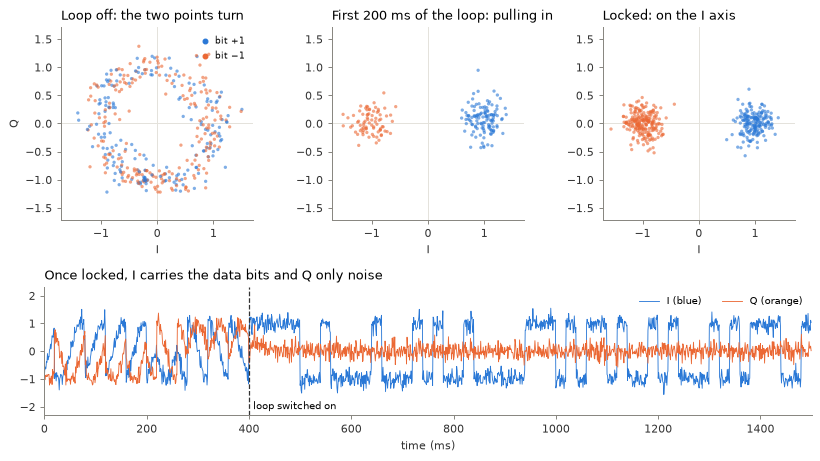

In [32]:
K_PHASE, K_FREQ = 0.2, 1.5          # carrier loop: correction of the phase (rad per rad) and of the frequency (Hz per rad)
K_CODE = 0.005                      # code loop: fraction of the measured error corrected at each period

def wrap(angle):
    return np.arctan2(np.sin(angle), np.cos(angle))

def costas_model(phase_deg=50, freq_hz=12, cn0_dbhz=42, n_ms=1500, close_at_ms=400, seed=1):
    """Correlator outputs of a replica that is off in phase and frequency; the loop starts at close_at_ms."""
    rng = np.random.default_rng(seed)
    bits = rng.choice([-1, 1], n_ms // 20 + 1)
    sigma = 1 / np.sqrt(2 * 10 ** (cn0_dbhz / 10) * T_CODE)       # noise on I and on Q, for a signal of size 1
    err, f = np.radians(phase_deg), float(freq_hz)               # phase and frequency errors of the replica
    out = dict(I=np.empty(n_ms), Q=np.empty(n_ms), bit=np.empty(n_ms), err=np.empty(n_ms), f=np.empty(n_ms),
               close=close_at_ms, sigma=sigma)
    for k in range(n_ms):
        d = bits[k // 20]
        out['I'][k] = d * np.cos(err) + sigma * rng.standard_normal()
        out['Q'][k] = d * np.sin(err) + sigma * rng.standard_normal()
        out['bit'][k], out['err'][k], out['f'][k] = d, err, f
        err = wrap(err + 2 * np.pi * f * T_CODE)                 # a frequency error makes the phase error grow
        if k >= close_at_ms:
            measured = np.arctan(out['Q'][k] / out['I'][k])
            err = wrap(err - K_PHASE * measured)
            f -= K_FREQ * measured
    return out

def fig_costas(phase_deg=50, freq_hz=12, cn0_dbhz=42):
    s = costas_model(phase_deg, freq_hz, cn0_dbhz)
    c = s['close']
    lim = 1 + 4 * s['sigma']
    fig = plt.figure(figsize=(11, 5.6))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.5, 1], hspace=0.42)
    final = np.degrees(s['err'][-1])
    spans = [(0, c, 'Loop off: the two points turn'), (c, c + 200, 'First 200 ms of the loop: pulling in'),
             (len(s['I']) - 400, len(s['I']),
              'Locked' + (': on the I axis' if abs(final) < 90 else ' at 180°: every bit inverted'))]
    for col, (a, b, title) in enumerate(spans):
        ax = fig.add_subplot(gs[0, col])
        colours = np.where(s['bit'][a:b] > 0, BLUE, ORANGE)
        ax.scatter(s['I'][a:b], s['Q'][a:b], s=7, c=colours, alpha=0.6, lw=0)
        ax.axhline(0, color=LIGHT, lw=0.8, zorder=0); ax.axvline(0, color=LIGHT, lw=0.8, zorder=0)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
        ax.set_xlabel('I'); ax.set_title(title)
        if col == 0:
            ax.set_ylabel('Q')
            ax.scatter([], [], s=14, c=BLUE, label='bit +1'); ax.scatter([], [], s=14, c=ORANGE, label='bit −1')
            ax.legend(loc='upper right', fontsize=7.5, handletextpad=0.1)
    ax = fig.add_subplot(gs[1, :])
    t = np.arange(len(s['I']))
    ax.plot(t, s['I'], color=BLUE, lw=0.7, label='I')
    ax.plot(t, s['Q'], color=ORANGE, lw=0.7, label='Q')
    ax.axvline(c, color=INK, ls='--', lw=1)
    ax.text(c + 8, -lim * 1.22, 'loop switched on', fontsize=8, bbox=dict(fc='white', ec='none', pad=1))
    ax.set_xlim(0, len(t)); ax.set_ylim(-lim * 1.35, lim * 1.35); ax.set_xlabel('time (ms)')
    ax.set_title('Once locked, I carries the data bits and Q only noise')
    ax.legend(['I (blue)', 'Q (orange)'], loc='upper right', ncol=2, fontsize=8)
    plt.show()

fig_costas()

**Explore.** Other starting errors and signal strengths. A starting phase near 180° makes the loop lock upside down. Below about 25 dB-Hz it loses lock. The second cell shows a run as a film: press **▶ play**. The two circles mark where the two points would be without noise; the loop's job is to bring them onto the I axis and hold them there.

In [33]:
explore(fig_costas, phase_deg=slider('phase error at the start (°)', 50, -180, 180, 10),
        freq_hz=slider('frequency error at the start (Hz)', 12, -40, 40),
        cn0_dbhz=slider('signal strength C/N₀ (dB-Hz)', 42, 20, 50))

In [34]:
def costas_film(recent=150):
    """A run of the carrier loop as a film. Left: the correlator outputs of the last `recent` ms in the
    I/Q plane. Right: I and Q since the start."""
    view = {}

    def build(phase_deg, freq_hz, cn0_dbhz):
        s = costas_model(phase_deg, freq_hz, cn0_dbhz)
        n_ms, lim = len(s['I']), 1 + 4 * s['sigma']
        fig, (ax, az) = plt.subplots(1, 2, figsize=(10, 4.3), gridspec_kw=dict(width_ratios=[1, 1.7]))
        ax.axhline(0, color=LIGHT, lw=0.8); ax.axvline(0, color=LIGHT, lw=0.8)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal'); ax.set_xlabel('I'); ax.set_ylabel('Q')
        ax.set_title(f'The last {recent} ms (blue: bit +1, orange: bit −1)')
        az.axhline(0, color=LIGHT, lw=0.8); az.axvline(s['close'], color=INK, ls='--', lw=1)
        az.text(s['close'] + 12, -lim * 1.2, 'loop switched on', fontsize=8)
        az.set_xlim(0, n_ms); az.set_ylim(-lim * 1.35, lim * 1.35); az.set_xlabel('time (ms)')
        az.set_title('I (blue) and Q (orange) since the start')
        fig.tight_layout()
        v = dict(s=s, lim=lim,
                 axis=ax.plot([], [], color=GREY, lw=1)[0],                   # where the two points are without noise
                 ideal=ax.plot([], [], 'o', mfc='none', mec=INK, ms=9, mew=1.3)[0],
                 cloud=ax.scatter([], [], s=12, lw=0),
                 line_i=az.plot([], [], color=BLUE, lw=0.7)[0], line_q=az.plot([], [], color=ORANGE, lw=0.7)[0],
                 status=az.text(0.015, 0.94, '', transform=az.transAxes, family='monospace', fontsize=8.5, va='top',
                                bbox=dict(fc='white', ec='none', alpha=0.85, pad=2)))
        v['quick'] = Quick(fig, [v['axis'], v['cloud'], v['ideal'], v['line_i'], v['line_q'], v['status']])
        return v

    def draw(phase_deg, freq_hz, cn0_dbhz, now):
        if view.get('settings') != (phase_deg, freq_hz, cn0_dbhz):
            view.update(build(phase_deg, freq_hz, cn0_dbhz), settings=(phase_deg, freq_hz, cn0_dbhz))
        s, k = view['s'], max(int(now), 1)
        k0, err = max(0, k - recent), s['err'][k - 1]
        point = np.array([np.cos(err), np.sin(err)])
        view['axis'].set_data(*np.outer([-view['lim'], view['lim']], point).T)
        view['ideal'].set_data(*np.outer([-1, 1], point).T)
        colours = np.where(s['bit'][k0:k, None] > 0, [[0.165, 0.471, 0.839]], [[0.922, 0.408, 0.204]])
        view['cloud'].set_offsets(np.c_[s['I'][k0:k], s['Q'][k0:k]])
        view['cloud'].set_facecolors(np.c_[colours, np.linspace(0.15, 0.9, k - k0)])      # the oldest points fade
        view['line_i'].set_data(np.arange(k), s['I'][:k]); view['line_q'].set_data(np.arange(k), s['Q'][:k])
        view['status'].set_text(f't = {k:4d} ms   loop {"off" if k <= s["close"] else "on "}   '
                                f'phase error {np.degrees(err):+5.0f}°   frequency error {s["f"][k - 1]:+6.1f} Hz')
        return view['quick'].png()
    return draw

now = slider('time (ms)', 0, 0, 1500, 10, width='460px')
explore(costas_film(), play_button(now),
        phase_deg=slider('phase error at the start (°)', 50, -180, 180, 10),
        freq_hz=slider('frequency error at the start (Hz)', 12, -40, 40),
        cn0_dbhz=slider('signal strength C/N₀ (dB-Hz)', 42, 20, 50), now=now)

### The code loop

The carrier loop needs the code replica to stay aligned, and the alignment is also the measurement we want in the end. To measure a code misalignment, the receiver computes two more correlator outputs, with the same samples and two shifted copies of the code replica:

- **Early** ($E$): the replica half a chip ahead of the prompt one;
- **Late** ($L$): the replica half a chip behind.

The three outputs sample the correlation triangle at three points, half a chip apart. If the prompt replica is exactly aligned, $E$ and $L$ sit symmetrically on the two slopes and have the same size. If the replica is late, the Early copy is closer to the truth, and $|E| > |L|$. The measurement is

$$\hat\varepsilon = \frac{1}{2}\,\frac{|E| - |L|}{|E| + |L|}\quad\text{chips}$$

Dividing by the sum removes the unknown amplitude; the absolute values remove the data bit and any phase error. The correction is to shift the start of the next code period by a small fraction $K_3$ of $\hat\varepsilon$. The fraction is small (0.5 %) so that the noise of 200 successive measurements is averaged: this is where the nanoseconds come from.

One more link: the Doppler effect compresses the code and the carrier in the same proportion. So the code replica is clocked at $1.023\ \text{MHz} \times (1 + \hat f / f_{L1})$, with $\hat f$ taken from the carrier loop. The carrier loop, which is very precise, does most of the work of following the motion, and the code loop only has to remove what is left. This is called **carrier aiding**.

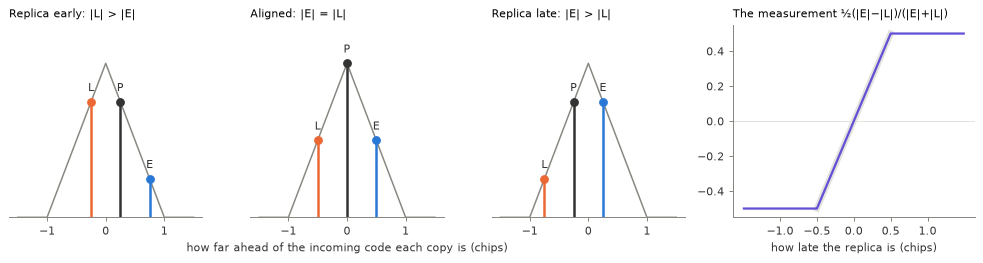

In [35]:
def fig_early_late():
    fig, axs = plt.subplots(1, 4, figsize=(11, 3), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.25]))
    tau = np.linspace(-1.5, 1.5, 301)
    tri = np.clip(1 - np.abs(tau), 0, None)
    for ax, err, title in zip(axs, (-0.25, 0.0, 0.25), ('Replica early: |L| > |E|', 'Aligned: |E| = |L|',
                                                        'Replica late: |E| > |L|')):
        ax.plot(tau, tri, color=GREY, lw=1.2)
        for shift, name, colour in ((-0.5, 'L', ORANGE), (0, 'P', INK), (0.5, 'E', BLUE)):
            x = shift - err                                   # how far ahead of the incoming code this copy is
            ax.plot([x, x], [0, max(1 - abs(x), 0)], color=colour, lw=2)
            ax.plot(x, max(1 - abs(x), 0), 'o', color=colour, ms=6)
            ax.text(x, max(1 - abs(x), 0) + 0.07, name, ha='center', fontsize=9, color=INK)
        ax.set_ylim(0, 1.25); ax.set_yticks([]); ax.set_xticks([-1, 0, 1]); ax.set_title(title, fontsize=9)
        ax.spines['left'].set_visible(False)
    axs[1].set_xlabel('how far ahead of the incoming code each copy is (chips)')
    err = np.linspace(-1.5, 1.5, 301)
    e, l = np.clip(1 - np.abs(err - 0.5), 0, None), np.clip(1 - np.abs(err + 0.5), 0, None)
    with np.errstate(invalid='ignore', divide='ignore'):
        axs[3].plot(err, 0.5 * (e - l) / (e + l), color=VIOLET, lw=1.8)
    axs[3].plot([-0.5, 0.5], [-0.5, 0.5], color=LIGHT, lw=5, zorder=0)
    axs[3].axhline(0, color=LIGHT, lw=0.8, zorder=0)
    axs[3].set_xlabel('how late the replica is (chips)'); axs[3].set_title('The measurement ½(|E|−|L|)/(|E|+|L|)', fontsize=9)
    axs[3].set_xticks([-1, -0.5, 0, 0.5, 1])
    fig.tight_layout(); plt.show()

fig_early_late()

Within half a chip, the measurement *is* the error (right panel). Further away it saturates but keeps the correct sign, up to one and a half chips. Beyond that the triangle is left behind and the loop is lost: this is why acquisition had to deliver the delay to within a fraction of a chip.

### The tracking loop, complete

Here is the whole loop for one satellite. Each pass of the `for` handles one code period: about 4000 samples in, three complex numbers out, three settings corrected.

In [36]:
def track(prn, start, doppler, n_periods):
    """Follow one satellite for n_periods code periods, from the delay and Doppler found by acquisition."""
    code = CODES[prn].astype(np.float32)
    code = np.r_[code[-1], code, code[0]]            # one chip added at each end, for the Early and Late copies
    out = dict(E=np.zeros(n_periods, complex), P=np.zeros(n_periods, complex), L=np.zeros(n_periods, complex),
               doppler=np.zeros(n_periods), begin=np.zeros(n_periods))
    begin, phase, f = float(start), 0.0, float(doppler)       # the three settings of the replica
    for k in range(n_periods):
        # 1. Correlate one code period
        chips_per_sample = CHIP_RATE * (1 + f / F_L1) / FS    # carrier aiding: the Doppler stretches the code too
        end = begin + N / chips_per_sample                    # where this period ends (not a whole sample)
        first, last = int(np.ceil(begin)), int(np.ceil(end))
        n = np.arange(last - first)
        x = samples(first, last - first)
        x = x * np.exp(-1j * (phase + 2 * np.pi * f / FS * n).astype(np.float32))    # carrier replica
        chip = (first - begin + n) * chips_per_sample         # position of each sample in the code, 0 to 1023
        E = complex(x @ code[(chip + 1.5).astype(int)])       # replica half a chip ahead
        P = complex(x @ code[(chip + 1.0).astype(int)])       # prompt
        L = complex(x @ code[(chip + 0.5).astype(int)])       # replica half a chip behind
        # 2. Measure the errors
        phase_err = np.arctan(P.imag / P.real)
        code_err = 0.5 * (abs(E) - abs(L)) / (abs(E) + abs(L))
        out['E'][k], out['P'][k], out['L'][k], out['doppler'][k], out['begin'][k] = E, P, L, f, begin
        # 3. Correct the settings for the next period
        phase = (phase + 2 * np.pi * f / FS * (last - first) + K_PHASE * phase_err) % (2 * np.pi)
        f += K_FREQ * phase_err
        begin = end - K_CODE * code_err / chips_per_sample
    return out

_t = time.time()
N_PERIODS = len(RAW) // SPMS - 3
TRACK = {prn: track(prn, *SEED[prn], N_PERIODS) for prn in FOUND}
print(f'{len(FOUND)} satellites tracked for {N_PERIODS / 1000:.1f} s each, in {time.time() - _t:.0f} s')

5 satellites tracked for 20.0 s each, in 16 s


## 3.5 What tracking delivers

First, the lock itself, on the recording this time. The figure shows the satellite whose replica started with the largest phase error.

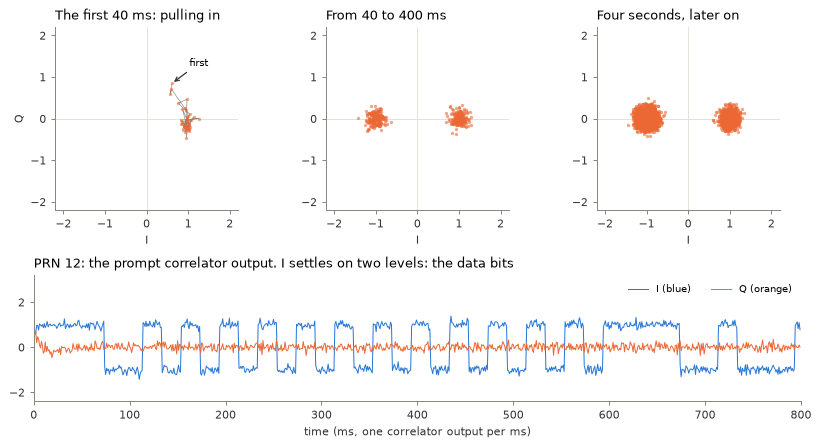

In [37]:
def fig_lock():
    # the satellite whose replica started furthest from the right phase
    prn = max(FOUND, key=lambda p: abs(np.arctan(TRACK[p]['P'][0].imag / TRACK[p]['P'][0].real)))
    P = TRACK[prn]['P'] / np.abs(TRACK[prn]['P'][500:]).mean()
    fig = plt.figure(figsize=(11, 5.4))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.45, 1], hspace=0.42)
    for col, (a, b, title) in enumerate([(0, 40, 'The first 40 ms: pulling in'),
                                         (40, 400, 'From 40 to 400 ms'), (2000, 6000, 'Four seconds, later on')]):
        ax = fig.add_subplot(gs[0, col])
        ax.scatter(P.real[a:b], P.imag[a:b], s=7, color=SAT_COLOUR[prn], alpha=0.6, lw=0)
        ax.axhline(0, color=LIGHT, lw=0.8, zorder=0); ax.axvline(0, color=LIGHT, lw=0.8, zorder=0)
        ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_aspect('equal'); ax.set_xlabel('I'); ax.set_title(title)
        if col == 0:
            ax.set_ylabel('Q')
            ax.plot(P.real[a:b], P.imag[a:b], color=GREY, lw=0.5, zorder=0)
            ax.annotate('first', (P.real[0], P.imag[0]), xytext=(14, 14), textcoords='offset points', fontsize=8,
                        arrowprops=dict(arrowstyle='->', color=INK))
    ax = fig.add_subplot(gs[1, :])
    t = np.arange(800)
    ax.plot(t, P.real[:800], color=BLUE, lw=0.8)
    ax.plot(t, P.imag[:800], color=ORANGE, lw=0.8)
    ax.set_xlim(0, 800); ax.set_ylim(-2.4, 3.2); ax.set_xlabel('time (ms, one correlator output per ms)')
    ax.set_title(f'PRN {prn}: the prompt correlator output. I settles on two levels: the data bits')
    ax.legend(['I (blue)', 'Q (orange)'], loc='upper right', ncol=2, fontsize=8)
    plt.show()

fig_lock()

Each point is one millisecond of samples, reduced to one complex number. After a few tens of milliseconds the points settle in two clouds on the $I$ axis: the replica is locked in phase, and the sign of $I$ is the data.

Next, the three settings of the replica over the whole recording, compared with the truth of the simulation.

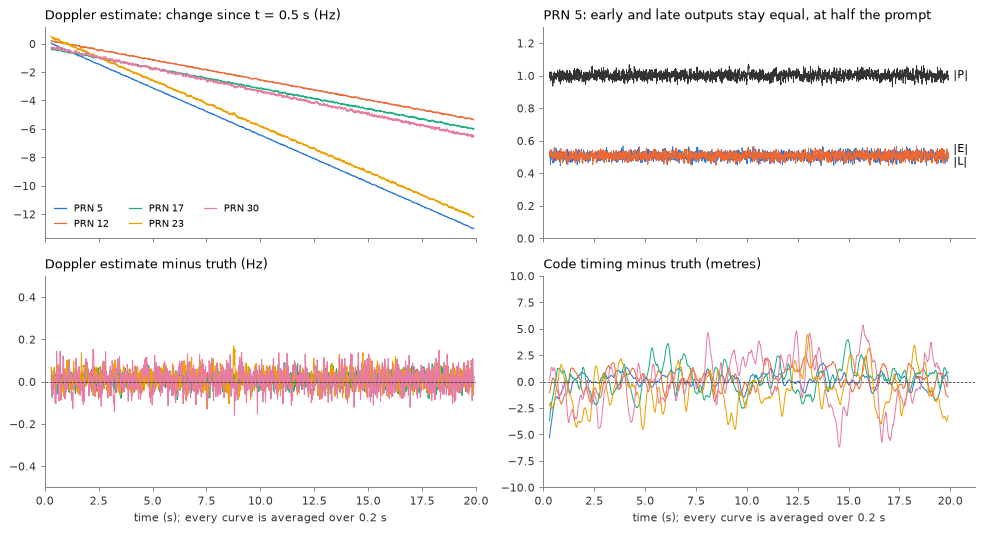

| satellite | strength set in the simulation | strength measured from P | Doppler noise, per ms | code timing noise | code timing bias |
|---|---|---|---|---|---|
| 5 | 49 dB-Hz | 48.2 dB-Hz | 0.2 Hz | 0.8 m | +0.2 m |
| 12 | 46 dB-Hz | 45.0 dB-Hz | 0.3 Hz | 1.1 m | +0.3 m |
| 17 | 44 dB-Hz | 42.9 dB-Hz | 0.4 Hz | 1.5 m | +0.3 m |
| 23 | 41 dB-Hz | 39.8 dB-Hz | 0.5 Hz | 2.0 m | -0.7 m |
| 30 | 39 dB-Hz | 37.9 dB-Hz | 0.7 Hz | 2.6 m | -0.0 m |

In [38]:
def tracking_errors(prn):
    """For checking only: the error of the Doppler estimate (Hz) and of the code timing (m) at each period."""
    tr = TRACK[prn]
    t_sat, doppler = true_values(prn, tr['begin'])
    ms = t_sat / T_CODE                                  # a code period starts when this is a whole number
    return tr['doppler'] - doppler, (ms - np.rint(ms)) * T_CODE * C_LIGHT

def fig_tracking():
    fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex='col')
    t = np.arange(N_PERIODS) / 1000
    smooth = lambda y, w=200: np.convolve(y, np.ones(w) / w, mode='same')
    inside = slice(300, N_PERIODS - 100)                 # leave out the edges of the moving average
    for prn in FOUND:
        tr, colour = TRACK[prn], SAT_COLOUR[prn]
        f_err, code_err = tracking_errors(prn)
        axs[0, 0].plot(t[inside], smooth(tr['doppler'] - tr['doppler'][500])[inside], color=colour, lw=1, label=f'PRN {prn}')
        axs[1, 0].plot(t[inside], smooth(f_err)[inside], color=colour, lw=0.8)
        axs[1, 1].plot(t[inside], smooth(code_err)[inside], color=colour, lw=0.8)
    strongest = TRACK[FOUND[0]]
    level = np.abs(strongest['P']).mean()
    for name, colour in (('P', INK), ('E', BLUE), ('L', ORANGE)):
        axs[0, 1].plot(t[inside], smooth(np.abs(strongest[name]), 20)[inside] / level, color=colour, lw=0.6)
        axs[0, 1].text(20.15, np.abs(strongest[name]).mean() / level + (0.04 if name == 'E' else -0.04 if name == 'L' else 0),
                       f'|{name}|', fontsize=8.5, va='center')
    axs[0, 0].set_title('Doppler estimate: change since t = 0.5 s (Hz)')
    axs[0, 0].legend(loc='lower left', ncol=3, fontsize=8, handlelength=1.2)
    axs[1, 0].set_title('Doppler estimate minus truth (Hz)'); axs[1, 0].set_ylim(-0.5, 0.5)
    axs[0, 1].set_title(f'PRN {FOUND[0]}: early and late outputs stay equal, at half the prompt'); axs[0, 1].set_ylim(0, 1.3)
    axs[1, 1].set_title('Code timing minus truth (metres)'); axs[1, 1].set_ylim(-10, 10)
    for ax in axs[1]:
        ax.axhline(0, color=INK, lw=0.6, ls='--'); ax.set_xlabel('time (s); every curve is averaged over 0.2 s')
    axs[0, 0].set_xlim(0, 20); axs[0, 1].set_xlim(0, 21.2)
    fig.tight_layout(); plt.show()

fig_tracking()

rows = []
for prn in FOUND:
    P = TRACK[prn]['P'][1000:]
    cn0 = 10 * np.log10(np.abs(P.real).mean() ** 2 / (2 * P.imag.var() * T_CODE))
    f_err, code_err = tracking_errors(prn)
    rows.append(f'| {prn} | {CN0_DBHZ[prn]} dB-Hz | {cn0:.1f} dB-Hz | {f_err[1000:].std():.1f} Hz | '
                f'{code_err[1000:].std():.1f} m | {code_err[1000:].mean():+.1f} m |')
display(Markdown('| satellite | strength set in the simulation | strength measured from P | Doppler noise, per ms | '
                 'code timing noise | code timing bias |\n|---|---|---|---|---|---|\n' + '\n'.join(rows)))

The loops follow each satellite for the whole recording. The Doppler estimates drift slowly, as the geometry changes, and stay within a fraction of a hertz of the truth once averaged. The code timing is right to within a few metres, better for the strong satellites. The strength measured from the correlator outputs alone (the level of $I$ against the scatter of $Q$) is within about 1 dB of what the simulation put in. It reads slightly low because the scatter of $Q$ is not only thermal noise: it also contains the small phase jitter of the loop itself and a little of the four other satellites. (The level of $I$ is right to 0.1 dB.)

**What tracking hands on.** For each satellite, 1000 times per second:

- the prompt output $P_k$. Its real part carries the data bits. Part 4 turns it into the message.
- `begin[k]`: the position in the recording, to a small fraction of a sample, where code period $k$ starts. These are the ticks of the satellite's clock, one per satellite millisecond, timed against the receiver's sample counter. Part 5 turns them into travel times.

The samples themselves are no longer needed. 160 MB of recording have become a few thousand numbers per second.

# Part 4. From correlator outputs to the message

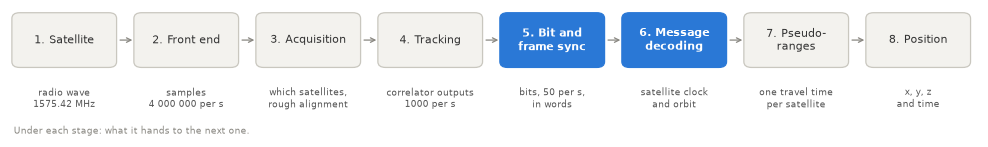

In [39]:
pipeline_map(5, 6)

Tracking has reduced each satellite to a stream of numbers $I_k$, one per millisecond, whose sign is the data. Four steps turn this stream into the fields of the navigation message. Each one answers a question of the form "where does it start?":

1. **Bit synchronisation:** where do the bits start, among the milliseconds?
2. **Bit decision:** what is the value of each bit?
3. **Frame synchronisation:** where do the subframes start, among the bits? And are the bits to be trusted?
4. **Decoding:** which bits form which number?

## 4.1 Bit synchronisation: which 20 milliseconds belong together?

A data bit lasts 20 code periods, so 20 successive values of $I_k$ carry the same bit. But the tracking loop started on an arbitrary millisecond: the first bit boundary may be at any of 20 positions.

The data itself gives the answer. The sign of $I_k$ can only flip where one bit ends and the next begins. So we note every $k$ at which $I_k$ and $I_{k-1}$ have opposite signs, and count them according to $k \bmod 20$. The flips caused by data all fall in the same one of the 20 positions. Noise can also flip a sign, but anywhere.

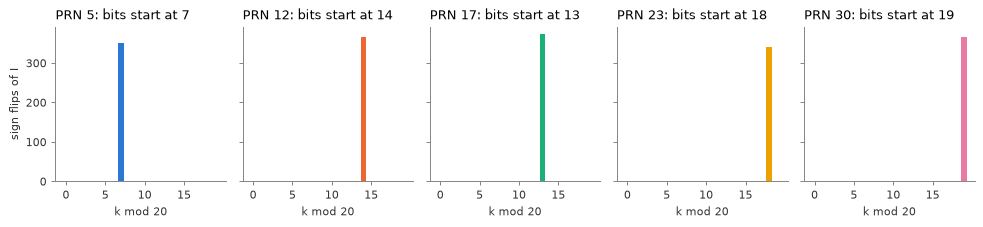

In [40]:
SETTLE = 500        # code periods skipped at the start, while the loops pull in

def bit_boundary(I):
    """Count the sign flips of I at each of the 20 positions; the bits start where they pile up."""
    flips = np.flatnonzero(np.sign(I[SETTLE + 1:]) != np.sign(I[SETTLE:-1])) + SETTLE + 1
    counts = np.bincount(flips % 20, minlength=20)
    return int(counts.argmax()), counts

def fig_bit_sync():
    fig, axs = plt.subplots(1, len(FOUND), figsize=(11, 2.6), sharey=True)
    for ax, prn in zip(axs, FOUND):
        boundary, counts = bit_boundary(TRACK[prn]['P'].real)
        ax.bar(range(20), counts, width=0.7, color=[SAT_COLOUR[prn] if i == boundary else '#c9c7bf' for i in range(20)])
        ax.set_xticks([0, 5, 10, 15]); ax.set_xlabel('k mod 20')
        ax.set_title(f'PRN {prn}: bits start at {boundary}')
    axs[0].set_ylabel('sign flips of I')
    fig.tight_layout(); plt.show()

fig_bit_sync()

With signals of this strength the answer is immediate: almost every flip is a real bit edge. (Not every boundary shows a flip: a bit is often followed by an identical one.) The satellites have different boundaries because their signals do not travel for the same time, and because each loop started on its own millisecond.

**Explore.** With a weak signal the picture is less clean: noise flips the sign of single milliseconds everywhere, and the receiver must count for longer before one position stands out. The model below draws $I_k$ for a chosen strength and duration (true boundary: position 7).

In [41]:
def fig_bit_sync_model(cn0_dbhz=30, seconds=1):
    rng = np.random.default_rng(3)
    k = np.arange(seconds * 1000)
    bit_number = (k + 13) // 20                       # a new bit starts whenever k mod 20 = 7
    bits = rng.choice([-1, 1], bit_number.max() + 1)
    sigma = 1 / np.sqrt(2 * 10 ** (cn0_dbhz / 10) * T_CODE)
    I = bits[bit_number] + sigma * rng.standard_normal(len(k))
    flips = np.flatnonzero(np.sign(I[1:]) != np.sign(I[:-1])) + 1
    counts = np.bincount(flips % 20, minlength=20)
    best = counts.argmax()
    clear = counts.max() > counts.mean() + 3 * np.sqrt(counts.mean() + 1)
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.bar(range(20), counts, width=0.7, color=[BLUE if i == best and clear else '#c9c7bf' for i in range(20)])
    ax.set_xticks(range(20)); ax.set_xlabel('k mod 20'); ax.set_ylabel('sign flips of I')
    ax.set_title(f'{cn0_dbhz} dB-Hz, {seconds} s: ' + (f'bits start at {best}' if clear else 'not clear yet'))
    plt.show()

explore(fig_bit_sync_model, cn0_dbhz=slider('signal strength C/N₀ (dB-Hz)', 30, 18, 45),
        seconds=slider('how long the receiver counts (s)', 1, 1, 20))

## 4.2 Bit decision: add 20 milliseconds, take the sign

Knowing where the bits start, we add the 20 values of $I_k$ of each bit and look at the sign of the sum. This is the same idea as the correlator, one level up: the signal adds in step, the noise does not, and the signal-to-noise ratio improves by another factor 20 (13 dB).

The ratio that matters for a bit is $E_b/N_0$, the energy of one bit over the noise density: $E_b/N_0 = (C/N_0) \times T_b$, that is $C/N_0$ minus 17 dB. The probability of a wrong bit is $\tfrac12\,\mathrm{erfc}\sqrt{E_b/N_0}$. Even our weakest satellite (39 dB-Hz, so 22 dB) will not give one wrong bit in the age of the universe. At 25 dB-Hz the rate would be about 2 in 10 000 bits, and that is roughly where receivers stop being able to read the message, although they can still measure the code timing.

By convention, a negative sum is read as bit 1 (level −1).

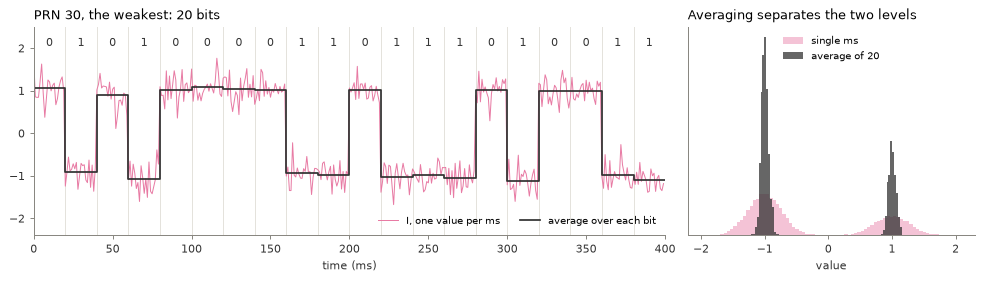

| satellite | bits read | compared with the bits sent |
|---|---|---|
| 5 | 974 | all correct |
| 12 | 974 | every bit inverted |
| 17 | 974 | every bit inverted |
| 23 | 973 | all correct |
| 30 | 973 | every bit inverted |

In [42]:
def read_bits(I, boundary):
    """Add up I over each bit. Returns the code period where the first complete bit starts, and the sums."""
    first = SETTLE + (boundary - SETTLE) % 20
    n_bits = (len(I) - first) // 20
    return first, I[first:first + 20 * n_bits].reshape(n_bits, 20).sum(1)

BIT_START, BIT_SUM, BITS = {}, {}, {}
for prn in FOUND:
    I = TRACK[prn]['P'].real
    BIT_START[prn], BIT_SUM[prn] = read_bits(I, bit_boundary(I)[0])
    BITS[prn] = [int(s < 0) for s in BIT_SUM[prn]]

def fig_bits(prn=30):
    I = TRACK[prn]['P'].real
    scale = np.abs(I[SETTLE:]).mean()
    first, sums = BIT_START[prn], BIT_SUM[prn]
    fig, (ax, az) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
    k = np.arange(first, first + 400)
    ax.plot(k - first, I[k] / scale, color=SAT_COLOUR[prn], lw=0.8, label='I, one value per ms')
    ax.step(np.arange(0, 420, 20), np.r_[sums[:20], sums[19]] / 20 / scale, where='post', color=INK, lw=1.4,
            label='average over each bit')
    for edge in range(0, 401, 20):
        ax.axvline(edge, color=LIGHT, lw=0.8, zorder=0)
    for j in range(20):
        ax.text(20 * j + 10, 2.05, str(BITS[prn][j]), ha='center', fontsize=9, color=INK)
    ax.set_xlim(0, 400); ax.set_ylim(-2.4, 2.5); ax.set_xlabel('time (ms)')
    ax.set_title(f'PRN {prn}, the weakest: 20 bits'); ax.legend(loc='lower right', ncol=2, fontsize=8)
    az.hist(I[SETTLE:] / scale, bins=80, color=SAT_COLOUR[prn], alpha=0.45, density=True, label='single ms')
    az.hist(sums / 20 / scale, bins=80, color=INK, alpha=0.75, density=True, label='average of 20')
    az.set_yticks([]); az.set_xlabel('value'); az.set_title('Averaging separates the two levels')
    az.legend(loc='upper center', fontsize=8)
    fig.tight_layout(); plt.show()

fig_bits()

# For checking only: compare with the bits that the simulated satellites really sent
rows = []
for prn in FOUND:
    t_sat, _ = true_values(prn, TRACK[prn]['begin'][BIT_START[prn]] + 2)
    sent = (TRUTH[prn]['message'] < 0).astype(int)[int(t_sat / T_BIT):][:len(BITS[prn])]
    wrong = int(np.sum(sent != BITS[prn]))
    verdict = 'all correct' if wrong == 0 else 'every bit inverted' if wrong == len(sent) else f'{wrong} wrong'
    rows.append(f'| {prn} | {len(sent)} | {verdict} |')
display(Markdown('| satellite | bits read | compared with the bits sent |\n|---|---|---|\n' + '\n'.join(rows)))

No bit is wrong, but some satellites come out with **every bit inverted**. This is the 180° ambiguity of the Costas loop announced in 3.4: the loop locked on the opposite phase, which it cannot tell apart. A receiver has no table of the bits sent to compare with, so it cannot know which satellites are inverted. The next step shows why it does not need to.

## 4.3 Frame synchronisation: where do the subframes start?

We have about 970 bits per satellite, with no indication of where a word or a subframe begins. The message was designed for this situation (section 1.4): every subframe begins with the preamble `10001011`.

Searching for the preamble alone is not enough, for two reasons:

- The bits may be inverted, so we must also accept `01110100`.
- Eight bits are a short pattern. In 970 bits of arbitrary data, either form will turn up by chance several times.

What confirms a true preamble is everything that must be true around it: the **parity** of the words that follow.

## 4.4 Parity, and the trick that removes the 180° ambiguity

Recall what the satellite does with each word (section 1.4). Call $d_1 \dots d_{24}$ the data bits of the word and $D^\star_{29}, D^\star_{30}$ the last two bits of the *previous* word, as sent. The satellite sends 30 bits $D_1 \dots D_{30}$:

$$D_i = d_i \oplus D^\star_{30} \quad (i = 1 \dots 24), \qquad D_{25 \dots 30} = \text{six parity bits, each the XOR of some } d_i \text{ and of } D^\star_{29} \text{ or } D^\star_{30}$$

The receiver does the same in reverse: it recovers the data bits as $d_i = D_i \oplus D^\star_{30}$, recomputes the six parity bits from them, and compares with the six it received. A single wrong bit among the 32 involved always changes at least one parity bit.

Now suppose the loop is locked upside down, and **every** received bit is inverted:

- $D_i$ and $D^\star_{30}$ are both inverted, so their XOR $d_i$ is **unchanged**. The data bits come out right.
- The recomputed parity bits each contain $D^\star_{29}$ or $D^\star_{30}$ once, so they come out inverted, and the received parity bits are inverted too. The check **still passes**.

So the receiver never has to find out whether a satellite is inverted. Each word is decoded relative to the last bit of the word before it, and that is enough. This is what the inversion rule of the message is for. (To make the preamble itself recognisable, the satellite arranges for each subframe to end with the bits `00`: two bits of words 2 and 10 are reserved for that.)

The search is then: at every position, decode a word as above; if it starts with the preamble and its parity is right, and the next word (the one with the time of week) also passes, a subframe starts here.

In [43]:
def check_word(word, prev29, prev30):
    """Decode one received word of 30 bits. Returns its 24 data bits and whether the parity is right."""
    data = [bit ^ prev30 for bit in word[:24]]
    return data, parity_bits(data, prev29, prev30) == list(word[24:])

def find_subframes(bits):
    """Positions in the bit stream where a subframe starts, and positions that only look like it."""
    starts, lookalikes = [], []
    for s in range(2, len(bits) - 60):
        word1, ok1 = check_word(bits[s:s + 30], bits[s - 2], bits[s - 1])
        if word1[:8] != PREAMBLE:
            continue
        word2, ok2 = check_word(bits[s + 30:s + 60], bits[s + 28], bits[s + 29])
        if ok1 and ok2 and 1 <= from_bits(word2[19:22]) <= 5:
            starts.append(s)
        else:
            lookalikes.append(s)
    return starts, lookalikes

def read_subframe(bits, s):
    """Decode the ten words of the subframe that starts at bit s."""
    data, ok = [], []
    for w in range(10):
        d, good = check_word(bits[s + 30 * w:s + 30 * w + 30], bits[s + 30 * w - 2], bits[s + 30 * w - 1])
        data += d + [0] * 6                     # keep the numbering 1 to 300; the parity positions are not used again
        ok.append(good)
    return dict(data=data, parity_ok=ok, number=from_bits(data[49:52]), tow_next=6 * from_bits(data[30:47]))

SUBFRAMES = {}
for prn in FOUND:
    starts, lookalikes = find_subframes(BITS[prn])
    SUBFRAMES[prn] = {s: read_subframe(BITS[prn], s) for s in starts if s + 300 <= len(BITS[prn])}
    print(f'PRN {prn:2}: preamble pattern at {len(starts) + len(lookalikes)} places, confirmed by parity at bits {starts};'
          f' complete subframes: {[sf["number"] for sf in SUBFRAMES[prn].values()]},'
          f' words with correct parity: {sum(sum(sf["parity_ok"]) for sf in SUBFRAMES[prn].values())}'
          f'/{10 * len(SUBFRAMES[prn])}')

PRN  5: preamble pattern at 4 places, confirmed by parity at bits [10, 310, 610, 910]; complete subframes: [1, 2, 3], words with correct parity: 30/30
PRN 12: preamble pattern at 4 places, confirmed by parity at bits [10, 310, 610, 910]; complete subframes: [1, 2, 3], words with correct parity: 30/30
PRN 17: preamble pattern at 9 places, confirmed by parity at bits [10, 310, 610, 910]; complete subframes: [1, 2, 3], words with correct parity: 30/30
PRN 23: preamble pattern at 6 places, confirmed by parity at bits [10, 310, 610, 910]; complete subframes: [1, 2, 3], words with correct parity: 30/30
PRN 30: preamble pattern at 6 places, confirmed by parity at bits [10, 310, 610, 910]; complete subframes: [1, 2, 3], words with correct parity: 30/30


Here is the rule at work on one word: word 2 of subframe 1, the one that carries the time of week, as received from two satellites.

In [44]:
def show_word(prn, word=2):
    """Print how one received word of the first decoded subframe is decoded."""
    bits = BITS[prn]
    i = min(SUBFRAMES[prn]) + 30 * (word - 1)
    received, prev29, prev30 = bits[i:i + 30], bits[i - 2], bits[i - 1]
    data, ok = check_word(received, prev29, prev30)
    text = lambda b: ''.join(map(str, b))
    print(f'PRN {prn}')
    print(f'  the previous word ended with    {prev29}{prev30}')
    print(f'  received                        {text(received[:24])} {text(received[24:])}')
    print(f'  data = received XOR {prev30}           {text(data)}')
    print(f'  parity recomputed from the data {" " * 24} {text(parity_bits(data, prev29, prev30))}   '
          + ('same as received: word accepted' if ok else 'different: word rejected'))
    print(f'  first 17 data bits: {from_bits(data[:17])}, times 6 s = {6 * from_bits(data[:17])} s of the week\n')

last_bit = {prn: BITS[prn][min(SUBFRAMES[prn]) + 29] for prn in FOUND}      # last bit of word 1
other = next((p for p in FOUND if last_bit[p] != last_bit[FOUND[0]]), FOUND[1])
show_word(FOUND[0]); show_word(other)

PRN 5
  the previous word ended with    10
  received                        010010000001001010000100 111000
  data = received XOR 0           010010000001001010000100
  parity recomputed from the data                          111000   same as received: word accepted
  first 17 data bits: 36901, times 6 s = 221406 s of the week

PRN 12
  the previous word ended with    01
  received                        101101111110110101111011 000111
  data = received XOR 1           010010000001001010000100
  parity recomputed from the data                          000111   same as received: word accepted
  first 17 data bits: 36901, times 6 s = 221406 s of the week



The two satellites sent the same word (same time, same subframe number), but the receiver got opposite bits from them, because one of the two loops is locked upside down. It cannot know which one, and it does not matter: the data bits come out identical and both words pass the check.

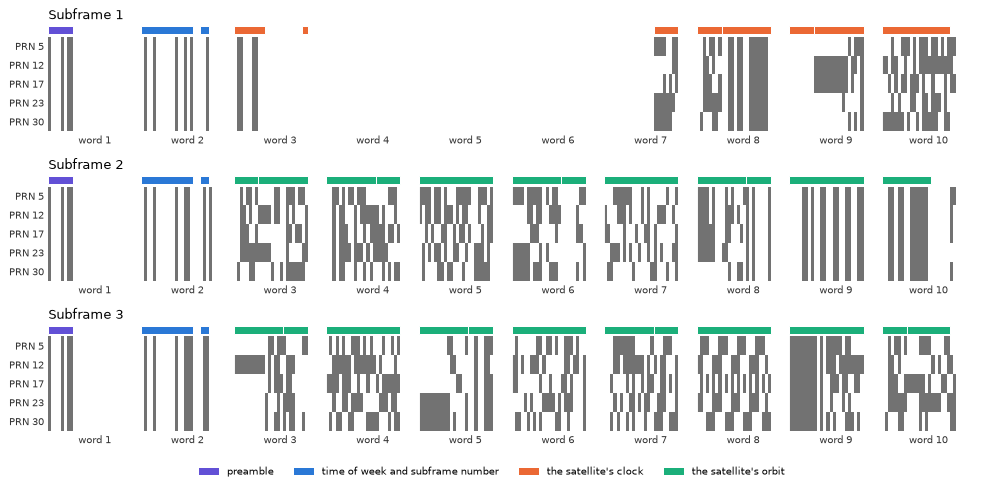

In [45]:
def fig_subframes():
    """The decoded data bits of the three subframes, all satellites one above the other."""
    fig, axs = plt.subplots(3, 1, figsize=(11, 5.4))
    kind_colour = {'sync': VIOLET, 'time': BLUE, 'clock': ORANGE, 'orbit': AQUA}
    clock = {'week', 't_gd', 'iodc', 't_oc', 'a_f2', 'a_f1', 'a_f0'}
    for number, ax in zip((1, 2, 3), axs):
        rows = []
        for prn in FOUND:
            sf = next(sf for sf in SUBFRAMES[prn].values() if sf['number'] == number)
            rows.append(sf['data'])
        image = np.array(rows, float)
        image[:, [30 * w + j for w in range(10) for j in range(24, 30)]] = np.nan       # parity positions: blank
        ax.imshow(image, aspect='auto', cmap='Greys', vmin=0, vmax=1.6, extent=[0, 300, len(FOUND), 0],
                  interpolation='nearest')
        spans = [('sync', 1, 8), ('time', 31, 17), ('time', 50, 3)]
        spans += [('clock' if name in clock else 'orbit', first, n)
                  for name, subframe, parts, *_ in FIELDS if subframe == number for first, n in parts]
        for kind, first, n in spans:
            ax.add_patch(Rectangle((first - 1, -0.55), n, 0.4, fc=kind_colour[kind], ec='white', lw=0.8, clip_on=False))
        for w in range(1, 10):
            ax.axvline(30 * w, color='white', lw=1.5)
        ax.set_yticks(np.arange(len(FOUND)) + 0.5, [f'PRN {p}' for p in FOUND], fontsize=8)
        ax.set_xticks(np.arange(10) * 30 + 15, [f'word {w}' for w in range(1, 11)], fontsize=8)
        ax.tick_params(length=0)
        ax.set_title(f'Subframe {number}', pad=14)
        for s in ax.spines.values():
            s.set_visible(False)
    handles = [Rectangle((0, 0), 1, 1, fc=c) for c in kind_colour.values()]
    fig.legend(handles, ['preamble', 'time of week and subframe number', "the satellite's clock", "the satellite's orbit"],
               loc='lower center', ncol=4, fontsize=8)
    fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

fig_subframes()

Each row is one satellite, each dark cell a data bit equal to 1 (after the decoding above, so inverted satellites look like the others; the six parity bits of each word are left blank). The coloured bands recall the layout of section 1.4.

The picture shows what kind of information each part is. The preamble and the **time of week are identical for all five satellites**: they all say the same time, because they all run on GPS time. The clock and orbit fields differ from row to row: each satellite describes itself.

## 4.5 Decoding: from bits to numbers

The last step is bookkeeping. For each field of the table `FIELDS` we collect its bits, read them as an integer (two's complement if the field is signed) and multiply by the value of one unit.

In [46]:
def unpack(subframe):
    """The fields of a decoded subframe, as numbers."""
    values = {}
    for name, number, parts, signed, unit, *_ in FIELDS:
        if number == subframe['number']:
            bits = [b for first, n in parts for b in subframe['data'][first - 1:first - 1 + n]]
            values[name] = from_bits(bits, signed) * unit
    return values

EPH = {}                                    # what the receiver knows about each satellite, from its message alone
for prn in FOUND:
    EPH[prn] = {}
    for sf in SUBFRAMES[prn].values():
        EPH[prn].update(unpack(sf))

prn = FOUND[0]
rows = [f'| {name} | {number} | {sum(n for _, n in parts)} | {EPH[prn][name]:.12g} | {unit_name} | {meaning} |'
        for name, number, parts, signed, unit, unit_name, meaning in FIELDS]
display(Markdown(f'**Decoded from the signal of PRN {prn}**\n\n| field | subframe | bits | value | unit | meaning |\n'
                 '|---|---|---|---|---|---|\n' + '\n'.join(rows)))

identical = all(EPH[prn][name] == TRUE_EPH[prn][name] for prn in FOUND for name, *_ in FIELDS)
print(f'Check against the simulation: all {len(FIELDS)} fields of all {len(FOUND)} satellites are exactly the values '
      f'that were transmitted: {identical}')
for prn in FOUND:
    first = min(SUBFRAMES[prn])
    sf = SUBFRAMES[prn][first]
    print(f'PRN {prn:2}: subframe {sf["number"]} starts at bit {first} of our stream; '
          f'it says the next subframe starts at {sf["tow_next"]} s of the week')

**Decoded from the signal of PRN 5**

| field | subframe | bits | value | unit | meaning |
|---|---|---|---|---|---|
| week | 1 | 10 | 396 | weeks | week number, modulo 1024 |
| t_gd | 1 | 8 | -6.053596735e-09 | s | delay of L1 inside the satellite |
| iodc | 1 | 10 | 45 |  | issue number of the clock data |
| t_oc | 1 | 16 | 223200 | s | reference time of the clock correction |
| a_f2 | 1 | 8 | 0 | s/s² | clock drift rate |
| a_f1 | 1 | 16 | 2.6147972676e-12 | s/s | clock drift |
| a_f0 | 1 | 22 | 0.000150168780237 | s | clock offset |
| iode | 2 | 8 | 45 |  | issue number of the ephemeris |
| c_rs | 2 | 16 | 51.6875 | m | radius correction (sine) |
| delta_n | 2 | 16 | 4.91163316066e-09 | rad/s | correction to the mean motion |
| m_0 | 2 | 32 | 0.367250435283 | rad | mean anomaly at the reference time |
| c_uc | 2 | 16 | -3.89292836189e-06 | rad | along-track correction (cosine) |
| e | 2 | 32 | 0.0060999999987 |  | eccentricity |
| c_us | 2 | 16 | -5.57117164135e-06 | rad | along-track correction (sine) |
| sqrt_a | 2 | 32 | 5153.64999962 | √m | square root of the semi-major axis |
| t_oe | 2 | 16 | 223200 | s | reference time of the ephemeris |
| c_ic | 3 | 16 | 5.02914190292e-08 | rad | inclination correction (cosine) |
| omega_0 | 3 | 32 | -3.05982048786 | rad | longitude of the ascending node |
| c_is | 3 | 16 | 1.80676579475e-07 | rad | inclination correction (sine) |
| i_0 | 3 | 32 | 0.963421747023 | rad | inclination |
| c_rc | 3 | 16 | 254.03125 | m | radius correction (cosine) |
| omega | 3 | 32 | 0.698131700148 | rad | argument of perigee |
| omega_dot | 3 | 24 | -7.34316301507e-09 | rad/s | rate of the node longitude |
| iode_3 | 3 | 8 | 45 |  | issue number again (must match) |
| i_dot | 3 | 14 | 3.43942898031e-10 | rad/s | rate of the inclination |

Check against the simulation: all 25 fields of all 5 satellites are exactly the values that were transmitted: True
PRN  5: subframe 1 starts at bit 10 of our stream; it says the next subframe starts at 221406 s of the week
PRN 12: subframe 1 starts at bit 10 of our stream; it says the next subframe starts at 221406 s of the week
PRN 17: subframe 1 starts at bit 10 of our stream; it says the next subframe starts at 221406 s of the week
PRN 23: subframe 1 starts at bit 10 of our stream; it says the next subframe starts at 221406 s of the week
PRN 30: subframe 1 starts at bit 10 of our stream; it says the next subframe starts at 221406 s of the week


The receiver now holds, for each satellite, the 16 numbers of its orbit and those of its clock, recovered bit for bit from a signal that was invisible in the samples.

It also holds a time stamp. Each satellite says when its next subframe starts, so the subframe we decoded started 6 s before that. We know at which bit of our stream that subframe starts, therefore at which code period, therefore at which position in the recording. **One point of the recording is now labelled with the satellite's time, in seconds of the week.**

**Where we are.** Everything needed for a position has been extracted. From the message: where each satellite is, and what time it was sending. From tracking: the fine timing of each code period. Part 5 puts the two together.

# Part 5. From the message and the code timing to a position

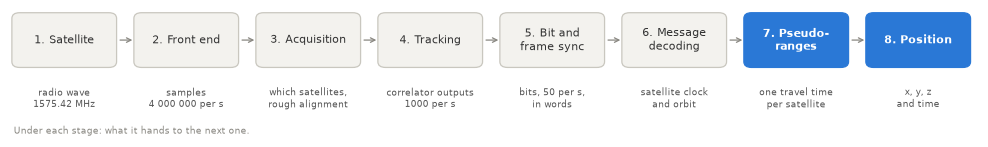

In [47]:
pipeline_map(7, 8)

## 5.1 Reading five clocks at the same instant

Section 2.3 reduced the whole problem to one quantity per satellite: $t^{sv}(t)$, the time shown by the satellite's clock when the signal now arriving left it. We can now read it, at any instant of the recording, by putting together everything the previous stages produced. It works like reading a clock with several hands:

| hand | what it counts | one step | who provides it |
|---|---|---|---|
| time of week | subframes | 6 s | the message (4.5) |
| bit number in the subframe | bits | 20 ms | frame synchronisation (4.3) |
| code period in the bit | code periods | 1 ms | bit synchronisation (4.1) |
| position in the code period | chips and fractions | down to a few ns | the code loop (3.4) |

The first three are whole numbers: they are either right or wrong, and the parity check makes sure they are right. All the precision comes from the last one, the code timing `begin[k]` delivered by tracking.

In practice: the message told us at which satellite time one particular subframe started; that subframe starts at a known code period $k$; so every code period can be labelled with a satellite time, 1 ms apart. For an instant that falls between two labels, we interpolate.

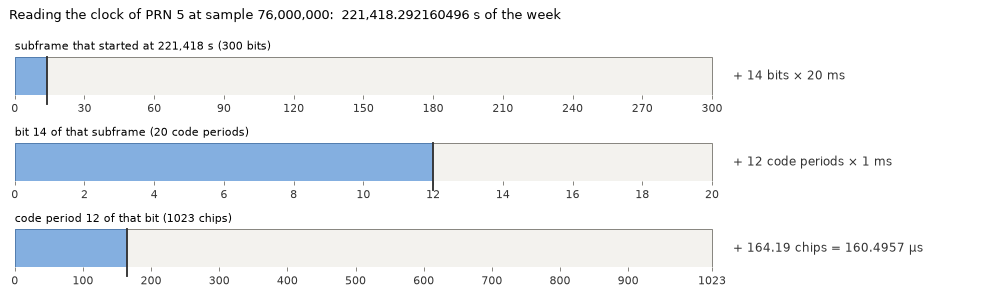

| satellite | its clock, read at the same instant | behind the most advanced by | which is |
|---|---|---|---|
| 5 | 221,418.292160496 s | 0.000000 ms | 0.000 km |
| 12 | 221,418.285798194 s | 6.362302 ms | 1,907.370 km |
| 17 | 221,418.286291493 s | 5.869002 ms | 1,759.483 km |
| 23 | 221,418.281240224 s | 10.920272 ms | 3,273.815 km |
| 30 | 221,418.280659394 s | 11.501102 ms | 3,447.944 km |

In [48]:
MEASURE_AT = 76_000_000         # the instant chosen for the measurement: this sample (19 s into the recording)

# Label the code periods of each satellite with satellite time, from one decoded subframe
PERIOD_0_TIME = {}
for prn in FOUND:
    s = min(SUBFRAMES[prn])                                  # a decoded subframe starts at bit s of our stream,
    k = BIT_START[prn] + 20 * s                              # that is, at code period k,
    PERIOD_0_TIME[prn] = (SUBFRAMES[prn][s]['tow_next'] - 6) - k * T_CODE    # and at this satellite time

def satellite_time(prn, sample):
    """What the clock of a satellite showed when the signal now at `sample` (a position in the recording) left it."""
    begin = TRACK[prn]['begin']
    k = np.searchsorted(begin, sample, side='right') - 1     # the code period that contains this instant
    fraction = (sample - begin[k]) / (begin[k + 1] - begin[k])   # how far into that period
    return PERIOD_0_TIME[prn] + (k + fraction) * T_CODE

def fig_clock_reading(prn=5):
    t = satellite_time(prn, MEASURE_AT)
    subframe = 6 * (t // 6)
    bit = int((t - subframe) // T_BIT)
    period = int((t - subframe - bit * T_BIT) // T_CODE)
    fraction = (t - subframe - bit * T_BIT) / T_CODE - period
    rows = [(f'subframe that started at {subframe:,.0f} s', 300, bit, 'bits', f'+ {bit} bits × 20 ms'),
            (f'bit {bit} of that subframe', 20, period, 'code periods', f'+ {period} code periods × 1 ms'),
            (f'code period {period} of that bit', 1023, fraction * 1023, 'chips',
             f'+ {fraction * 1023:.2f} chips = {fraction * 1e3:.4f} µs')]
    fig, axs = plt.subplots(3, 1, figsize=(11, 3.3))
    for ax, (title, length, value, unit, text) in zip(axs, rows):
        ax.add_patch(Rectangle((0, 0), length, 1, fc='#f3f2ee', ec=GREY, lw=0.8))
        ax.add_patch(Rectangle((0, 0), value, 1, fc=SAT_COLOUR[prn], alpha=0.55, lw=0))
        ax.plot([value, value], [-0.25, 1.0], color=INK, lw=1.5, clip_on=False)
        ax.set_xlim(0, length * 1.38); ax.set_ylim(0, 1); ax.set_yticks([])
        ax.set_xticks(np.r_[np.arange(0, 901, 100), 1023] if length == 1023 else np.linspace(0, length, 11))
        ax.text(length * 1.03, 0.5, text, va='center', fontsize=9.5, color=INK)
        ax.set_title(f'{title} ({length} {unit})', fontsize=9)
        for s in ax.spines.values():
            s.set_visible(False)
    fig.suptitle(f'Reading the clock of PRN {prn} at sample {MEASURE_AT:,}:  {t:,.9f} s of the week',
                 x=0.01, ha='left', fontsize=10.5)
    fig.tight_layout(); plt.show()

fig_clock_reading()

T_SAT = {prn: satellite_time(prn, MEASURE_AT) for prn in FOUND}
latest = max(T_SAT.values())
rows = [f'| {prn} | {T_SAT[prn]:,.9f} s | {(latest - T_SAT[prn]) * 1e3:.6f} ms | '
        f'{(latest - T_SAT[prn]) * C_LIGHT / 1e3:,.3f} km |' for prn in FOUND]
display(Markdown('| satellite | its clock, read at the same instant | behind the most advanced by | which is |\n'
                 '|---|---|---|---|\n' + '\n'.join(rows)))

At one and the same instant, the five signals show five different times. The differences are differences of travel time: the signal that shows the latest time comes from the closest satellite, and one that shows a time 10 ms earlier has come from 3000 km further away.

## 5.2 Pseudoranges

If the receiver had a perfect clock showing GPS time $t_{rx}$ at that instant, each travel time would be $t_{rx} - t^{sv}$, each distance $c\,(t_{rx} - t^{sv})$, and three satellites would be enough for three coordinates.

It has no such clock. Its only clock is its sample counter, and nobody told it when sample 0 was taken. An error of one microsecond would be 300 m on every distance. So the receiver sets its clock roughly (here: assume the closest satellite is 70 ms away) and treats the error $\delta t$ of that clock as a **fourth unknown**. The quantities

$$\rho_i = c\,\big(t_{rx} - t_i^{sv}\big)$$

are called **pseudoranges**: distances, all wrong by the same unknown amount $c\,\delta t$. This is why a position needs four satellites and not three.

Two corrections make the pseudoranges exact:

- **The satellite's clock is not exactly on GPS time.** Subframe 1 gives its error (the polynomial $a_{f0}, a_{f1}, a_{f2}$), to which a small relativistic term is added, which depends on where the satellite is on its slightly elliptical orbit. We subtract the error from $t^{sv}$ and get the true time of transmission $t^{tx}$. These errors reach hundreds of microseconds (hundreds of kilometres), so this is not a refinement.
- **The Earth turns while the signal flies.** The ephemeris gives the satellite's position in axes fixed to the Earth *at the time of transmission*. About 75 ms later, at reception, those axes have turned by a tiny angle (5 millionths of a radian), enough to change the computed distances by up to 30 m. We turn the satellite's coordinates by that angle.

## 5.3 Four unknowns, solved by least squares

For each satellite, with $\mathbf{s}_i$ its position at the time of transmission (from `sat_position`, the same function as in part 2, now fed with the *decoded* ephemeris) and $\mathbf{r}$ the receiver's position:

$$c\,\big(t_{rx} - t_i^{tx}\big) = \lVert \mathbf{s}_i - \mathbf{r} \rVert + c\,\delta t$$

Five equations, four unknowns ($x, y, z$ and $c\,\delta t$), and the equations are not linear because of the distance. The standard method is Newton's: start from a guess, replace each equation by its tangent (a linear equation in the correction to the guess), solve the linear system in the least-squares sense, correct the guess, and repeat. The row of the linear system for satellite $i$ is $[-\mathbf{u}_i,\; 1]$, with $\mathbf{u}_i$ the unit vector from the receiver towards the satellite.

The starting guess does not matter much. We start at the centre of the Earth.

In [49]:
def solve_position(t_sat, t_rx):
    """Position (ECEF, m) and receiver clock error (s) from the satellite times read at one instant,
    when the receiver's own clock shows t_rx. Also returns the successive estimates."""
    estimate = np.zeros(4)                          # x, y, z and c x clock error, all in metres
    history = []
    for _ in range(8):
        rows, misfit = [], []
        for prn, t_sv in t_sat.items():
            eph = EPH[prn]
            t_tx = t_sv                             # true time of transmission: remove the satellite clock error
            for _ in range(2):
                pos, E = sat_position(eph, t_tx)
                t_tx = t_sv - sat_clock_error(eph, t_tx, E)
            pos, _ = sat_position(eph, t_tx)
            travel = (t_rx - estimate[3] / C_LIGHT) - t_tx
            pos = turn_with_earth(pos, OMEGA_E * travel)
            distance = np.linalg.norm(pos - estimate[:3])
            rows.append(np.r_[(estimate[:3] - pos) / distance, 1.0])
            misfit.append(C_LIGHT * (t_rx - t_tx) - (distance + estimate[3]))
        estimate = estimate + np.linalg.lstsq(np.array(rows), np.array(misfit), rcond=None)[0]
        history.append(estimate.copy())
    return estimate[:3], estimate[3] / C_LIGHT, history

# The receiver's clock: set once, by assuming that the closest satellite is 70 ms away
RX_CLOCK_AT_0 = max(T_SAT.values()) + 0.070 - MEASURE_AT / FS       # what it shows at sample 0
rx_clock = lambda sample: RX_CLOCK_AT_0 + sample / FS

position, clock_error, history = solve_position(T_SAT, rx_clock(MEASURE_AT))

rows = [f'| {i + 1} | {np.linalg.norm(h[:3] - TRUE_POS):,.1f} m | {h[3] / C_LIGHT * 1e3:.6f} ms |'
        for i, h in enumerate(history[:6])]
display(Markdown('| iteration | distance from the true position | receiver clock error found |\n|---|---|---|\n'
                 + '\n'.join(rows)))
lat, lon, height = ecef_to_lla(position)
east, north, up = east_north_up(*TRUE_LLA[:2]) @ (position - TRUE_POS)
true_clock_error = RX_CLOCK_AT_0 - T_START
print(f'Computed position: {lat:.6f}° N, {lon:.6f}° E, height {height:.1f} m')
print(f'True position:     {TRUE_LLA[0]:.6f}° N, {TRUE_LLA[1]:.6f}° E, height {TRUE_LLA[2]:.1f} m')
print(f'Error: {east:+.1f} m east, {north:+.1f} m north, {up:+.1f} m up')
print(f'Receiver clock: found {clock_error * 1e3:.6f} ms fast; in truth {true_clock_error * 1e3:.6f} ms '
      f'(difference {(clock_error - true_clock_error) * 1e9:+.1f} ns)')

| iteration | distance from the true position | receiver clock error found |
|---|---|---|
| 1 | 1,208,136.7 m | 6.417198 ms |
| 2 | 33,793.4 m | 2.290248 ms |
| 3 | 34.9 m | 2.160612 ms |
| 4 | 7.4 m | 2.160507 ms |
| 5 | 7.4 m | 2.160507 ms |
| 6 | 7.4 m | 2.160507 ms |

Computed position: 51.477931° N, -0.001505° E, height 52.6 m
True position:     51.477900° N, -0.001500° E, height 46.0 m
Error: -0.4 m east, +3.4 m north, +6.6 m up
Receiver clock: found 2.160507 ms fast; in truth 2.160496 ms (difference +11.0 ns)


From the centre of the Earth, the solution lands on the right spot in a handful of iterations. The receiver has found where it is, to within a few metres, **and what time it is, to within about ten nanoseconds**: a GNSS receiver is also a very good clock.

Nothing in this result came from the simulation's knowledge. The receiver used the samples, the 32 codes, and the format of the message. The true position was used only in the last lines, to print the error.

## 5.4 How good is it?

One position is one draw. The measurement can be repeated at any instant of the recording, so here are 190 positions, one every 0.1 s.

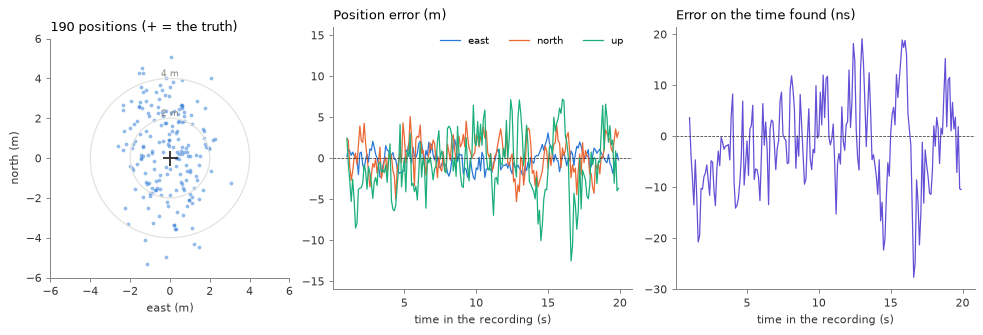

Horizontal error: 2.4 m rms.  Vertical: 3.7 m rms.
Average of the 190 positions: -0.13 m east, +0.34 m north, -0.84 m up of the truth.
Geometry: 1 m of timing noise on every satellite gives 1.5 m horizontally and 2.0 m vertically.


In [50]:
def fig_positions():
    to_enu = east_north_up(*TRUE_LLA[:2])
    instants = np.arange(1.0, 19.95, 0.1)
    errors, clocks = [], []
    for t in instants:
        sample = int(t * FS)
        pos, clk, _ = solve_position({prn: satellite_time(prn, sample) for prn in FOUND}, rx_clock(sample))
        errors.append(to_enu @ (pos - TRUE_POS)); clocks.append((clk - true_clock_error) * 1e9)
    errors, clocks = np.array(errors), np.array(clocks)
    fig, (ax, az, aw) = plt.subplots(1, 3, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1, 1.25, 1.25]))
    ax.scatter(errors[:, 0], errors[:, 1], s=9, color=BLUE, alpha=0.5, lw=0)
    for radius in (2, 4):
        ax.add_patch(plt.Circle((0, 0), radius, fc='none', ec=LIGHT, lw=1))
        ax.text(0, radius + 0.1, f'{radius} m', ha='center', fontsize=7.5, color=GREY)
    ax.plot(0, 0, '+', color=INK, ms=12, mew=1.5)
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect('equal')
    ax.set_xlabel('east (m)'); ax.set_ylabel('north (m)'); ax.set_title('190 positions (+ = the truth)')
    for j, (name, colour) in enumerate([('east', BLUE), ('north', ORANGE), ('up', AQUA)]):
        az.plot(instants, errors[:, j], color=colour, lw=1, label=name)
    az.axhline(0, color=INK, lw=0.6, ls='--'); az.set_xlabel('time in the recording (s)')
    az.set_ylim(-16, 16); az.set_title('Position error (m)'); az.legend(loc='upper right', ncol=3, fontsize=8)
    aw.plot(instants, clocks, color=VIOLET, lw=1)
    aw.axhline(0, color=INK, lw=0.6, ls='--'); aw.set_xlabel('time in the recording (s)')
    aw.set_title('Error on the time found (ns)')
    fig.tight_layout(); plt.show()
    return errors

errors = fig_positions()
horizontal = np.hypot(errors[:, 0], errors[:, 1])
print(f'Horizontal error: {np.sqrt((horizontal ** 2).mean()):.1f} m rms.  Vertical: {errors[:, 2].std():.1f} m rms.')
print(f'Average of the 190 positions: {errors[:, 0].mean():+.2f} m east, {errors[:, 1].mean():+.2f} m north, '
      f'{errors[:, 2].mean():+.2f} m up of the truth.')

# How the geometry turns timing noise into position noise
rows = []
for prn in FOUND:
    _, pos = signal_arriving(EPH[prn], rx_clock(MEASURE_AT) - clock_error, position)
    rows.append(np.r_[(position - pos) / np.linalg.norm(position - pos), 1.0])
Q = np.linalg.inv(np.array(rows).T @ np.array(rows))
Q_enu = east_north_up(*TRUE_LLA[:2]) @ Q[:3, :3] @ east_north_up(*TRUE_LLA[:2]).T
print(f'Geometry: 1 m of timing noise on every satellite gives {np.sqrt(Q_enu[0, 0] + Q_enu[1, 1]):.1f} m horizontally '
      f'and {np.sqrt(Q_enu[2, 2]):.1f} m vertically.')

The positions scatter by a few metres around the truth, and their average is close to it: the errors are noise, not a bias. They come from the code timing, which section 3.5 showed to be good to 1 to 3 m per satellite, multiplied by a factor that depends only on where the satellites are in the sky (the *dilution of precision*, printed above). The vertical is worse than the horizontal, as always in GNSS: all the satellites are above the receiver, none below.

The errors change slowly because the code loop averages over about 200 ms: positions closer together than that are not independent.

# Summary: the chain, with its numbers

| | Stage | Operation on the signal | What comes out, in this lecture |
|---|---|---|---|
| 1 | Satellite | code × data × carrier, all timed by one clock | a signal 15 dB under the noise at the antenna |
| 2 | Front end | mix to 0 Hz, sample at 4 MHz, 8 bits | 80 million complex samples (160 MB) that look like noise |
| 3 | Acquisition | correlate with each code at every delay and frequency | 5 satellites; delay to ¼ chip, Doppler to a few Hz |
| 4 | Tracking | correlate each code period at one point; two feedback loops keep it on the peak | per satellite, 1000 complex numbers per second and the start of each code period to a few ns |
| 5 | Bit and frame sync | count sign flips modulo 20; add 20 ms; find the preamble; check parity | 970 bits per satellite, no errors; 3 complete subframes |
| 6 | Decoding | cut the subframes into fields | 25 numbers per satellite: its clock and its orbit |
| 7 | Pseudoranges | read each satellite clock at one instant: message + bit + code period + code phase | 5 times of transmission |
| 8 | Position | compute the satellite positions; solve 4 unknowns by least squares | a position to a few metres, the time to about ten nanoseconds |

**The same idea, three times.** Signal adds up in step, noise does not. Summing 4000 samples lifts the signal out of the noise (correlation, +36 dB). Summing 20 correlator outputs makes the bits certain (+13 dB). Averaging 200 code-loop measurements turns a quarter-chip alignment into a timing of a few nanoseconds.

**The code does two jobs.** It hides and separates the signals (spreading, CDMA), and it is the ruler that measures time (the sharp correlation peak). The data only says how to read the ruler: which tick is which second, and where the satellite was.

## What a real receiver has to deal with as well

The simulation is complete but kind. A real signal adds:

- **The atmosphere.** The ionosphere delays the signal by 2 to 30 m, the troposphere by 2 to 20 m, more for low satellites. Models (the ionosphere model is in subframe 4) remove most of it.
- **An imperfect receiver oscillator.** It shifts all the Doppler frequencies by the same amount (several kHz for a cheap oscillator) and makes the sample rate slightly wrong. The acquisition search must be wider, and the receiver clock error becomes a drifting quantity. The four-unknown solution absorbs it at each instant.
- **Reflections (multipath).** Copies of the signal arriving late distort the correlation triangle and bias the code loop by metres, in cities by tens of metres.
- **Weak and interrupted signals.** Indoors or under trees, 1 ms of correlation is not enough: receivers add up coherently over 20 ms and more, which needs the bit boundaries, and they must detect loss of lock and re-acquire.
- **Time.** Here the recording conveniently started 0.7 s before a subframe 1. In general, collecting subframes 1 to 3 takes up to 36 s, which is why a receiver that has been off for hours needs half a minute before its first position.
- **More signals.** Galileo, BeiDou, GLONASS and the modern GPS signals (L2C, L5) use longer codes, data-free "pilot" components and error-correcting codes. Every stage of this lecture has its counterpart there.

## Going further

- *IS-GPS-200*, the GPS interface specification: the code generators (section 3), the message format and parity (section 20.3.5), the satellite position algorithm (table 20-IV).
- E. Kaplan and C. Hegarty, *Understanding GPS/GNSS: Principles and Applications*: loops, discriminators and their noise.
- K. Borre et al., *A Software-Defined GPS and Galileo Receiver*: a complete receiver in the same spirit as this notebook.
- P. Misra and P. Enge, *Global Positioning System: Signals, Measurements, and Performance*: the position solution and its errors.
- In this repository, the same stages run on real recordings from a HackRF One: `bassanite/acquisition.py` and `bassanite/tracking.py` (stages 3 and 4 of this lecture), with the web interface in `ui/`. The message decoder of part 4 (`find_subframes`, `read_subframe`, `unpack`) also reads real GPS bits as it is: on the bits tracked from a 60 s recording, every word of four satellites passes the parity check.